# Entrega 3 · Modelado de etapas del sueño · Revisión

**Estado: secciones activas 4.1–4.7 ejecutadas; test histórico comparado sin reajustes.**

Se completa la ronda acotada de hiperparámetros, representaciones, historia y SMOTE para dos candidatos:
selección mediante pacientes separados y mediante epochs mezclados. Ambos utilizan wearable + PSG.
Los 60 pacientes de desarrollo intervienen en selección; los 16 reservados se comparan únicamente después de congelar candidatos.

Las salidas previas de Kaggle hasta 4.5.2 se preservan como evidencia de ejecución con `N_JOBS=2`.
Si sus exportaciones completas no están disponibles, se repite el desarrollo con `N_JOBS=-1` desde un kernel limpio,
registrando fuentes, versiones, folds, configuraciones y resultados ejecutados/reutilizados. No comparar tiempos entre entornos como efecto del modelo.

Ejecutar los bloques activos 4.1–4.7. **No ejecutar 4.8:** conserva exactamente código y salidas históricos del modelo anterior.
4.7 evalúa los dos candidatos sobre los mismos 16 pacientes reservados, sin pedir nuevos CSV ni sobrescribir el test anterior.
El test ya fue consultado: comparación posterior, no nueva evaluación independiente. No reajustar después de consultarlo.
Salidas en `output/modelado_revision/` local o `/kaggle/working/modelado_revision/`.


## 4.1. Datos, test histórico y particiones

Se conserva la reserva por paciente y semilla 42: 45.011 epochs de 60 pacientes para desarrollo; 11.839 epochs de 16 pacientes ya evaluados históricamente. La identidad, el tiempo y Sleep_Stage quedan fuera de X.

En desarrollo se utilizan cinco folds de StratifiedGroupKFold por paciente y cinco de StratifiedKFold con epochs mezclados. Cada protocolo reutiliza sus propias particiones en todos los modelos. La estratificación intenta conservar proporciones; no balancea las clases. Se comprueba la cobertura de las cinco etapas y que cada epoch tenga una sola predicción de validación.

Pacientes separados exige personas distintas en entrenamiento y validación. Epochs mezclados admite pacientes compartidos y observaciones próximas. El test histórico queda apartado de los nuevos ajustes. No se realiza evaluación cronológica; los retardos causales de señales se mantienen como características.


In [1]:
from pathlib import Path
import hashlib
import copy
import sys
import importlib.metadata
import importlib.util
import json
import platform
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
from IPython import get_ipython
if getattr(get_ipython(), 'kernel', None) is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
    classification_report, ConfusionMatrixDisplay, roc_curve, roc_auc_score)
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Instalación local opcional; en Kaggle se usa el entorno del notebook.
for carpeta_dependencias in [Path('output/modelado-deps'), Path('../output/modelado-deps')]:
    if carpeta_dependencias.is_dir():
        sys.path.insert(0, str(carpeta_dependencias.resolve()))


def mostrar_tabla(tabla, titulo=None):
    """HTML completo, sin límites globales de pandas ni reducción de fuente."""
    if titulo:
        display(Markdown(f'**{titulo}**'))
    tiene_indice = not isinstance(tabla.index, pd.RangeIndex)
    html = tabla.to_html(index=tiene_indice, border=0, max_rows=None, max_cols=None,
                         float_format=lambda v: f'{v:.4f}', na_rep='—', escape=True)
    display(HTML('<div style="overflow-x:auto; margin-bottom:1em">' + html + '</div>'))

def nombre_protocolo(protocolo):
    return {'pacientes': 'Pacientes separados', 'epochs': 'Epochs mezclados'}[protocolo]

def nombre_algoritmo(algoritmo):
    return {'Baseline': 'Referencia trivial', 'Logistica': 'Regresión logística',
            'RF': 'Random Forest', 'XGB': 'XGBoost'}.get(algoritmo, algoritmo)

SEMILLA = 42
N_SPLITS = 5
N_JOBS = -1  # Configuración original: utilizar los núcleos de CPU disponibles.
ETAPAS = ['W', 'N1', 'N2', 'N3', 'R']
CLAVES = ['patient_id', 'epoch']
EN_KAGGLE = platform.system() != 'Windows' and Path('/kaggle/input').is_dir()
SALIDA = Path('/kaggle/working/modelado_revision') if EN_KAGGLE else Path('output/modelado_revision')
SALIDA.mkdir(parents=True, exist_ok=True)

def guardar_json(ruta, objeto):
    ruta.write_text(json.dumps(objeto, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

def buscar_csv(nombre):
    # Una ubicación explícita evita elegir silenciosamente entre copias Kaggle.
    locales = [Path('etl_v1') / nombre, Path('../etl_v1') / nombre]
    archivos = [p.resolve() for p in locales if p.exists()]
    if not archivos and EN_KAGGLE:
        archivos = list(Path('/kaggle/input').rglob(nombre))
    archivos = list(dict.fromkeys(archivos))
    if len(archivos) != 1:
        raise FileNotFoundError(f'{nombre}: se esperaba una única fuente; encontradas {archivos}')
    return archivos[0]

ruta_base = buscar_csv('dataset_epochs_v1.csv')
ruta_candidato = buscar_csv('dataset_modelado_candidato.csv')
base = pd.read_csv(ruta_base, low_memory=False)
candidato = pd.read_csv(ruta_candidato, low_memory=False)
versiones = {'python': platform.python_version(), **{
    paquete: importlib.metadata.version(paquete)
    for paquete in ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'imbalanced-learn']}}
versiones['xgboost'] = (importlib.metadata.version('xgboost')
    if importlib.util.find_spec('xgboost') else 'no instalado')
guardar_json(SALIDA / 'versiones.json', versiones)
mostrar_tabla(pd.DataFrame([{'fuente': 'ETL', 'epochs': len(base), 'columnas': base.shape[1]},
                      {'fuente': 'candidato', 'epochs': len(candidato), 'columnas': candidato.shape[1]}]))

def agregar_historia(entradas, tabla, minutos):
    """Solo pasado exacto dentro de segmentos de epochs contiguos de 30 s."""
    if not entradas.index.equals(tabla.index):
        raise ValueError('Historia desalineada')
    salida = entradas.copy()
    disponibilidad = []
    for _, grupo in tabla.groupby('patient_id', sort=False):
        orden = grupo.sort_values('tiempo_relativo_segundos').index
        tiempos = tabla.loc[orden, 'tiempo_relativo_segundos']
        if tiempos.duplicated().any() or not np.isfinite(tiempos).all():
            raise ValueError('Tiempos inválidos para historia')
    ordenada = tabla.sort_values(['patient_id', 'tiempo_relativo_segundos'])
    salto = ordenada.groupby('patient_id').tiempo_relativo_segundos.diff()
    segmentos = (~np.isclose(salto.to_numpy(), 30.0, atol=1e-6, rtol=0)).cumsum()
    grupos = ordenada.assign(segmento=segmentos).groupby(['patient_id','segmento'], sort=False)
    for minuto in minutos:
        pasos = int(round(minuto * 2))
        if pasos <= 0 or not np.isclose(pasos * 30, minuto * 60):
            raise ValueError('Retardo no compatible con epochs de 30 segundos')
        columnas = [f'{c}__lag{minuto}m' for c in entradas]
        historia = pd.DataFrame(np.nan, index=entradas.index, columns=entradas.columns)
        for _, grupo in grupos:
            historia.loc[grupo.index] = entradas.loc[grupo.index].shift(pasos).to_numpy()
        historia.columns = columnas
        indicador = f'historia_disponible__lag{minuto}m'
        salida = pd.concat([salida, historia], axis=1)
        salida[indicador] = historia.notna().all(axis=1).astype(int)
        disponibilidad.append(dict(minutos=minuto, disponibles=int(salida[indicador].sum()),
            faltantes=int((salida[indicador] == 0).sum()), fraccion=float(salida[indicador].mean())))
    return salida, pd.DataFrame(disponibilidad)

# Si no hay exportaciones completas y compatibles, se vuelven a ejecutar las pruebas.
# Solo se reutilizan artefactos de revisión con datos, folds, parámetros y entorno idénticos.


fuente,epochs,columnas
ETL,56850,128
candidato,56850,26


In [2]:
columnas_principal = [
    'HR_median', 'HR_std', 'TEMP_median', 'EDA_std',
    'C4-M1_std', 'F4-M1_std', 'O2-M1_std', 'Fp1-O2_std',
    'T3 - CZ_std', 'CZ - T4_std', 'CHIN_std', 'ECG_std',
    'SNORE_std', 'PTAF_std', 'FLOW_std', 'THORAX_std', 'ABDOMEN_std',
    'EOG_max_std', 'LEG_max_std', 'BVP_std_log1p',
    'EDA_median_log1p', 'ACC_axes_std_norm_log1p']
for nombre, tabla in [('ETL', base), ('candidato', candidato)]:
    if tabla[CLAVES + ['Sleep_Stage']].isna().any().any():
        raise ValueError(f'{nombre}: identidad u objetivo faltante')
    if tabla.duplicated(CLAVES).any():
        raise ValueError(f'{nombre}: claves repetidas')
    if not tabla.Sleep_Stage.isin(ETAPAS).all():
        raise ValueError(f'{nombre}: etapas inválidas')
base = base.sort_values(CLAVES).reset_index(drop=True)
candidato = candidato.sort_values(CLAVES).reset_index(drop=True)
if not base[CLAVES + ['Sleep_Stage']].equals(candidato[CLAVES + ['Sleep_Stage']]):
    raise ValueError('Los CSV no tienen la misma cohorte, claves y etiquetas. '
                     'Exportar ambos desde la misma ejecución; no se recortan ni reconstruyen datos.')
assert not set(columnas_principal) & set(CLAVES + ['Sleep_Stage', 'tiempo_relativo_segundos'])
if not np.isfinite(candidato[columnas_principal].to_numpy(dtype=float)).all():
    raise ValueError('Hay predictores faltantes o infinitos; revisar ETL.')

# Huella de ambos archivos: una asignación guardada no se reutiliza con otros datos.
def sha256_archivo(ruta):
    h = hashlib.sha256()
    with ruta.open('rb') as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b''):
            h.update(bloque)
    return h.hexdigest()
huella = {p.name: sha256_archivo(p) for p in [ruta_base, ruta_candidato]}
ruta_asignacion = SALIDA / 'asignacion_pacientes.json'
pacientes_test_congelados = [2, 6, 12, 14, 20, 30, 35, 37, 48, 50, 53, 56, 67, 83, 85, 88]
if ruta_asignacion.exists():
    asignacion = json.loads(ruta_asignacion.read_text(encoding='utf-8'))
    if asignacion['huella'] != huella or asignacion['semilla'] != SEMILLA:
        raise ValueError('Cambió la fuente/semilla: conservar las salidas anteriores y usar otra carpeta SALIDA.')
    pacientes_test = asignacion['pacientes_test']
else:
    pacientes_test = pacientes_test_congelados
    asignacion = {'huella': huella, 'semilla': SEMILLA, 'fraccion_pacientes_test': 0.2,
                  'pacientes_test': pacientes_test,
                  'exposicion_previa': 'EDA y comparaciones anteriores sobre la cohorte completa'}

if pacientes_test != pacientes_test_congelados:
    raise ValueError('La reserva difiere de la evaluación histórica; no cambiar pacientes.')
es_test = base.patient_id.isin(pacientes_test)
for nombre, tabla in [('desarrollo', base.loc[~es_test]), ('test', base.loc[es_test])]:
    if set(tabla.Sleep_Stage) != set(ETAPAS):
        raise ValueError(f'{nombre}: falta alguna etapa. Revisar cobertura antes de entrenar, sin elegir por desempeño.')
guardar_json(ruta_asignacion, asignacion)
asignacion_csv = base[CLAVES].assign(conjunto=np.where(es_test, 'test', 'desarrollo'))
asignacion_csv.to_csv(SALIDA / 'asignacion_epochs.csv', index=False)
dev = candidato.loc[~es_test].reset_index(drop=True)
base_dev = base.loc[~es_test].reset_index(drop=True)
test = candidato.loc[es_test].reset_index(drop=True)
assert not set(dev.patient_id) & set(test.patient_id)
assert len(dev) + len(test) == len(base)
y = dev.Sleep_Stage.map({e: i for i, e in enumerate(ETAPAS)}).to_numpy()
X = dev[columnas_principal]
folds = {
    'pacientes': list(StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEMILLA)
                      .split(X, y, dev.patient_id)),
    'epochs': list(StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEMILLA).split(X, y))}
controles, asignaciones_folds, pacientes_folds = [], [], []
for protocolo, rondas in folds.items():
    cobertura = np.zeros(len(dev), dtype=int)
    for fold, (tr, va) in enumerate(rondas, 1):
        assert not set(tr) & set(va)
        assert len(tr) + len(va) == len(dev)
        if protocolo == 'pacientes':
            assert not set(dev.iloc[tr].patient_id) & set(dev.iloc[va].patient_id)
        pacientes_folds.append({'protocolo': protocolo, 'Fold': fold,
            'Entrenamiento': dev.iloc[tr].patient_id.nunique(),
            'Validación': dev.iloc[va].patient_id.nunique(),
            'Compartidos': len(set(dev.iloc[tr].patient_id) & set(dev.iloc[va].patient_id))})
        cobertura[va] += 1
        asignaciones_folds.append(dev.iloc[va][CLAVES].assign(protocolo=protocolo, fold=fold))
        for conjunto, idx in [('entrenamiento', tr), ('validacion', va)]:
            if set(y[idx]) != set(range(5)):
                raise ValueError(f'{protocolo}, fold {fold}: cobertura incompleta')
            for codigo, etapa in enumerate(ETAPAS):
                controles.append(dict(protocolo=protocolo, fold=fold, conjunto=conjunto,
                    etapa=etapa, epochs=int((y[idx] == codigo).sum()),
                    pacientes=dev.iloc[idx].loc[y[idx] == codigo, 'patient_id'].nunique()))
    assert (cobertura == 1).all()
asignacion_actual = pd.concat(asignaciones_folds).reset_index(drop=True)
if (SALIDA / 'folds_validacion.csv').exists():
    pd.testing.assert_frame_equal(pd.read_csv(SALIDA / 'folds_validacion.csv'), asignacion_actual, check_dtype=False, obj='Folds previamente fijados')
asignacion_actual.to_csv(SALIDA / 'folds_validacion.csv', index=False)
pd.DataFrame(controles).to_csv(SALIDA / 'cobertura_folds.csv', index=False)

mostrar_tabla(asignacion_csv.groupby('conjunto').agg(Pacientes=('patient_id', 'nunique'))
              .rename_axis('Conjunto'), 'Reserva de pacientes')
pacientes_folds = pd.DataFrame(pacientes_folds)
pacientes_folds.to_csv(SALIDA / 'pacientes_por_fold.csv', index=False)
for protocolo in folds:
    tabla = pacientes_folds.loc[pacientes_folds.protocolo.eq(protocolo)].drop(columns='protocolo').reset_index(drop=True)
    mostrar_tabla(tabla, f'Pacientes por fold — {nombre_protocolo(protocolo)}')
print('Cobertura de las cinco etapas verificada. Detalle por etapa guardado en cobertura_folds.csv.')

# Estas huellas identifican exactamente los folds; las versiones se registran en 4.1.
huellas_folds = {p: hashlib.sha256(b''.join(
    np.asarray(idx, dtype='<i8').tobytes() for tr, va in rondas for idx in (tr, va)
)).hexdigest() for p, rondas in folds.items()}
guardar_json(SALIDA / 'huellas_folds.json', huellas_folds)


**Reserva de pacientes**

,Pacientes
Conjunto,
desarrollo,60
test,16


**Pacientes por fold — Pacientes separados**

Fold,Entrenamiento,Validación,Compartidos
1,49,11,0
2,47,13,0
3,48,12,0
4,47,13,0
5,49,11,0


**Pacientes por fold — Epochs mezclados**

Fold,Entrenamiento,Validación,Compartidos
1,60,60,60
2,60,60,60
3,60,60,60
4,60,60,60
5,60,60,60


Cobertura de las cinco etapas verificada. Detalle por etapa guardado en cobertura_folds.csv.


## 4.2. Configuraciones y reproducibilidad
DummyClassifier es el piso; logística es la referencia lineal. RF y XGBoost capturan
interacciones no lineales. Ninguno es ganador por definición. Semilla y núcleos controlan
reproducibilidad/costo, no se optimizan como capacidad predictiva.
Los hiperparámetros, sus efectos y las variaciones están documentados en
`docs/entrega-03/experimentos-hiperparametros.md`. No hay SMOTE inicial.


### Referencia trivial

Se utiliza `DummyClassifier` con la estrategia `most_frequent`: en cada fold identifica la etapa más frecuente del entrenamiento y la predice para todos los epochs de validación.

Este baseline establece una referencia mínima. Los modelos posteriores deberían mejorar su desempeño, especialmente en F1 macro y en el reconocimiento de las etapas minoritarias. Se evalúa con las mismas particiones y métricas que los demás candidatos.

### Regresión logística multiclase

Se utiliza regresión logística como referencia lineal para clasificar las cinco etapas. Las variables se estandarizan con `StandardScaler`, ajustado únicamente con el entrenamiento de cada fold.

Configuración inicial:

* `C=1.0`: controla la intensidad de la regularización, que penaliza coeficientes grandes para limitar ajustes demasiado específicos al entrenamiento. Un C menor aplica mayor regularización; uno mayor, menor. Se utiliza 1 como referencia inicial, sin considerarlo óptimo.
* `solver="lbfgs"`: algoritmo de optimización que encuentra los coeficientes del modelo. Permite ajustar la clasificación multiclase.
* `max_iter=2000`: máximo de iteraciones del optimizador. Si converge antes, se detiene antes. Este límite busca permitir que termine el ajuste; no garantiza mejores predicciones.
* `escalar=True`: activa la estandarización dentro del Pipeline. Cada variable se centra y divide por su desviación estándar calculada en entrenamiento.
* `usar_pesos=False`: define la referencia sin ponderación; también se entrena la alternativa con pesos. En 4.4 se compara también con pesos, manteniendo los demás parámetros.

### Random Forest

Random Forest combina árboles de decisión entrenados con variaciones en los datos y las características consideradas. Permite representar relaciones no lineales e interacciones entre señales.

Configuración inicial:

* `n_estimators=200`: cantidad de árboles del bosque. Se parte de 200 para obtener una primera referencia con un costo de ejecución acotado.
* `min_samples_leaf=2`: cada hoja debe contener al menos dos observaciones de entrenamiento. Limita hojas demasiado específicas, aunque no garantiza evitar el sobreajuste.
* `max_features="sqrt"`: en cada división se considera un subconjunto aleatorio de características cuyo tamaño depende de la raíz cuadrada del número de predictores. Favorece que los árboles sean diferentes entre sí.
* `escalar=False`: no se estandarizan las variables; los árboles realizan divisiones mediante umbrales por característica.
* `usar_pesos=False`: define la referencia sin ponderación; también se entrena la alternativa con pesos.

Opciones de ejecución:

* `random_state=SEMILLA`: fija la aleatoriedad para poder reproducir el experimento con los mismos datos y configuración.
* `n_jobs=N_JOBS`: permite utilizar los núcleos de CPU disponibles para paralelizar el trabajo.

### XGBoost

XGBoost aplica gradient boosting: incorpora árboles secuencialmente para reducir la función de pérdida del conjunto. Se evalúa como candidato para capturar relaciones no lineales entre las señales.

Configuración inicial:

* `objective="multi:softprob"`: define un problema de clasificación multiclase y permite obtener probabilidades para cada etapa.
* `num_class=5`: indica las cinco clases: W, N1, N2, N3 y R.
* `n_estimators=200`: establece 200 rondas de boosting. En clasificación multiclase, una ronda puede incorporar varios árboles.
* `max_depth=4`: limita la profundidad de los árboles. Se parte de árboles relativamente acotados para controlar complejidad y costo.
* `learning_rate=0.1`: reduce la contribución de cada ronda al conjunto. Valores menores suelen requerir más rondas para aprender.
* `subsample=0.8`: utiliza una muestra aleatoria del 80 % de las observaciones de entrenamiento en cada ronda.
* `colsample_bytree=0.8`: utiliza una muestra aleatoria del 80 % de las características al construir cada árbol. Ambos muestreos introducen variación y pueden ayudar a limitar el sobreajuste.
* `eval_metric="mlogloss"`: configura la pérdida logarítmica multiclase como métrica interna. La comparación entre candidatos sigue usando F1 macro como métrica principal. En esta ejecución no se utiliza early stopping.
* `escalar=False`: se mantienen las escalas de las variables para este modelo basado en árboles.
* `usar_pesos=False`: define la referencia sin ponderación; también se entrena la alternativa con pesos.

Opciones de ejecución:

* `tree_method="hist"`: utiliza histogramas para buscar divisiones de forma eficiente.
* `random_state=SEMILLA`: fija la aleatoriedad del experimento.
* `n_jobs=N_JOBS`: permite utilizar los núcleos de CPU disponibles.


In [3]:
def modelos_referencia():
    try:
        from xgboost import XGBClassifier
    except ImportError as exc:
        raise ImportError('Instalar xgboost en el entorno elegido antes de entrenar; no se omite el candidato.') from exc
    return {
        'Baseline': (DummyClassifier(strategy='most_frequent'), False),
        'Logistica': (LogisticRegression(C=1, solver='lbfgs', max_iter=2000), True),
        'RF': (RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                 max_features='sqrt', random_state=SEMILLA, n_jobs=N_JOBS), False),
        'XGB': (XGBClassifier(objective='multi:softprob', num_class=5, n_estimators=200,
                 max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                 tree_method='hist', eval_metric='mlogloss', random_state=SEMILLA, n_jobs=N_JOBS), False)}


## 4.3. Evaluación común
`X` contiene predictores; `y`, las cinco etapas codificadas; pacientes e identidad quedan aparte.
Cada fold crea un pipeline nuevo. El escalado y los pesos se ajustan únicamente en entrenamiento.
Peso balanceado por clase: `N_train / (5 * N_clase_train)`; no combina además `class_weight`.

Guardamos métricas de entrenamiento y validación, tiempos y probabilidades OOF:
cada epoch elegible recibe una predicción de validación por configuración. F1 macro da igual peso a las
cinco etapas; soporte es cantidad real de ejemplos. Brecha alta con entrenamiento sugiere
sobreajuste; ambos resultados bajos no identifican por sí solos su causa.


El pipeline reúne preprocesamiento y clasificador: se crea una instancia nueva por fold.
Logística estandariza con StandardScaler aprendido en entrenamiento; los árboles no lo necesitan.
Las probabilidades se guardan en orden explícito para construir curvas posteriormente.
En pacientes separados, una predicción OOF nunca proviene de un modelo que vio a esa persona;
con epochs mezclados, esa garantía se limita al epoch retenido.

**Cómo leer las métricas:** precisión indica qué proporción de detecciones de una etapa es
correcta; recuperación, qué proporción de sus casos reales se detectó. F1 combina ambas:
`2 × precisión × recuperación / (precisión + recuperación)`. F1 macro promedia los cinco F1
con igual peso. Exactitud es la fracción total de aciertos y soporte es cantidad de casos reales.
La referencia trivial puede acertar N2 frecuentemente sin reconocer las otras cuatro etapas.

**Pesos automáticos:** compute_sample_weight("balanced") asigna `N_train / (5 × N_clase_train)`
a cada observación. Se recalculan dentro del fold, no crean ejemplos y pueden aumentar
recuperación minoritaria a costa de falsos positivos. Validación y test no se ponderan.
La tabla de pesos por etapa queda exportada con cada experimento.
Los códigos 0–4 identifican clases; no representan un orden entre etapas. Las señales PSG pueden entrar en X, pero Sleep_Stage es exclusivamente y.

SMOTE y contexto temporal se comparan por separado, con preprocesamiento ajustado por fold.


In [4]:
def crear_pipeline(modelo, escalar=False, imputar=False, smote=None):
    pasos = [('imputacion', SimpleImputer(strategy='median', keep_empty_features=True) if imputar else 'passthrough'),
             ('escala', StandardScaler() if escalar or smote else 'passthrough')]
    if smote:
        from imblearn.over_sampling import SMOTE
        from imblearn.pipeline import Pipeline as PipelineMuestreo
        pasos += [('smote', SMOTE(sampling_strategy=smote['cantidades'],
                                  k_neighbors=smote['k'], random_state=SEMILLA)), ('modelo', clone(modelo))]
        return PipelineMuestreo(pasos)
    return Pipeline(pasos + [('modelo', clone(modelo))])

def _evaluar_sin_cache(modelo, entradas, nombre, protocolo, pesos=False, escalar=False, importancia=False,
            mostrar_progreso=True, imputar=False, smote=None):
    if (not entradas.index.equals(dev.index) or np.isinf(entradas.to_numpy(float)).any()
        or (not imputar and entradas.isna().any().any())):
        raise ValueError('Entradas desalineadas o no finitas')
    if set(entradas.columns) & set(CLAVES + ['Sleep_Stage', 'tiempo_relativo_segundos']):
        raise ValueError('Identificador, tiempo u objetivo entre entradas')
    metricas, etapas, predicciones, pesos_folds, importancias = [], [], [], [], []
    muestreo = []
    if smote and pesos:
        raise ValueError('No combinar SMOTE y pesos en esta ronda')
    for numero, (tr, va) in enumerate(folds[protocolo], 1):
        opciones_smote = None
        cantidades = np.bincount(y[tr], minlength=5)
        if smote:
            objetivo = int(np.ceil(cantidades.max() * smote['ratio']))
            estrategia = {c: max(int(n), objetivo) for c,n in enumerate(cantidades)}
            if cantidades.min() <= smote['k']:
                raise ValueError('SMOTE sin vecinos suficientes; no modificar k silenciosamente')
            opciones_smote = dict(k=smote['k'], cantidades=estrategia)
        pipe = crear_pipeline(modelo, escalar, imputar, opciones_smote)
        for c,e in enumerate(ETAPAS):
            muestreo.append(dict(fold=numero, etapa=e, reales=int(cantidades[c]),
                sinteticos=0 if not smote else estrategia[c]-int(cantidades[c])))
        w = compute_sample_weight('balanced', y[tr]) if pesos else np.ones(len(tr))
        for c, etapa in enumerate(ETAPAS):
            pesos_folds.append(dict(fold=numero, etapa=etapa, epochs=int((y[tr] == c).sum()),
                                    peso=float(w[y[tr] == c][0])))
        inicio = perf_counter()
        if smote:
            pipe.fit(entradas.iloc[tr], y[tr])
        else:
            pipe.fit(entradas.iloc[tr], y[tr], modelo__sample_weight=w)
        t_fit = perf_counter() - inicio
        for conjunto, idx in [('entrenamiento', tr), ('validacion', va)]:
            inicio = perf_counter()
            pred = pipe.predict(entradas.iloc[idx]).astype(int)
            prob = pipe.predict_proba(entradas.iloc[idx]) if conjunto == 'validacion' else None
            t_pred = perf_counter() - inicio
            metricas.append(dict(experimento=nombre, protocolo=protocolo, pesos=pesos,
                fold=numero, conjunto=conjunto,
                f1_macro=f1_score(y[idx], pred, labels=range(5), average='macro', zero_division=0),
                exactitud=accuracy_score(y[idx], pred), segundos_entrenamiento=t_fit,
                segundos_prediccion=t_pred))
            p, r, f, s = precision_recall_fscore_support(y[idx], pred, labels=range(5), zero_division=0)
            for c, etapa in enumerate(ETAPAS):
                etapas.append(dict(fold=numero, conjunto=conjunto, etapa=etapa,
                    precision=p[c], recuperacion=r[c], f1=f[c], soporte=int(s[c])))
            if conjunto == 'validacion':
                assert np.array_equal(pipe.classes_, np.arange(5))
                assert np.isfinite(prob).all() and np.allclose(prob.sum(axis=1), 1)
                salida = dev.iloc[idx][CLAVES + ['tiempo_relativo_segundos']].copy()
                salida['fold'] = numero
                salida['real'] = y[idx]
                salida['predicha'] = pred
                for c, etapa in enumerate(ETAPAS):
                    salida[f'prob_{etapa}'] = prob[:, c]
                predicciones.append(salida)
        if importancia:
            resultado = permutation_importance(pipe, entradas.iloc[va], y[va],
                scoring='f1_macro', n_repeats=5, random_state=SEMILLA + numero, n_jobs=1)
            for j, variable in enumerate(entradas.columns):
                for repeticion, valor in enumerate(resultado.importances[j], 1):
                    importancias.append(dict(fold=numero, variable=variable,
                                              repeticion=repeticion, caida_f1_macro=valor))
        if mostrar_progreso:
            print(f'Fold {numero}/{len(folds[protocolo])} terminado.', flush=True)
    oof = pd.concat(predicciones).sort_index()
    elegibles = np.sort(np.concatenate([va for _,va in folds[protocolo]]))
    assert len(np.unique(elegibles)) == len(elegibles)
    assert np.array_equal(oof.index.to_numpy(), elegibles) and not oof.duplicated(CLAVES).any()
    resultado = dict(metricas=pd.DataFrame(metricas), etapas=pd.DataFrame(etapas),
        oof=oof, pesos=pd.DataFrame(pesos_folds), importancia=pd.DataFrame(importancias),
        configuracion=dict(nombre=nombre, protocolo=protocolo, pesos=pesos, escalar=escalar,
                           columnas=list(entradas.columns), parametros=modelo.get_params(), imputar=imputar, smote=smote),
        muestreo=pd.DataFrame(muestreo))
    carpeta = SALIDA / nombre
    carpeta.mkdir(exist_ok=True)
    for clave in ['metricas', 'etapas', 'oof', 'pesos', 'importancia', 'muestreo']:
        resultado[clave].to_csv(carpeta / f'{clave}.csv', index=False)
    guardar_json(carpeta / 'configuracion.json', resultado['configuracion'])
    return resultado



CODIGO_EVALUADOR_SHA256 = 'b80688033411664b7dc99fccb52c435c3a4f725599d45c315cdc266ac9d4e9a8'

_cache_evaluaciones = {}
for _ruta in SALIDA.glob('*/identidad_evaluacion.json'):
    _identidad = json.loads(_ruta.read_text())
    _cache_evaluaciones[_identidad['sha256']] = _ruta.parent


def evaluar(modelo, entradas, nombre, protocolo, pesos=False, escalar=False, importancia=False,
            mostrar_progreso=True, imputar=False, smote=None):
    identidad = dict(parametros=modelo.get_params(), modelo=type(modelo).__name__,
        protocolo=protocolo, pesos=pesos, escalar=escalar, importancia=importancia,
        imputar=imputar, smote=smote, columnas=list(entradas.columns),
        fuentes=huella, folds=huellas_folds[protocolo], versiones=versiones,
        algoritmo_evaluacion='revision-v1',
        codigo=CODIGO_EVALUADOR_SHA256,
        entradas=hashlib.sha256(pd.util.hash_pandas_object(entradas,index=True).values.tobytes()).hexdigest(),
        objetivo=hashlib.sha256(np.asarray(y,dtype='<i8').tobytes()).hexdigest())
    digest = hashlib.sha256(json.dumps(identidad,sort_keys=True,default=str).encode()).hexdigest()
    carpeta_previa = _cache_evaluaciones.get(digest)
    claves = ['metricas','etapas','oof','pesos','importancia','muestreo']
    if carpeta_previa is not None:
        sello = json.loads((carpeta_previa/'identidad_evaluacion.json').read_text())
        if any(not (carpeta_previa/f).exists() or sha256_archivo(carpeta_previa/f)!=h
               for f,h in sello['archivos'].items()):
            raise ValueError('La caché no coincide con sus huellas; conservarla y revisar.')
        resultado = {'configuracion': copy.deepcopy(sello['configuracion'])}
        for clave in claves:
            try: resultado[clave] = pd.read_csv(carpeta_previa/f'{clave}.csv')
            except pd.errors.EmptyDataError: resultado[clave] = pd.DataFrame()
        indices = pd.MultiIndex.from_frame(dev[CLAVES]).get_indexer(
            pd.MultiIndex.from_frame(resultado['oof'][CLAVES]))
        if (indices<0).any(): raise ValueError('Caché OOF de otra cohorte')
        resultado['oof'].index = indices
        resultado['oof'] = resultado['oof'].sort_index()
        elegibles=np.sort(np.concatenate([va for _,va in folds[protocolo]]))
        if not np.array_equal(resultado['oof'].index,elegibles):
            raise ValueError('Caché sin cobertura OOF completa')
        resultado['metricas']['experimento'] = nombre
        resultado['configuracion']['nombre'] = nombre
        resultado['configuracion']['reutilizado_de'] = str(carpeta_previa)
        print(f'Reutilizado: {carpeta_previa.name}; tiempos del entrenamiento original.',flush=True)
    else:
        resultado = _evaluar_sin_cache(modelo,entradas,nombre,protocolo,pesos,escalar,
            importancia,mostrar_progreso,imputar,smote)
    modo = 'reutilizado' if carpeta_previa is not None else 'ejecutado'
    registro = dict(nombre=nombre, modo=modo, identidad=digest, n_jobs=modelo.get_params().get('n_jobs'),
                    versiones=versiones, fuentes=huella, huella_folds=huellas_folds[protocolo])
    with (SALIDA / 'ejecuciones.jsonl').open('a', encoding='utf-8') as f:
        f.write(json.dumps(registro, default=str) + '\n')
    carpeta = SALIDA/nombre
    carpeta.mkdir(exist_ok=True)
    for clave in claves:
        resultado[clave].to_csv(carpeta/f'{clave}.csv',index=False)
    guardar_json(carpeta/'configuracion.json',resultado['configuracion'])
    guardar_json(carpeta/'identidad_evaluacion.json',dict(sha256=digest,
        identidad=identidad, configuracion=resultado['configuracion'],
        archivos={f'{k}.csv':sha256_archivo(carpeta/f'{k}.csv') for k in claves}))
    _cache_evaluaciones[digest]=carpeta
    return resultado


def algoritmo_resultado(nombre):
    for algoritmo in ['Baseline', 'Logistica', 'RF', 'XGB']:
        if f'_{algoritmo}_' in nombre or nombre.endswith('_' + algoritmo):
            return algoritmo
    return nombre

def etiqueta_resultado(nombre, resultado):
    if resultado['configuracion'].get('descripcion'):
        return (resultado['configuracion']['descripcion'].replace('sin_log_combinada','sin log1p; canales combinados').replace('separada_con_log','canales separados; con log1p').replace('candidata','representación candidata') + (' · pesos balanceados' if resultado['configuracion']['pesos'] else ' · sin pesos'))
    algoritmo = algoritmo_resultado(nombre)
    texto = nombre_algoritmo(algoritmo)
    if algoritmo != 'Baseline':
        texto += ' con pesos' if resultado['configuracion']['pesos'] else ' sin pesos'
    if nombre.startswith('ajuste_'):
        cambio = nombre.split('_pesos', 1)[1].split('_', 1)[1]
        parametro, valor = cambio.rsplit('_', 1)
        texto += f' · {parametro}={valor}'
    elif nombre.startswith('representacion_'):
        variante = nombre.split('_', 2)[2]
        texto += ' · ' + {'candidata': 'candidata', 'sin_log_combinada': 'sin log1p',
                          'separada_con_log': 'canales separados'}.get(variante, variante)
    return texto

def construir_resumen(resultados):
    filas = []
    for nombre, r in resultados.items():
        m = r['metricas']
        va = m.loc[m.conjunto.eq('validacion')]
        tr = m.loc[m.conjunto.eq('entrenamiento')]
        filas.append(dict(experimento=nombre, f1_macro=va.f1_macro.mean(),
            desviacion=va.f1_macro.std(), f1_train=tr.f1_macro.mean(),
            brecha=tr.f1_macro.mean() - va.f1_macro.mean(), exactitud=va.exactitud.mean(),
            segundos_entrenamiento=va.segundos_entrenamiento.sum(),
            segundos_prediccion=va.segundos_prediccion.sum()))
    return pd.DataFrame(filas).set_index('experimento').sort_values('f1_macro', ascending=False)

def mostrar_resultados_modelo(resultado):
    m = resultado['metricas']
    va = m.loc[m.conjunto.eq('validacion')].set_index('fold')
    tr = m.loc[m.conjunto.eq('entrenamiento')].set_index('fold')
    mostrar_tabla(va[['f1_macro', 'exactitud', 'segundos_entrenamiento', 'segundos_prediccion']]
        .rename(columns={'f1_macro': 'F1 macro', 'exactitud': 'Exactitud',
                         'segundos_entrenamiento': 'Entrenamiento (s)',
                         'segundos_prediccion': 'Predicción (s)'}).rename_axis('Fold'), 'Resultados por fold')
    mostrar_tabla(va[['f1_macro', 'exactitud']].agg(['mean', 'std']).T
        .rename(index={'f1_macro': 'F1 macro', 'exactitud': 'Exactitud'},
                columns={'mean': 'Promedio', 'std': 'Desviación estándar'}), 'Promedio y variación entre folds')
    diagnostico = pd.DataFrame({'F1 entrenamiento': tr.f1_macro, 'F1 validación': va.f1_macro,
                                'Brecha': tr.f1_macro - va.f1_macro}).rename_axis('Fold')
    mostrar_tabla(diagnostico, 'Entrenamiento frente a validación')
    etapa = resultado['etapas'].query("conjunto == 'validacion'").groupby('etapa')[
        ['precision', 'recuperacion', 'f1']].mean().reindex(ETAPAS)
    mostrar_tabla(etapa.rename(index={'R': 'REM'}, columns={'precision': 'Precisión',
        'recuperacion': 'Recuperación', 'f1': 'F1'}).rename_axis('Etapa'), 'Métricas por etapa — promedio entre folds')

def resumir(resultados, limite_por_modelo=None, comparar_pesos=False):
    resumen = construir_resumen(resultados)
    protocolos = list(dict.fromkeys(r['configuracion']['protocolo'] for r in resultados.values()))
    for protocolo in protocolos:
        display(Markdown(f'### {nombre_protocolo(protocolo)}'))
        nombres = [x for x in resumen.index if resultados[x]['configuracion']['protocolo'] == protocolo]
        if limite_por_modelo:
            nombres = [x for a in ['Baseline', 'Logistica', 'RF', 'XGB']
                       for x in [z for z in nombres if algoritmo_resultado(z) == a][:limite_por_modelo]]
            print(f'Se muestran hasta {limite_por_modelo} configuraciones por algoritmo; todas están exportadas.')
        tabla = resumen.loc[nombres].copy()
        tabla.index = pd.Index([etiqueta_resultado(x, resultados[x]) for x in nombres], name='Modelo')
        mostrar_tabla(tabla[['f1_macro', 'desviacion', 'exactitud']].rename(columns={
            'f1_macro': 'F1 macro promedio', 'desviacion': 'Desviación estándar', 'exactitud': 'Exactitud'}),
            'Comparación general — validación')
        mostrar_tabla(tabla[['f1_train', 'f1_macro', 'brecha']].rename(columns={
            'f1_train': 'F1 entrenamiento', 'f1_macro': 'F1 validación', 'brecha': 'Brecha'}),
            'Diagnóstico de sobreajuste')
        mostrar_tabla(tabla[['segundos_entrenamiento', 'segundos_prediccion']].rename(columns={
            'segundos_entrenamiento': 'Entrenamiento total (s)', 'segundos_prediccion': 'Predicción total (s)'}),
            'Costo de los cinco folds')
        f1_etapas = pd.DataFrame({etiqueta_resultado(x, resultados[x]): resultados[x]['etapas']
            .query("conjunto == 'validacion'").groupby('etapa').f1.mean().reindex(ETAPAS)
            for x in nombres}).T
        mostrar_tabla(f1_etapas.rename(columns={'R': 'REM'}).rename_axis('Modelo'), 'F1 por etapa — promedio entre folds')
        if comparar_pesos:
            for a in ['Logistica', 'RF', 'XGB']:
                sin, con = f'{protocolo}_{a}_pesos0', f'{protocolo}_{a}_pesos1'
                if sin not in resultados or con not in resultados:
                    continue
                vistas = []
                for nombre, sufijo in [(sin, 'sin pesos'), (con, 'con pesos')]:
                    t = resultados[nombre]['etapas'].query("conjunto == 'validacion'").groupby('etapa')[
                        ['precision', 'recuperacion']].mean().reindex(ETAPAS)
                    vistas.append(t.rename(columns={'precision': f'Precisión {sufijo}',
                                                   'recuperacion': f'Recuperación {sufijo}'}))
                mostrar_tabla(pd.concat(vistas, axis=1).rename(index={'R': 'REM'}).rename_axis('Etapa'),
                              f'{nombre_algoritmo(a)} — efecto de los pesos')
        mejor = resumen.loc[[x for x in resumen.index if resultados[x]['configuracion']['protocolo'] == protocolo]].iloc[0]
        print('Mayor F1 macro en este protocolo:', etiqueta_resultado(mejor.name, resultados[mejor.name]),
              f'({mejor.f1_macro:.4f}). Revisar etapas, dispersión y costo.')
    return resumen

def comparar_prueba(nombre, resultado, referencia_nombre, referencia, tipo, cambio):
    va = resultado['metricas'].query("conjunto == 'validacion'").set_index('fold')
    tr = resultado['metricas'].query("conjunto == 'entrenamiento'").set_index('fold')
    vr = referencia['metricas'].query("conjunto == 'validacion'").set_index('fold')
    tt = referencia['metricas'].query("conjunto == 'entrenamiento'").set_index('fold')
    delta = float(va.f1_macro.mean() - vr.f1_macro.mean())
    brecha = float(tr.f1_macro.mean() - va.f1_macro.mean())
    db = brecha - float(tt.f1_macro.mean() - vr.f1_macro.mean())
    te = resultado['etapas'].query("conjunto == 'validacion'").groupby('etapa')[
        ['precision', 'recuperacion', 'f1']].mean().reindex(ETAPAS)
    re = referencia['etapas'].query("conjunto == 'validacion'").groupby('etapa')[
        ['precision', 'recuperacion', 'f1']].mean().reindex(ETAPAS)
    de = te - re
    orden = de.f1.sort_values()
    extremos = list(dict.fromkeys([orden.index[-1], orden.index[0]]))
    etapas = '; '.join(f"{'REM' if e == 'R' else e}: ΔF1 {de.loc[e, 'f1']:+.4f}, "
                       f"Δprecisión {de.loc[e, 'precision']:+.4f}, Δrecuperación {de.loc[e, 'recuperacion']:+.4f}"
                       for e in extremos)
    ganados = int((va.f1_macro > vr.f1_macro).sum())
    if tipo == 'Protocolo':
        conclusion = 'Cambió la pregunta de evaluación: la mezcla comparte personas y no demuestra mejor generalización a pacientes nuevos.'
        decision = 'Interpretar cada escenario por separado; no elegir por la mayor cifra entre protocolos.'
    elif tipo == 'Control':
        conclusion = 'Repetición de la misma configuración y entradas; las diferencias de tiempo no son efecto de un hiperparámetro.'
        decision = 'Usar como control de representación; no contar como mejora nueva.'
    elif abs(delta) < 0.0005:
        conclusion = 'F1 promedio prácticamente igual en esta ronda; no hay una ventaja predictiva clara.'
        decision = 'Sin prioridad frente a la referencia por F1 macro.'
    elif delta > 0:
        conclusion = f'Mayor F1 promedio en {ganados}/5 folds'
        conclusion += '; también se redujo la brecha.' if db < -0.001 else '; la brecha no se redujo claramente.'
        if delta < 0.005:
            conclusion += ' La ventaja media es pequeña, sin prueba de superioridad estadística.'
        decision = 'Conservar como candidato de esta ronda; no afirmar un óptimo global.'
    else:
        conclusion = f'Menor F1 promedio; mejoró en {ganados}/5 folds.'
        if db < -0.001:
            conclusion += ' La menor brecha no compensó la pérdida de validación.'
        decision = 'No priorizar para esta ronda según F1 macro.'
    if tipo not in ['Protocolo', 'Control'] and 'learning_rate' in cambio:
        conclusion += ' La tasa se cambió con rondas fijas; una tasa menor podría necesitar más rondas, combinación no probada.'
    elif tipo not in ['Protocolo', 'Control'] and 'n_estimators' in cambio:
        conclusion += ' Más árboles/rondas no garantiza mejor validación; revisar el costo medido.'
    elif tipo not in ['Protocolo', 'Control'] and 'max_features' in cambio:
        conclusion += ' Cambia cuántas variables compiten por división y la diversidad de árboles.'
    return dict(nombre=nombre, referencia=referencia_nombre, tipo=tipo, cambio=cambio,
        modelo=nombre_algoritmo(algoritmo_resultado(nombre)), protocolo=resultado['configuracion']['protocolo'],
        pesos=resultado['configuracion']['pesos'], f1_train=float(tr.f1_macro.mean()),
        f1_validacion=float(va.f1_macro.mean()), desviacion=float(va.f1_macro.std()),
        f1_referencia=float(vr.f1_macro.mean()), delta_f1=delta, brecha=brecha, delta_brecha=db,
        segundos=float(va.segundos_entrenamiento.sum()),
        delta_segundos=float(va.segundos_entrenamiento.sum() - vr.segundos_entrenamiento.sum()),
        folds_mejora=(None if tipo == 'Protocolo' else ganados), etapas=etapas, conclusion=conclusion, decision=decision)



def ejecutar_config(nombre, modelo, entradas, protocolo, pesos=False, escalar=False,
                    referencia=None, tipo=None, cambio='', **opciones):
    print(f'{nombre_protocolo(protocolo)} · {nombre}', flush=True)
    r = evaluar(modelo, entradas, nombre, protocolo, pesos, escalar,
                mostrar_progreso=False, **opciones)
    r['configuracion']['descripcion'] = nombre_algoritmo(algoritmo_resultado(nombre)) + ' · ' + cambio
    guardar_json(SALIDA / nombre / 'configuracion.json', r['configuracion'])
    ajustes[nombre] = r
    especificaciones[nombre] = (modelo, pesos, escalar, entradas)
    opciones_experimento[nombre] = opciones
    if referencia is not None:
        registros_experimentos.append(comparar_prueba(nombre, r, referencia,
            ajustes[referencia], tipo, cambio))
    return r

def elegir_nombres(nombres):
    tabla = construir_resumen({x:ajustes[x] for x in nombres})
    return tabla.assign(desempate_nombre=tabla.index).sort_values(['f1_macro','desviacion','segundos_entrenamiento','desempate_nombre'], ascending=[False,True,True,True]).index[0]

def resumen_breve(registros):
    mostrar_tabla(pd.DataFrame([{
        'Cambio probado': r['modelo'] + (' con pesos' if r['pesos'] else ' sin pesos') + ' · ' + r['cambio'].replace('sin_log_combinada','quitar log1p').replace('separada_con_log','separar canales').replace('candidata','representación candidata (control)'),
        'Resultado observado': f"{r['f1_referencia']:.4f} → {r['f1_validacion']:.4f} (Δ {r['delta_f1']:+.4f})",
        'Desviación F1': r['desviacion'], 'Brecha': r['brecha'], 'Entrenamiento (s)': r['segundos'],
        'Interpretación': r['conclusion'].split('. ')[0],
        'Decisión provisional': r['decision']} for r in registros]))


## 4.4. Comparación controlada de protocolos

Se comparan las mismas referencias de Random Forest y XGBoost con y sin pesos en pacientes separados y epochs mezclados. Dummy y logística permiten interpretar el piso y la referencia lineal. No se consulta el test.

Compartir personas y epochs próximos puede facilitar la validación mezclada. Una cifra mayor en ese protocolo no demuestra mejor generalización a pacientes nuevos.


In [5]:
referencias = modelos_referencia()
experimentos = {}
for protocolo in folds:
    for algoritmo in ['Baseline', 'Logistica', 'RF', 'XGB']:
        modelo, escalar = referencias[algoritmo]
        for pesos in ([False] if algoritmo == 'Baseline' else [False, True]):
            nombre = f'{protocolo}_{algoritmo}_pesos{int(pesos)}'
            display(Markdown('### ' + nombre_protocolo(protocolo) + ' — ' +
                             nombre_algoritmo(algoritmo) + ('' if algoritmo == 'Baseline' else (' con pesos' if pesos else ' sin pesos'))))
            experimentos[nombre] = evaluar(modelo, X, nombre, protocolo, pesos, escalar)
            mostrar_resultados_modelo(experimentos[nombre])


### Pacientes separados — Referencia trivial

Fold 1/5 terminado.


Fold 2/5 terminado.


Fold 3/5 terminado.


Fold 4/5 terminado.


...

,Promedio,Desviación estándar
F1 macro,0.7273,0.0052
Exactitud,0.7655,0.0055


**Entrenamiento frente a validación**

,F1 entrenamiento,F1 validación,Brecha
Fold,,,
1,0.7699,0.7251,0.0448
2,0.7722,0.7275,0.0447
3,0.7704,0.7296,0.0408
4,0.7745,0.7202,0.0543
5,0.7701,0.7343,0.0358


**Métricas por etapa — promedio entre folds**

,Precisión,Recuperación,F1
Etapa,,,
W,0.8248,0.7788,0.8011
N1,0.4221,0.6208,0.5025
N2,0.9205,0.7596,0.8324
N3,0.5798,0.9540,0.7212
REM,0.7182,0.8525,0.7795


### 4.4.4. Resumen de referencias y protocolos de selección

La tabla siguiente presenta F1 macro promedio y desviación de cinco folds para RF y XGBoost, con y sin pesos. Cada configuración se contrasta entre protocolos sin interpretar el cambio de partición como una mejora del algoritmo.

Se conserva un candidato independiente por protocolo para compararlos después sobre los mismos pacientes adicionales.


In [6]:
resumen_referencias = resumir(experimentos, comparar_pesos=True)
resumen_referencias.to_csv(SALIDA / 'resumen_referencias.csv')
filas_protocolos = []
for algoritmo in ['RF', 'XGB']:
    for pesos in [False, True]:
        fila = {'Modelo': nombre_algoritmo(algoritmo), 'Pesos': pesos}
        for protocolo in ['pacientes', 'epochs']:
            r = resumen_referencias.loc[f'{protocolo}_{algoritmo}_pesos{int(pesos)}']
            fila[nombre_protocolo(protocolo)] = f'{r.f1_macro:.4f} ± {r.desviacion:.4f}'
        filas_protocolos.append(fila)
mostrar_tabla(pd.DataFrame(filas_protocolos), 'F1 macro promedio ± desviación — referencias fijas')
ESCENARIOS = ['pacientes', 'epochs']
guardar_json(SALIDA / 'decision_protocolo.json', dict(escenarios=ESCENARIOS,
    motivo='Un candidato por protocolo; comparación independiente posterior en pacientes adicionales.'))


### Pacientes separados

**Comparación general — validación**

,F1 macro promedio,Desviación estándar,Exactitud
Modelo,,,
XGBoost con pesos,0.4859,0.0299,0.5867
XGBoost sin pesos,0.4465,0.0322,0.6433
Random Forest con pesos,0.4412,0.0288,0.5895
Random Forest sin pesos,0.3847,0.0284,0.6293
Regresión logística con pesos,0.3467,0.0390,0.4009
Regresión logística sin pesos,0.2610,0.0199,0.5819
Referencia trivial,0.1368,0.0055,0.5201


**Diagnóstico de sobreajuste**

,F1 entrenamiento,F1 validación,Brecha
Modelo,,,
XGBoost con pesos,0.7833,0.4859,0.2974
XGBoost sin pesos,0.8054,0.4465,0.3589
Random Forest con pesos,0.9603,0.4412,0.5190
Random Forest sin pesos,0.9894,0.3847,0.6047
Regresión logística con pesos,0.4196,0.3467,0.0729
Regresión logística sin pesos,0.2985,0.2610,0.0375
Referencia trivial,0.1370,0.1368,0.0003


...

**XGBoost — efecto de los pesos**

,Precisión sin pesos,Recuperación sin pesos,Precisión con pesos,Recuperación con pesos
Etapa,,,,
W,0.8060,0.8123,0.8248,0.7788
N1,0.5838,0.3272,0.4221,0.6208
N2,0.8296,0.9291,0.9205,0.7596
N3,0.8721,0.7786,0.5798,0.9540
REM,0.8116,0.7536,0.7182,0.8525


Mayor F1 macro en este protocolo: Random Forest con pesos (0.7860). Revisar etapas, dispersión y costo.


**F1 macro promedio ± desviación — referencias fijas**

Modelo,Pesos,Pacientes separados,Epochs mezclados
Random Forest,False,0.3847 ± 0.0284,0.7617 ± 0.0083
Random Forest,True,0.4412 ± 0.0288,0.7860 ± 0.0081
XGBoost,False,0.4465 ± 0.0322,0.7418 ± 0.0077
XGBoost,True,0.4859 ± 0.0299,0.7273 ± 0.0052


## 4.5. Selección de modelos para ambos protocolos
### 4.5.1. Hiperparámetros: un cambio por vez

Se comparan dos variantes individuales de Random Forest (`max_depth=16` y `min_samples_leaf=10`) y dos de XGBoost (`max_depth=2` y `reg_lambda=5`). Cada cambio parte de su referencia de 4.4; no se combinan hiperparámetros. Con y sin pesos, en ambos protocolos, son 16 configuraciones y hasta 80 entrenamientos. Logística se conserva como referencia sin ajustar C.

La selección usa F1 macro promedio de validación; ante igualdad, menor dispersión, menor tiempo y nombre de configuración. Durante la ejecución se muestra el nombre de cada configuración. Al finalizar se muestran por protocolo la comparación general de validación, el diagnóstico de sobreajuste, los tiempos y F1 por etapa, con hasta tres configuraciones por algoritmo. El cierre incluye la interpretación de los cambios y la decisión provisional. No se muestran tablas detalladas después de cada prueba; el detalle por fold queda exportado. Las cifras orientan la selección y no son una prueba independiente.


In [7]:
variaciones = {
    'RF': {
        'max_depth': [16],
        'min_samples_leaf': [10],
    },
    'XGB': {
        'max_depth': [2],
        'reg_lambda': [5],
    },
}
ajustes = dict(experimentos)
especificaciones, opciones_experimento, registros_experimentos = {}, {}, []
for nombre,r in experimentos.items():
    a = algoritmo_resultado(nombre)
    modelo, escalar = referencias[a]
    especificaciones[nombre] = (modelo, r['configuracion']['pesos'], escalar, X)
    opciones_experimento[nombre] = {}
for protocolo in folds:
    for a in ['Logistica','RF','XGB']:
        nom, ref = f'{protocolo}_{a}_pesos1', f'{protocolo}_{a}_pesos0'
        registros_experimentos.append(comparar_prueba(nom,ajustes[nom],ref,ajustes[ref],
            'Pesos','Sin pesos → pesos balanceados'))
for a in ['Baseline','Logistica','RF','XGB']:
    for pesos in ([False] if a=='Baseline' else [False,True]):
        for protocolo in ['epochs']:
            nom,ref = f'{protocolo}_{a}_pesos{int(pesos)}', f'pacientes_{a}_pesos{int(pesos)}'
            r = comparar_prueba(nom,ajustes[nom],ref,ajustes[ref],'Protocolo',
                'Pacientes separados → '+nombre_protocolo(protocolo))
            r['conclusion'] = 'Cambia la separación de pacientes y epochs; la mezcla comparte personas y no demuestra mejor generalización.'
            registros_experimentos.append(r)
for protocolo in ESCENARIOS:
    for a,parametros in variaciones.items():
        modelo, escalar = referencias[a]
        for pesos in [False,True]:
            for parametro,valores in parametros.items():
                for valor in valores:
                    nombre = f'ajuste_{a}_pesos{int(pesos)}_{parametro}_{valor}'
                    if protocolo != 'pacientes': nombre = protocolo+'_'+nombre
                    ref = f'{protocolo}_{a}_pesos{int(pesos)}'
                    ejecutar_config(nombre,clone(modelo).set_params(**{parametro:valor}),X,protocolo,
                        pesos,escalar,ref,'Hiperparámetro',f'{parametro}={valor}')
resumen_ajustes = resumir({n:r for n,r in ajustes.items() if r['configuracion']['protocolo'] in ESCENARIOS}, limite_por_modelo=3)
resumen_ajustes.to_csv(SALIDA / 'resumen_ajustes.csv')
resumen_breve([r for r in registros_experimentos if r['tipo']=='Hiperparámetro'])


Pacientes separados · ajuste_RF_pesos0_max_depth_16


Pacientes separados · ajuste_RF_pesos0_min_samples_leaf_10


Pacientes separados · ajuste_RF_pesos1_max_depth_16


Pacientes separados · ajuste_RF_pesos1_min_samples_leaf_10


Pacientes separados · ajuste_XGB_pesos0_max_depth_2


...

,Entrenamiento total (s),Predicción total (s)
Modelo,,
Referencia trivial,0.0303,0.0159
Regresión logística con pesos,2.0872,0.0466
Regresión logística sin pesos,3.0561,0.0508
Random Forest con pesos,8.3773,0.6359
Random Forest sin pesos,34.5450,1.0722
Random Forest · min_samples_leaf=10 · pesos balanceados,7.4888,0.5646
XGBoost sin pesos,4.9458,0.1062
XGBoost · reg_lambda=5 · sin pesos,5.6363,0.1307
XGBoost con pesos,5.4388,0.1133


**F1 por etapa — promedio entre folds**

etapa,W,N1,N2,N3,REM
Modelo,,,,,
Referencia trivial,0.0000,0.0000,0.6853,0.0000,0.0000
Regresión logística con pesos,0.5287,0.2157,0.5417,0.3336,0.4106
Regresión logística sin pesos,0.5359,0.0275,0.7286,0.0687,0.0473
Random Forest con pesos,0.8296,0.5433,0.8778,0.8235,0.8557
Random Forest sin pesos,0.8248,0.4306,0.8847,0.8335,0.8349
Random Forest · min_samples_leaf=10 · pesos balanceados,0.7961,0.5064,0.8323,0.7324,0.7844
XGBoost sin pesos,0.8091,0.4193,0.8765,0.8226,0.7815
XGBoost · reg_lambda=5 · sin pesos,0.8090,0.4107,0.8754,0.8173,0.7758
XGBoost con pesos,0.8011,0.5025,0.8324,0.7212,0.7795


Mayor F1 macro en este protocolo: Random Forest con pesos (0.7860). Revisar etapas, dispersión y costo.


Cambio probado,Resultado observado,Desviación F1,Brecha,Entrenamiento (s),Interpretación,Decisión provisional
Random Forest sin pesos · max_depth=16,0.3847 → 0.3519 (Δ -0.0328),0.0272,0.5033,9.6717,Menor F1 promedio; mejoró en 0/5 folds,No priorizar para esta ronda según F1 macro.
Random Forest sin pesos · min_samples_leaf=10,0.3847 → 0.3756 (Δ -0.0091),0.0272,0.4489,10.6526,Menor F1 promedio; mejoró en 1/5 folds,No priorizar para esta ronda según F1 macro.
Random Forest con pesos · max_depth=16,0.4412 → 0.4530 (Δ +0.0118),0.0351,0.4189,8.1932,Mayor F1 promedio en 4/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
Random Forest con pesos · min_samples_leaf=10,0.4412 → 0.4614 (Δ +0.0201),0.0205,0.3761,8.3861,Mayor F1 promedio en 4/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
XGBoost sin pesos · max_depth=2,0.4465 → 0.4276 (Δ -0.0189),0.0352,0.2455,3.8472,Menor F1 promedio; mejoró en 1/5 folds,No priorizar para esta ronda según F1 macro.
XGBoost sin pesos · reg_lambda=5,0.4465 → 0.4491 (Δ +0.0026),0.0355,0.3507,5.3580,Mayor F1 promedio en 3/5 folds; también se redujo la brecha,Conservar como candidato de esta ronda; no afirmar un óptimo global.
XGBoost con pesos · max_depth=2,0.4859 → 0.4611 (Δ -0.0248),0.0333,0.1793,9.1767,Menor F1 promedio; mejoró en 0/5 folds,No priorizar para esta ronda según F1 macro.
XGBoost con pesos · reg_lambda=5,0.4859 → 0.4907 (Δ +0.0047),0.0327,0.2879,14.5448,Mayor F1 promedio en 4/5 folds; también se redujo la brecha,Conservar como candidato de esta ronda; no afirmar un óptimo global.
Random Forest sin pesos · max_depth=16,0.7617 → 0.6766 (Δ -0.0852),0.0067,0.1652,33.3766,Menor F1 promedio; mejoró en 0/5 folds,No priorizar para esta ronda según F1 macro.
Random Forest sin pesos · min_samples_leaf=10,0.7617 → 0.7071 (Δ -0.0546),0.0076,0.1053,26.0084,Menor F1 promedio; mejoró en 0/5 folds,No priorizar para esta ronda según F1 macro.


#### Pruebas históricas adicionales: efecto de los hiperparámetros

Resultados recuperados de exportaciones del notebook original, **sin nuevos entrenamientos ni búsqueda ampliada**.
Corresponden a pacientes separados, pesos balanceados y 22 variables sin historia. Se verificaron las mismas fuentes,
versiones y folds de desarrollo. No son pruebas sobre el XGBoost final de 68 entradas y no se incorporan retroactivamente
a la selección congelada. Los tiempos pertenecen a esa ejecución histórica, no se mezclan con los tiempos actuales.

| Cambio histórico | F1 referencia → prueba | Brecha referencia → prueba | Entrenamiento referencia → prueba (s) | Lectura breve |
| --- | --- | --- | --- | --- |
| XGB: lambda 1 → 5 | 0,4859 → 0,4907 | 0,2974 → 0,2879 | 16,3564 → 16,6298 | Pequeña mejora observada; mayor regularización no garantiza mejorar siempre. |
| XGB: profundidad 4 → 6 | 0,4859 → 0,4803 | 0,2974 → 0,4154 | 16,3564 → 30,6349 | Más capacidad aumentó la brecha y empeoró validación. |
| XGB: rondas 200 → 400 | 0,4859 → 0,4845 | 0,2974 → 0,3657 | 16,3564 → 35,4488 | Más costo sin mejora observada de validación. |
| XGB: tasa 0,1 → 0,03 | 0,4859 → 0,4659 | 0,2974 → 0,2064 | 16,3564 → 17,5536 | Con 200 rondas fijas empeoró; no prueba que una tasa menor sea siempre peor. |
| RF: mínimo por hoja 2 → 10 | 0,4412 → 0,4614 | 0,5190 → 0,3761 | 37,1971 → 11,2175 | Menos hojas específicas mejoró validación y redujo la brecha. |
| RF: mínimo por hoja 2 → 30 | 0,4412 → 0,4483 | 0,5190 → 0,2795 | 37,1971 → 6,7703 | Más restricción no conservó toda la mejora obtenida con 10. |

La brecha es F1 de entrenamiento menos validación. Menor brecha no basta si empeora la predicción.
Estas pruebas justifican decisiones dentro de las alternativas ensayadas; no demuestran hiperparámetros óptimos.
Detalle y procedencia por prueba en la [guía de experimentos](docs/entrega-03/experimentos-hiperparametros.md).


### 4.5.2. Ablaciones de representación
Comparar la representación candidata con canales separados, manteniendo `log1p`, para comprobar el efecto de combinar canales. Las fuentes quedan intactas y se fija una configuración por algoritmo antes de esta comparación.

Se conserva la mejor configuración base de cada algoritmo para la importancia por permutación. Para historia y balanceo se elige un único ganador base entre RF y XGBoost por protocolo.


In [8]:
def construir_representaciones(base_tabla, candidato_tabla):
    representaciones = {'candidata': candidato_tabla[columnas_principal].copy()}
    sin_log = candidato_tabla[columnas_principal].drop(columns=['BVP_std_log1p', 'EDA_median_log1p', 'ACC_axes_std_norm_log1p']).copy()
    sin_log['BVP_std'] = base_tabla.BVP_std
    sin_log['EDA_median'] = base_tabla.EDA_median
    sin_log['ACC_axes_std_norm'] = np.linalg.norm(base_tabla[['ACC_X_std', 'ACC_Y_std', 'ACC_Z_std']], axis=1)
    representaciones['sin_log_combinada'] = sin_log
    separada = candidato_tabla[columnas_principal].drop(columns=['EOG_max_std', 'LEG_max_std', 'ACC_axes_std_norm_log1p']).copy()
    for columna in ['E1_std', 'E2_std', 'LAT_std', 'RAT_std']:
        separada[columna] = base_tabla[columna]
    for columna in ['ACC_X_std', 'ACC_Y_std', 'ACC_Z_std']:
        if (base_tabla[columna] < 0).any():
            raise ValueError('ACC negativa: revisar antes de log1p')
        separada[columna + '_log1p'] = np.log1p(base_tabla[columna])
    representaciones['separada_con_log'] = separada
    return representaciones

representaciones = construir_representaciones(base_dev, dev)

def mejor_de(algoritmo, protocolo='pacientes'):
    return elegir_nombres([n for n,r in ajustes.items() if algoritmo_resultado(n)==algoritmo
        and r['configuracion']['protocolo']==protocolo])

for protocolo in ESCENARIOS:
    for algoritmo in ['RF','XGB']:
        seleccionado = mejor_de(algoritmo,protocolo)
        modelo,pesos,escalar,_ = especificaciones[seleccionado]
        # Comparar la candidata con canales separados.
        for variante in ['candidata', 'separada_con_log']:
            entradas = representaciones[variante]
            nombre = f'representacion_{algoritmo}_{variante}'
            if protocolo != 'pacientes': nombre = protocolo+'_'+nombre
            ejecutar_config(nombre,modelo,entradas,protocolo,pesos,escalar,seleccionado,
                'Control' if variante=='candidata' else 'Representación',variante)
resumen_ajustes = construir_resumen(ajustes)
resumir({n:r for n,r in ajustes.items() if 'representacion_' in n})
resumen_ajustes.to_csv(SALIDA / 'resumen_ajustes.csv')
candidatos_base = {p:elegir_nombres([n for n,r in ajustes.items()
    if r['configuracion']['protocolo']==p and algoritmo_resultado(n) in ['RF','XGB']]) for p in ESCENARIOS}
guardar_json(SALIDA / 'candidatos_base.json', candidatos_base)


Pacientes separados · representacion_RF_candidata


Reutilizado: ajuste_RF_pesos1_min_samples_leaf_10; tiempos del entrenamiento original.


Pacientes separados · representacion_RF_separada_con_log


Pacientes separados · representacion_XGB_candidata


Reutilizado: ajuste_XGB_pesos1_reg_lambda_5; tiempos del entrenamiento original.


...

**Costo de los cinco folds**

,Entrenamiento total (s),Predicción total (s)
Modelo,,
Random Forest · representación candidata · pesos balanceados,8.3773,0.6359
Random Forest · canales separados; con log1p · pesos balanceados,11.6642,0.6749
XGBoost · canales separados; con log1p · sin pesos,5.7990,0.1259
XGBoost · representación candidata · sin pesos,4.9458,0.1062


**F1 por etapa — promedio entre folds**

etapa,W,N1,N2,N3,REM
Modelo,,,,,
Random Forest · representación candidata · pesos balanceados,0.8296,0.5433,0.8778,0.8235,0.8557
Random Forest · canales separados; con log1p · pesos balanceados,0.8236,0.5370,0.8780,0.8262,0.8529
XGBoost · canales separados; con log1p · sin pesos,0.8106,0.4177,0.8785,0.8188,0.7863
XGBoost · representación candidata · sin pesos,0.8091,0.4193,0.8765,0.8226,0.7815


Mayor F1 macro en este protocolo: Random Forest · representación candidata · pesos balanceados (0.7860). Revisar etapas, dispersión y costo.


### 4.5.3. Contexto de señales anteriores
Solo sobre el ganador RF/XGB de cada escenario, con hiperparámetros fijos. Se comparan retardos individuales y combinaciones. No se usan etiquetas anteriores. Una discontinuidad reinicia la historia: sin antecedente se conserva NaN y un indicador; la mediana se aprende solo en entrenamiento. La historia de validación previa es una entrada disponible en uso secuencial, no una etiqueta de entrenamiento.

En epochs mezclados, los retardos de distintas filas pueden compartir señales entre entrenamiento y validación. La causalidad de las entradas no elimina esa dependencia: se documenta al interpretar las métricas.


In [9]:
registros_contexto = []
for protocolo,seleccionado in candidatos_base.items():
    modelo,pesos,escalar,entradas = especificaciones[seleccionado]
    algoritmo = algoritmo_resultado(seleccionado)
    resultados_lag = {}
    combinaciones = [[1],[2],[5],[10],[15],[5,10]]
    for minutos in combinaciones:
        enriquecida,cobertura = agregar_historia(entradas,dev,minutos)
        etiqueta = '+'.join(map(str,minutos))
        nombre = f'contexto_{protocolo}_{algoritmo}_lag_{etiqueta}'
        ejecutar_config(nombre,modelo,enriquecida,protocolo,pesos,escalar,seleccionado,
            'Contexto temporal',f'Historia {etiqueta} minutos',imputar=True)
        cobertura.to_csv(SALIDA / nombre / 'historia_disponible.csv',index=False)
        opciones_experimento[nombre]['retardos'] = minutos
        registros_contexto.append(registros_experimentos[-1])
        if len(minutos)==1: resultados_lag[minutos[0]]=nombre
    mejores = sorted(resultados_lag,key=lambda m:(-construir_resumen({resultados_lag[m]:ajustes[resultados_lag[m]]}).iloc[0].f1_macro,m))[:2]
    mejores = sorted(mejores)
    if mejores != [5,10]:
        enriquecida,cobertura = agregar_historia(entradas,dev,mejores)
        etiqueta = '+'.join(map(str,mejores))
        nombre = f'contexto_{protocolo}_{algoritmo}_lag_{etiqueta}'
        ejecutar_config(nombre,modelo,enriquecida,protocolo,pesos,escalar,seleccionado,
            'Contexto temporal',f'Historia {etiqueta} minutos (dos mejores individuales)',imputar=True)
        cobertura.to_csv(SALIDA / nombre / 'historia_disponible.csv',index=False)
        opciones_experimento[nombre]['retardos'] = mejores
        registros_contexto.append(registros_experimentos[-1])
    display(Markdown('#### '+nombre_protocolo(protocolo)))
    resumen_breve([r for r in registros_contexto if r['protocolo']==protocolo])


Pacientes separados · contexto_pacientes_XGB_lag_1


Pacientes separados · contexto_pacientes_XGB_lag_2


Pacientes separados · contexto_pacientes_XGB_lag_5


Pacientes separados · contexto_pacientes_XGB_lag_10


Pacientes separados · contexto_pacientes_XGB_lag_15


...

Epochs mezclados · contexto_epochs_RF_lag_15


Epochs mezclados · contexto_epochs_RF_lag_5+10


Epochs mezclados · contexto_epochs_RF_lag_1+15


#### Epochs mezclados

Cambio probado,Resultado observado,Desviación F1,Brecha,Entrenamiento (s),Interpretación,Decisión provisional
Random Forest con pesos · Historia 1 minutos,0.7860 → 0.7854 (Δ -0.0005),0.0061,0.1822,13.7773,Menor F1 promedio; mejoró en 2/5 folds.,No priorizar para esta ronda según F1 macro.
Random Forest con pesos · Historia 2 minutos,0.7860 → 0.7802 (Δ -0.0057),0.0087,0.1868,13.7927,Menor F1 promedio; mejoró en 0/5 folds.,No priorizar para esta ronda según F1 macro.
Random Forest con pesos · Historia 5 minutos,0.7860 → 0.7795 (Δ -0.0065),0.0060,0.1877,13.4848,Menor F1 promedio; mejoró en 0/5 folds.,No priorizar para esta ronda según F1 macro.
Random Forest con pesos · Historia 10 minutos,0.7860 → 0.7841 (Δ -0.0019),0.0062,0.1827,13.2830,Menor F1 promedio; mejoró en 1/5 folds.,No priorizar para esta ronda según F1 macro.
Random Forest con pesos · Historia 15 minutos,0.7860 → 0.7888 (Δ +0.0029),0.0045,0.1777,13.6455,Mayor F1 promedio en 4/5 folds; la brecha no se redujo claramente,Conservar como candidato de esta ronda; no afirmar un óptimo global.
Random Forest con pesos · Historia 5+10 minutos,0.7860 → 0.7795 (Δ -0.0064),0.0064,0.1910,17.6509,Menor F1 promedio; mejoró en 0/5 folds.,No priorizar para esta ronda según F1 macro.
Random Forest con pesos · Historia 1+15 minutos (dos mejores individuales),0.7860 → 0.7852 (Δ -0.0008),0.0053,0.1851,18.1138,Menor F1 promedio; mejoró en 2/5 folds.,No priorizar para esta ronda según F1 macro.


### 4.5.4. Balanceo: pesos frente a SMOTE
SMOTE interpola observaciones minoritarias: puede mejorar recuperación o crear ejemplos poco representativos. No crea pacientes nuevos. Se escala antes de calcular vecinos; ambos pasos se ajustan solo con entrenamiento. Incluimos control escalado sin SMOTE para aislar su efecto. Los objetivos de 50/100 % son cantidades por clase, no un argumento float de SMOTE multiclase. No se combina con pesos ni contexto temporal en esta ronda.


In [10]:
registros_smote = []
for protocolo,seleccionado in candidatos_base.items():
    modelo,_,escalar,entradas = especificaciones[seleccionado]
    algoritmo = algoritmo_resultado(seleccionado)
    ref_sin = f'balanceo_{protocolo}_{algoritmo}_sin_pesos'
    ejecutar_config(ref_sin,modelo,entradas,protocolo,False,escalar,seleccionado,
        'Balanceo control','Misma configuración sin ponderación')
    registros_smote.append(registros_experimentos[-1])
    ref_pesos = f'balanceo_{protocolo}_{algoritmo}_pesos'
    ejecutar_config(ref_pesos,modelo,entradas,protocolo,True,escalar,ref_sin,
        'Balanceo control','Misma configuración con pesos balanceados')
    registros_smote.append(registros_experimentos[-1])
    # Control: también escalar sin remuestrear para aislar interpolación y cambio de escala.
    ref_escala = f'balanceo_{protocolo}_{algoritmo}_escala'
    ejecutar_config(ref_escala,modelo,entradas,protocolo,False,True,ref_sin,
        'Balanceo control','Escalado sin remuestreo ni pesos')
    registros_smote.append(registros_experimentos[-1])
    for ratio in [.5,1.0]:
        for k in [3,5]:
            nombre = f'smote_{protocolo}_{algoritmo}_ratio{ratio}_k{k}'
            ejecutar_config(nombre,modelo,entradas,protocolo,False,True,ref_escala,
                'SMOTE',f'SMOTE objetivo {ratio:.0%} de mayoritaria; k={k}',smote=dict(ratio=ratio,k=k))
            registros_smote.append(registros_experimentos[-1])
    display(Markdown('#### '+nombre_protocolo(protocolo)))
    resumen_breve([r for r in registros_smote if r['protocolo']==protocolo])


Pacientes separados · balanceo_pacientes_XGB_sin_pesos


Reutilizado: ajuste_XGB_pesos0_reg_lambda_5; tiempos del entrenamiento original.


Pacientes separados · balanceo_pacientes_XGB_pesos


Reutilizado: representacion_XGB_candidata; tiempos del entrenamiento original.


Pacientes separados · balanceo_pacientes_XGB_escala


...

Epochs mezclados · smote_epochs_RF_ratio0.5_k5


Epochs mezclados · smote_epochs_RF_ratio1.0_k3


Epochs mezclados · smote_epochs_RF_ratio1.0_k5


#### Epochs mezclados

Cambio probado,Resultado observado,Desviación F1,Brecha,Entrenamiento (s),Interpretación,Decisión provisional
Random Forest sin pesos · Misma configuración sin ponderación,0.7860 → 0.7617 (Δ -0.0243),0.0083,0.2276,34.5450,Menor F1 promedio; mejoró en 0/5 folds.,No priorizar para esta ronda según F1 macro.
Random Forest con pesos · Misma configuración con pesos balanceados,0.7617 → 0.7860 (Δ +0.0243),0.0081,0.1745,8.3773,Mayor F1 promedio en 5/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
Random Forest sin pesos · Escalado sin remuestreo ni pesos,0.7617 → 0.7645 (Δ +0.0028),0.0112,0.2245,12.5734,Mayor F1 promedio en 4/5 folds; también se redujo la brecha,Conservar como candidato de esta ronda; no afirmar un óptimo global.
Random Forest sin pesos · SMOTE objetivo 50% de mayoritaria; k=3,0.7645 → 0.7924 (Δ +0.0279),0.0089,0.2028,20.3864,Mayor F1 promedio en 5/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
Random Forest sin pesos · SMOTE objetivo 50% de mayoritaria; k=5,0.7645 → 0.7910 (Δ +0.0265),0.0081,0.2040,20.6019,Mayor F1 promedio en 5/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
Random Forest sin pesos · SMOTE objetivo 100% de mayoritaria; k=3,0.7645 → 0.7995 (Δ +0.0349),0.0059,0.1958,38.7379,Mayor F1 promedio en 5/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
Random Forest sin pesos · SMOTE objetivo 100% de mayoritaria; k=5,0.7645 → 0.8006 (Δ +0.0360),0.0038,0.1947,38.1493,Mayor F1 promedio en 5/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.


### 4.5.5. Experimentos: qué cambió y qué aprendimos
Resumen por escenario y familia de pruebas. F1 es la media entre folds; la desviación no prueba superioridad estadística. La mayor media orienta una selección provisional, no un óptimo global. Cada prueba exporta referencia, cambios, métricas y decisión provisional en la carpeta de revisión. Los documentos de la versión oficial conservan resultados anteriores hasta completar la revisión.


In [11]:
resumen_ajustes = construir_resumen(ajustes)
resumen_ajustes.to_csv(SALIDA / 'resumen_ajustes.csv')
pd.DataFrame(registros_experimentos).to_csv(SALIDA / 'conclusiones_experimentos.csv',index=False)
guardar_json(SALIDA / 'conclusiones_experimentos.json',registros_experimentos)
candidatos_escenario = {}
filas = []
for protocolo in ESCENARIOS:
    disponibles = [n for n,r in ajustes.items() if r['configuracion']['protocolo']==protocolo
                   and algoritmo_resultado(n) in ['Logistica','RF','XGB']]
    elegido = elegir_nombres(disponibles)
    candidatos_escenario[protocolo] = elegido
    filas.append(dict(Escenario=nombre_protocolo(protocolo),Candidato=elegido,
        **resumen_ajustes.loc[elegido,['f1_macro','desviacion','brecha','segundos_entrenamiento']].to_dict()))
    display(Markdown('#### '+nombre_protocolo(protocolo)))
    grupos = {}
    for r in registros_experimentos:
        if r['protocolo']==protocolo and r['tipo']!='Protocolo':
            clave=(r['tipo'],r['modelo'])
            if clave not in grupos or r['f1_validacion']>grupos[clave]['f1_validacion']:
                grupos[clave]=r
    resumen_breve(list(grupos.values()))
    mostrar_resultados_modelo(ajustes[elegido])
mostrar_tabla(pd.DataFrame(filas).rename(columns={'f1_macro':'F1 macro','desviacion':'Desviación','brecha':'Brecha','segundos_entrenamiento':'Entrenamiento (s)'}),'Candidatos por escenario — selección provisional')
guardar_json(SALIDA / 'candidatos_escenario.json',candidatos_escenario)
print('Candidatos fijados sin consultar los 16 pacientes históricos ni utilizar el test histórico para nuevos ajustes.')
print('No se probaron combinaciones simultáneas de hiperparámetros ni SMOTE junto con historia.')

planes_candidatos = {}
for protocolo, nombre in candidatos_escenario.items():
    cfg = copy.deepcopy(ajustes[nombre]['configuracion'])
    cfg.pop('reutilizado_de', None)
    cfg['huella_entradas'] = hashlib.sha256(pd.util.hash_pandas_object(especificaciones[nombre][3],index=True).values.tobytes()).hexdigest()
    columnas_actuales = [c for c in cfg['columnas'] if '__lag' not in c and not c.startswith('historia_disponible__')]
    variantes = [v for v, t in representaciones.items() if list(t.columns) == columnas_actuales]
    if len(variantes) != 1:
        raise ValueError('Representación no identificada de forma única')
    cfg.update(algoritmo=algoritmo_resultado(nombre), representacion=variantes[0],
               retardos=opciones_experimento[nombre].get('retardos', []),
               huella_fuentes=huella, huella_folds=huellas_folds[protocolo], versiones=versiones)
    planes_candidatos[protocolo] = cfg
ruta_fijados = SALIDA / 'candidatos_fijados.json'
if (SALIDA / 'comparacion_test' / 'estado.json').exists():
    if not ruta_fijados.exists() or json.dumps(json.loads(ruta_fijados.read_text(encoding='utf-8')),sort_keys=True,default=str) != json.dumps(planes_candidatos,sort_keys=True,default=str):
        raise ValueError('Los candidatos cambiaron después de reservar la comparación de test')
else:
    guardar_json(ruta_fijados, planes_candidatos)


#### Pacientes separados

Cambio probado,Resultado observado,Desviación F1,Brecha,Entrenamiento (s),Interpretación,Decisión provisional
Regresión logística con pesos · Sin pesos → pesos balanceados,0.2610 → 0.3467 (Δ +0.0857),0.0390,0.0729,2.3343,Mayor F1 promedio en 5/5 folds; la brecha no se redujo claramente.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
Random Forest con pesos · Sin pesos → pesos balanceados,0.3847 → 0.4412 (Δ +0.0565),0.0288,0.5190,32.1851,Mayor F1 promedio en 5/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
XGBoost con pesos · Sin pesos → pesos balanceados,0.4465 → 0.4859 (Δ +0.0395),0.0299,0.2974,14.2974,Mayor F1 promedio en 5/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
Random Forest con pesos · min_samples_leaf=10,0.4412 → 0.4614 (Δ +0.0201),0.0205,0.3761,8.3861,Mayor F1 promedio en 4/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
XGBoost con pesos · reg_lambda=5,0.4859 → 0.4907 (Δ +0.0047),0.0327,0.2879,14.5448,Mayor F1 promedio en 4/5 folds; también se redujo la brecha,Conservar como candidato de esta ronda; no afirmar un óptimo global.
Random Forest con pesos · representación candidata (control),0.4614 → 0.4614 (Δ -0.0000),0.0205,0.3761,8.3861,Repetición de la misma configuración y entradas; las diferencias de tiempo no son efecto de un hiperparámetro.,Usar como control de representación; no contar como mejora nueva.
Random Forest con pesos · separar canales,0.4614 → 0.4680 (Δ +0.0066),0.0302,0.3731,9.9561,Mayor F1 promedio en 3/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
XGBoost con pesos · representación candidata (control),0.4907 → 0.4907 (Δ -0.0000),0.0327,0.2879,14.5448,Repetición de la misma configuración y entradas; las diferencias de tiempo no son efecto de un hiperparámetro.,Usar como control de representación; no contar como mejora nueva.
XGBoost con pesos · separar canales,0.4907 → 0.4814 (Δ -0.0093),0.0307,0.3025,5.8685,Menor F1 promedio; mejoró en 1/5 folds.,No priorizar para esta ronda según F1 macro.
XGBoost con pesos · Historia 1+2 minutos (dos mejores individuales),0.4907 → 0.5053 (Δ +0.0147),0.0265,0.3010,12.1839,Mayor F1 promedio en 4/5 folds; la brecha no se redujo claramente.,Conservar como candidato de esta ronda; no afirmar un óptimo global.


**Resultados por fold**

,F1 macro,Exactitud,Entrenamiento (s),Predicción (s)
Fold,,,,
1,0.5426,0.6339,2.4089,0.0341
2,0.4911,0.5879,2.3787,0.0370
3,0.4712,0.5688,2.4845,0.0374
4,0.5105,0.6362,2.4216,0.0486
5,0.5113,0.5945,2.4903,0.0339


**Promedio y variación entre folds**

...

**Métricas por etapa — promedio entre folds**

,Precisión,Recuperación,F1
Etapa,,,
W,0.8307,0.8521,0.8413
N1,0.5307,0.5994,0.5629
N2,0.9135,0.8632,0.8876
N3,0.8042,0.8860,0.8431
REM,0.8533,0.8831,0.8679


**Candidatos por escenario — selección provisional**

Escenario,Candidato,F1 macro,Desviación,Brecha,Entrenamiento (s)
Pacientes separados,contexto_pacientes_XGB_lag_1+2,0.5053,0.0265,0.3010,12.1839
Epochs mezclados,smote_epochs_RF_ratio1.0_k5,0.8006,0.0038,0.1947,38.1493


Candidatos fijados sin consultar los 16 pacientes históricos ni utilizar el test histórico para nuevos ajustes.
No se probaron combinaciones simultáneas de hiperparámetros ni SMOTE junto con historia.


## 4.6. Diagnóstico de los dos candidatos
### 4.6.1. Importancia por permutación

Se calcula la caída de F1 macro al desordenar una variable en validación, con cinco repeticiones por fold. Se informa promedio y dispersión entre folds para el mejor RF y el mejor XGBoost base de cada protocolo, sin historia ni SMOTE. No expresa causalidad; variables correlacionadas pueden compartir información.

Los demás diagnósticos corresponden al candidato final de cada protocolo, que puede incorporar historia o SMOTE. Las etiquetas de las figuras identifican modelo, protocolo y configuración.


Fold 1/5 terminado.


Fold 2/5 terminado.


Fold 3/5 terminado.


Fold 4/5 terminado.


Fold 5/5 terminado.


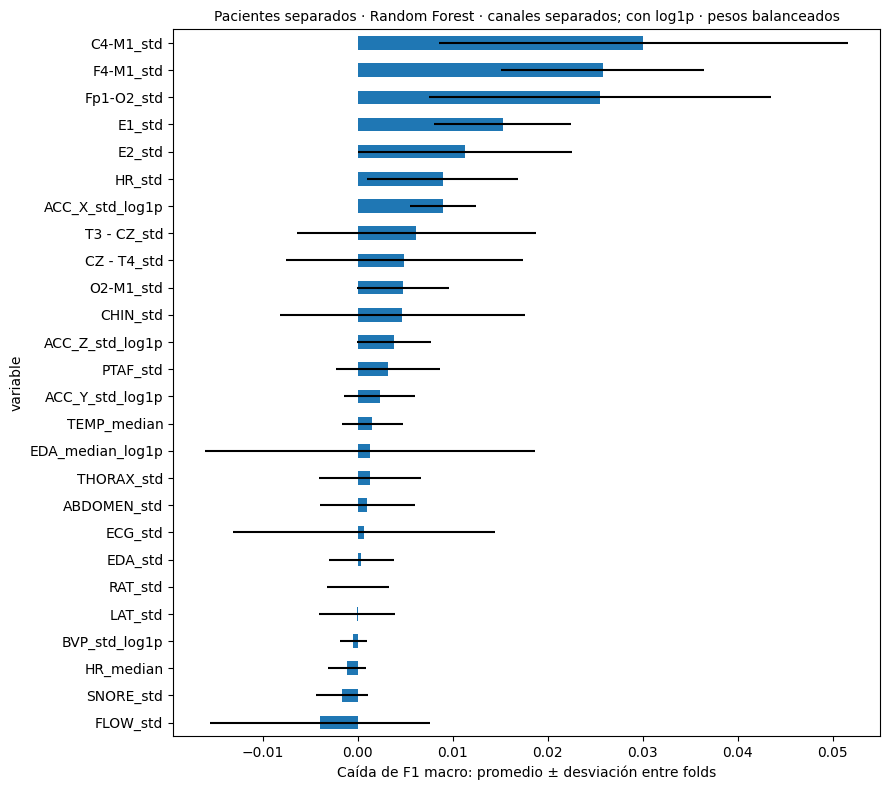

Fold 1/5 terminado.


Fold 2/5 terminado.


Fold 3/5 terminado.


Fold 4/5 terminado.


Fold 5/5 terminado.


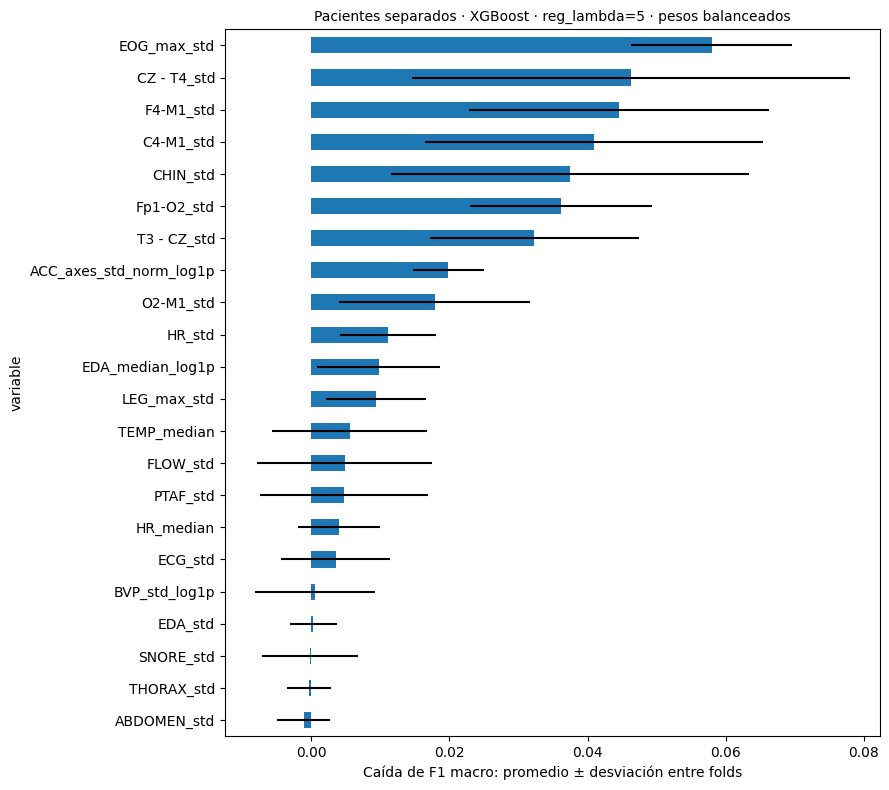

Fold 1/5 terminado.


Fold 2/5 terminado.


Fold 3/5 terminado.


Fold 4/5 terminado.


Fold 5/5 terminado.


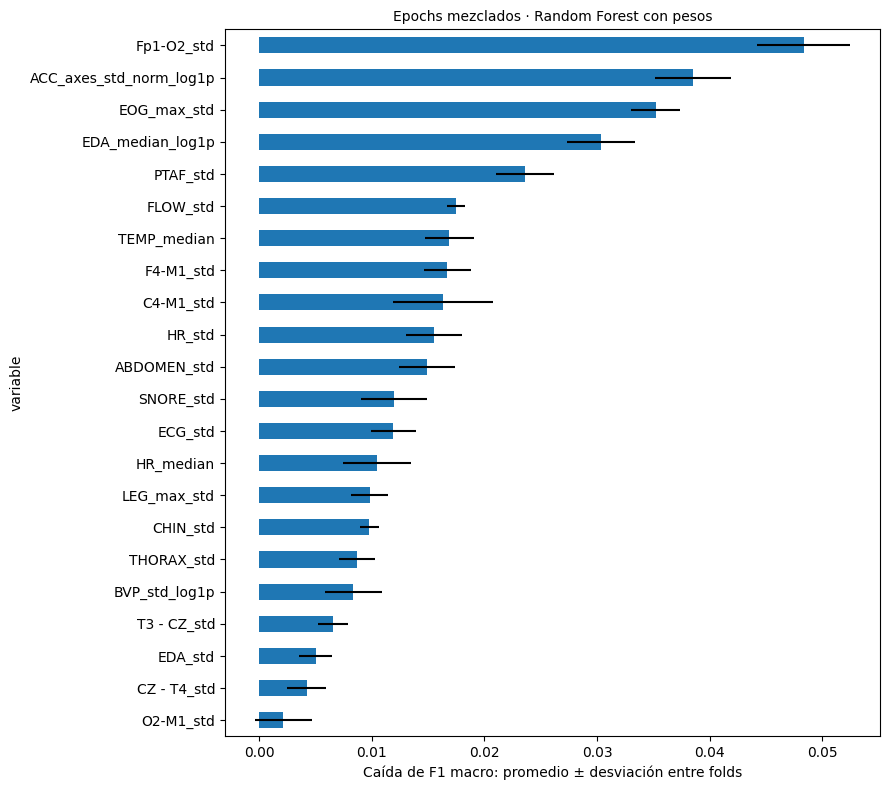

Fold 1/5 terminado.


Fold 2/5 terminado.


Fold 3/5 terminado.


Fold 4/5 terminado.


Fold 5/5 terminado.


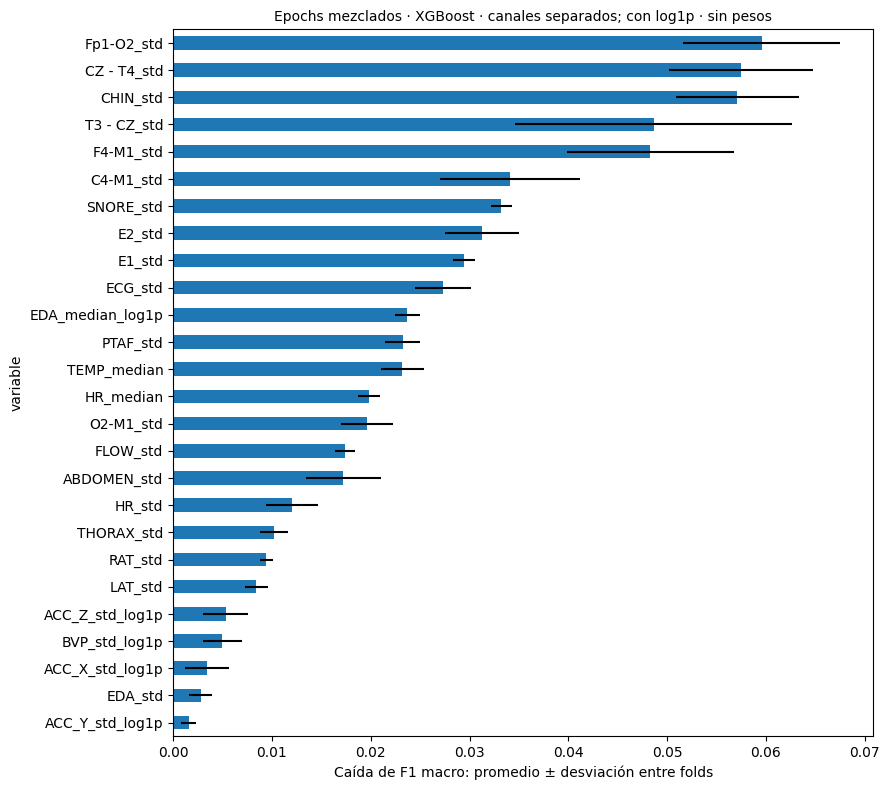

In [12]:
diagnosticos = {}
for protocolo in ESCENARIOS:
    for algoritmo in ['RF','XGB']:
        # Importancia de los mejores modelos sin historia/SMOTE para comparar señales originales.
        nombres = [n for n,r in ajustes.items() if r['configuracion']['protocolo']==protocolo
            and algoritmo_resultado(n)==algoritmo and not n.startswith(('contexto_','smote_','balanceo_'))]
        seleccionado = elegir_nombres(nombres)
        modelo,pesos,escalar,entradas = especificaciones[seleccionado]
        nombre = f'diagnostico_{protocolo}_{algoritmo}'
        r = evaluar(modelo,entradas,nombre,protocolo,pesos,escalar,importancia=True)
        imp = r['importancia'].groupby(['variable','fold']).caida_f1_macro.mean()
        resumen = imp.groupby('variable').agg(['mean','std']).sort_values('mean')
        resumen.to_csv(SALIDA / nombre / 'resumen_importancia.csv')
        resumen['mean'].plot.barh(xerr=resumen['std'],figsize=(9,8))
        plt.xlabel('Caída de F1 macro: promedio ± desviación entre folds')
        plt.title(nombre_protocolo(protocolo)+' · '+etiqueta_resultado(seleccionado, ajustes[seleccionado]), wrap=True, fontsize=10)
        plt.tight_layout(); plt.savefig(SALIDA / nombre / 'importancia.png'); plt.show()
for protocolo,nombre in candidatos_escenario.items():
    diagnosticos[protocolo] = ajustes[nombre]

def etiqueta_diagnostico(protocolo):
    nombre = candidatos_escenario[protocolo]
    cfg = planes_candidatos[protocolo]
    return (nombre_protocolo(protocolo) + ' · ' + nombre_algoritmo(cfg['algoritmo'])
        + (' · con pesos' if cfg['pesos'] else ' · sin pesos')
        + ' · historia=' + (str(cfg['retardos']) if cfg['retardos'] else 'no')
        + ' · SMOTE=' + (str(cfg['smote']) if cfg['smote'] else 'no'))


#### XGBoost final con historia · importancia individual y conjunta

Interpretar la configuración congelada de 68 entradas (actuales, señales de hace 1/2 minutos e indicadores).
Se reentrena únicamente este candidato en los cinco folds por pacientes de desarrollo: medianas y pesos solo con entrenamiento.
Cinco permutaciones por variable y fold; primero media de repeticiones dentro del fold y luego media/desviación entre folds.
No se utilizan datos, pipelines ni predicciones de test, ni se seleccionan nuevas características.

El primer gráfico muestra las 20 entradas de mayor caída media de F1, distinguiendo grupos por color; se exportan las 68.
El segundo permuta conjuntamente cada grupo usando el mismo orden de filas en todas sus columnas, dejando las restantes intactas.
**La importancia conjunta no es la suma de importancias individuales ni un porcentaje causal.** Los grupos tienen distinto tamaño;
las correlaciones pueden repartir u ocultar dependencias. Una caída negativa no garantiza mejorar eliminando esa entrada.
Las permutaciones pueden formar combinaciones poco habituales de señales e indicadores; interpretar como diagnóstico del modelo.

Ejecutar este bloque con las definiciones de 4.1 y los archivos congelados de revisión, sin volver a ejecutar las búsquedas ni 4.7/4.8.


Importancia final: fold 1/5 terminado; F1 base 0.5426.


Importancia final: fold 2/5 terminado; F1 base 0.4911.


Importancia final: fold 3/5 terminado; F1 base 0.4712.


Importancia final: fold 4/5 terminado; F1 base 0.5105.


Importancia final: fold 5/5 terminado; F1 base 0.5113.


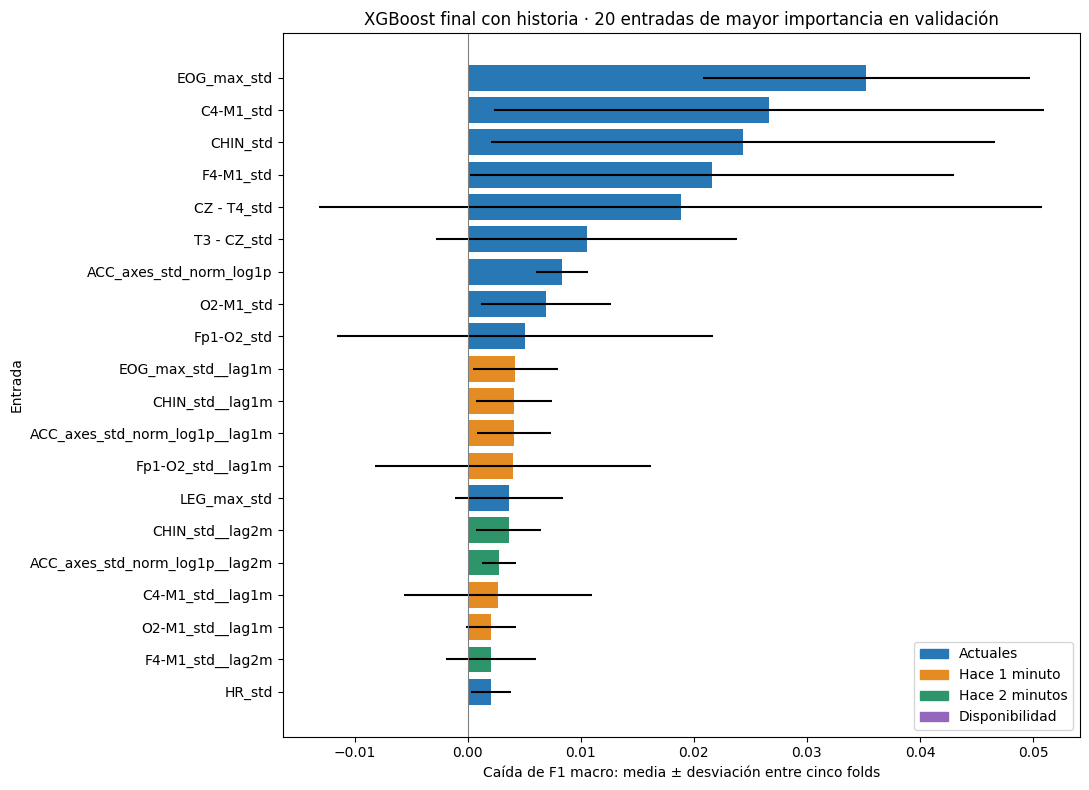

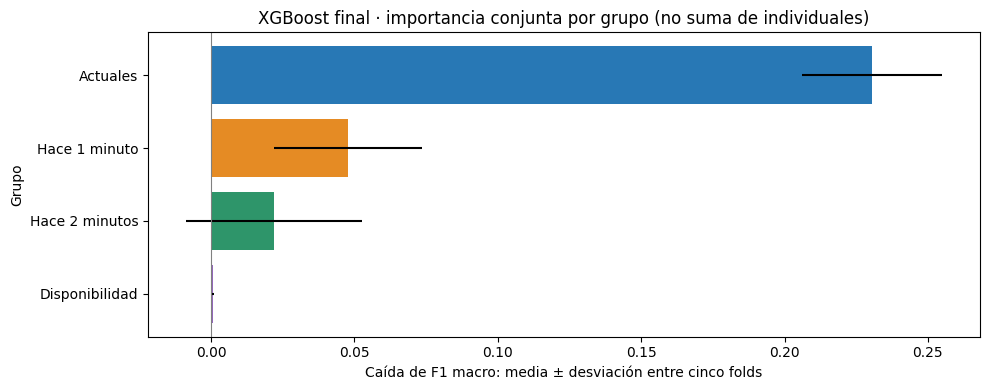

**Importancia conjunta: grupos permutados por separado, sin sumar importancias**

,Grupo,Caída media de F1 macro,Desviación entre folds
0,Actuales,0.2306,0.0244
2,Hace 1 minuto,0.0476,0.0258
3,Hace 2 minutos,0.0218,0.0307
1,Disponibilidad,0.0006,0.0003


**Verificación: mismo candidato en cinco folds de desarrollo**

fold,f1_validacion,entrenamiento_segundos,epochs_entrenamiento,epochs_validacion,pacientes_entrenamiento,pacientes_validacion
1,0.5426,5.7659,36354,8657,49,11
2,0.4911,7.5702,35650,9361,47,13
3,0.4712,7.7778,36273,8738,48,12
4,0.5105,7.6511,35316,9695,47,13
5,0.5113,7.8655,36451,8560,49,11


Las 68 importancias individuales y las permutaciones completas están exportadas en B:\Facultad\2026\CDD\REPO TPI\TPI_CDD_G7\output\modelado_revision\interpretacion_xgb_historia


In [2]:
# 4.6.1 · Interpretación del XGBoost final con historia: solo desarrollo.
from pathlib import Path
import json
import hashlib
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, make_scorer
from sklearn.utils.class_weight import compute_sample_weight


def hash_interpretacion(ruta):
    h = hashlib.sha256()
    with Path(ruta).open('rb') as f:
        for bloque in iter(lambda: f.read(1024 * 1024), b''):
            h.update(bloque)
    return h.hexdigest()


def grupos_historia(columnas):
    grupos = {'Actuales': [], 'Hace 1 minuto': [], 'Hace 2 minutos': [], 'Disponibilidad': []}
    for c in columnas:
        if c.startswith('historia_disponible__'):
            grupos['Disponibilidad'].append(c)
        elif c.endswith('__lag1m'):
            grupos['Hace 1 minuto'].append(c)
        elif c.endswith('__lag2m'):
            grupos['Hace 2 minutos'].append(c)
        elif '__lag' in c:
            raise ValueError('Retardo distinto del candidato congelado')
        else:
            grupos['Actuales'].append(c)
    return grupos


def permutar_bloque(entradas, columnas, orden):
    """Misma permutación de filas para todas las columnas del grupo."""
    orden = np.asarray(orden)
    if (not columnas or not set(columnas).issubset(entradas.columns)
        or orden.ndim != 1 or not np.array_equal(np.sort(orden), np.arange(len(entradas)))):
        raise ValueError('Grupo o permutación inválidos')
    salida = entradas.copy(deep=True)
    salida.loc[:, columnas] = entradas.loc[:, columnas].iloc[orden].to_numpy()
    return salida


def calcular_importancia_historia(entradas, objetivo, tabla, rondas, modelo, salida,
                                identidad, semilla=42, repeticiones=5):
    if (not entradas.index.equals(tabla.index) or len(objetivo) != len(entradas)
        or np.isinf(entradas.to_numpy(float)).any()
        or set(entradas) & {'patient_id', 'epoch', 'Sleep_Stage', 'tiempo_relativo_segundos'}):
        raise ValueError('Entradas inválidas o identificadores entre predictores')
    grupos = grupos_historia(list(entradas))
    cobertura = np.zeros(len(tabla), dtype=int)
    for tr, va in rondas:
        if (set(tr) & set(va) or len(tr) + len(va) != len(tabla)
            or len(np.unique(tr))!=len(tr) or len(np.unique(va))!=len(va)
            or not np.array_equal(np.union1d(tr,va),np.arange(len(tabla)))):
            raise ValueError('Fold incompleto o con observaciones compartidas')
        if not set(tabla.iloc[tr].patient_id).isdisjoint(tabla.iloc[va].patient_id):
            raise ValueError('Pacientes compartidos en importancia final')
        if set(objetivo[tr]) != set(range(5)) or set(objetivo[va]) != set(range(5)):
            raise ValueError('Fold sin cobertura de las cinco clases')
        cobertura[va] += 1
    if not (cobertura == 1).all():
        raise ValueError('Cada epoch debe tener una única validación')
    firma = hashlib.sha256(json.dumps(dict(identidad=identidad, semilla=semilla,
        repeticiones=repeticiones, parametros=modelo.get_params(),
        entradas=hashlib.sha256(pd.util.hash_pandas_object(entradas,index=True).values.tobytes()).hexdigest(),
        objetivo=hashlib.sha256(np.asarray(objetivo,dtype='<i8').tobytes()).hexdigest(),
        folds=hashlib.sha256(b''.join(np.asarray(x,dtype='<i8').tobytes() for par in rondas for x in par)).hexdigest()),
        sort_keys=True, default=str).encode()).hexdigest()
    salida = Path(salida)
    sello = salida / 'estado.json'
    if sello.exists():
        estado = json.loads(sello.read_text(encoding='utf-8'))
        if estado['firma'] != firma or estado['estado'] != 'completo':
            raise RuntimeError('Interpretación incompatible o incompleta: conservar y revisar')
        for p, h in estado['archivos'].items():
            if not (salida / p).exists() or hash_interpretacion(salida / p) != h:
                raise ValueError('Exportaciones de importancia modificadas')
        print('Importancias completas: relectura sin entrenamiento ni permutaciones.')
        return {k: pd.read_csv(salida / f'{k}.csv') for k in
            ['individual', 'grupos', 'metricas_folds']}
    if salida.exists() and any(salida.iterdir()):
        raise RuntimeError('Hay evidencia previa sin estado: no sobrescribir')
    salida.mkdir(parents=True, exist_ok=True)
    with sello.open('x', encoding='utf-8') as f:
        json.dump(dict(estado='en_ejecucion', firma=firma, identidad=identidad), f, default=str, indent=2)
    filas, conjuntas, metricas, medianas, ponderaciones = [], [], [], [], []
    scorer = make_scorer(f1_score, labels=range(5), average='macro', zero_division=0)
    for numero, (tr, va) in enumerate(rondas, 1):
        pipe = Pipeline([('imputacion', SimpleImputer(strategy='median',keep_empty_features=True)),
                         ('modelo', clone(modelo))])
        pesos = compute_sample_weight('balanced', objetivo[tr])
        inicio = perf_counter()
        pipe.fit(entradas.iloc[tr], objetivo[tr], modelo__sample_weight=pesos)
        segundos = perf_counter() - inicio
        pred = pipe.predict(entradas.iloc[va])
        base_f1 = f1_score(objetivo[va], pred, labels=range(5), average='macro', zero_division=0)
        metricas.append(dict(fold=numero,f1_validacion=base_f1,entrenamiento_segundos=segundos,
            epochs_entrenamiento=len(tr),epochs_validacion=len(va),
            pacientes_entrenamiento=tabla.iloc[tr].patient_id.nunique(),
            pacientes_validacion=tabla.iloc[va].patient_id.nunique()))
        for c, valor in zip(entradas.columns, pipe.named_steps['imputacion'].statistics_):
            medianas.append(dict(fold=numero,variable=c,mediana=float(valor)))
        for clase in range(5):
            ponderaciones.append(dict(fold=numero,clase=clase,epochs=int((objetivo[tr]==clase).sum()),
                                      peso=float(pesos[objetivo[tr]==clase][0])))
        individual = permutation_importance(pipe,entradas.iloc[va],objetivo[va],scoring=scorer,
            n_repeats=repeticiones,random_state=semilla+numero,n_jobs=1)
        for j,c in enumerate(entradas):
            grupo = next(g for g,cols in grupos.items() if c in cols)
            for repeticion,caida in enumerate(individual.importances[j],1):
                filas.append(dict(variable=c,grupo=grupo,fold=numero,repeticion=repeticion,
                                  caida_f1_macro=float(caida)))
        for repeticion in range(1,repeticiones+1):
            orden = np.random.default_rng(semilla+1000*numero+repeticion).permutation(len(va))
            for grupo,columnas in grupos.items():
                mezclada = permutar_bloque(entradas.iloc[va],columnas,orden)
                f1 = f1_score(objetivo[va],pipe.predict(mezclada),labels=range(5),average='macro',zero_division=0)
                conjuntas.append(dict(grupo=grupo,fold=numero,repeticion=repeticion,
                    columnas=len(columnas),caida_f1_macro=float(base_f1-f1)))
        # Checkpoints por fold: se preservan si la ejecución se interrumpe.
        pd.DataFrame(filas).to_csv(salida / 'permutaciones_individuales.csv',index=False)
        pd.DataFrame(conjuntas).to_csv(salida / 'permutaciones_grupos.csv',index=False)
        print(f'Importancia final: fold {numero}/{len(rondas)} terminado; F1 base {base_f1:.4f}.',flush=True)
    individual_fold = pd.DataFrame(filas).groupby(['variable','grupo','fold'],as_index=False).caida_f1_macro.mean()
    individual = individual_fold.groupby(['variable','grupo']).caida_f1_macro.agg(
        media='mean',desviacion='std').reset_index().sort_values('media',ascending=False)
    grupos_fold = pd.DataFrame(conjuntas).groupby(['grupo','fold'],as_index=False).caida_f1_macro.mean()
    conjunta = grupos_fold.groupby('grupo').caida_f1_macro.agg(
        media='mean',desviacion='std').reset_index().sort_values('media',ascending=False)
    exportaciones=dict(individual=individual,grupos=conjunta,metricas_folds=pd.DataFrame(metricas),
        individual_por_fold=individual_fold,grupos_por_fold=grupos_fold,
        medianas_entrenamiento=pd.DataFrame(medianas),pesos_entrenamiento=pd.DataFrame(ponderaciones))
    for nombre,datos in exportaciones.items():datos.to_csv(salida / f'{nombre}.csv',index=False)
    estado=dict(estado='completo',firma=firma,identidad=identidad,
        archivos={p.name:hash_interpretacion(p) for p in salida.glob('*.csv')})
    temporal=sello.with_suffix('.tmp')
    temporal.write_text(json.dumps(estado,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
    temporal.replace(sello)
    return {k:exportaciones[k] for k in ['individual','grupos','metricas_folds']}


def cargar_entrada_importancia(raiz, salida_revision):
    from xgboost import XGBClassifier
    import importlib.metadata
    import platform
    cfg = json.loads((salida_revision / 'candidatos_fijados.json').read_text(encoding='utf-8'))['pacientes']
    if (cfg['algoritmo'] != 'XGB' or cfg['retardos'] != [1,2] or len(cfg['columnas']) != 68
        or not cfg['pesos'] or cfg['smote'] is not None or cfg['escalar'] or not cfg['imputar']):
        raise ValueError('No coincide el candidato congelado esperado')
    versiones={'python':platform.python_version(),**{p:importlib.metadata.version(p)
        for p in cfg['versiones'] if p!='python'}}
    if versiones!=cfg['versiones']:
        raise ValueError('Versiones distintas: no mezclar interpretaciones de otro entorno')
    fuentes={nombre:Path(raiz)/'etl_v1'/nombre for nombre in cfg['huella_fuentes']}
    if not all(p.exists() for p in fuentes.values()):
        fuentes={nombre:buscar_csv(nombre) for nombre in cfg['huella_fuentes']}
    for nombre,ruta in fuentes.items():
        if hash_interpretacion(ruta) != cfg['huella_fuentes'][nombre]:
            raise ValueError('Fuentes distintas de la configuración congelada')
    asignacion=json.loads((salida_revision/'asignacion_pacientes.json').read_text(encoding='utf-8'))
    if asignacion['huella'] != cfg['huella_fuentes'] or asignacion['semilla'] != 42:
        raise ValueError('Asignación incompatible')
    actual=[c for c in cfg['columnas'] if '__lag' not in c and not c.startswith('historia_disponible__')]
    tabla=pd.read_csv(fuentes['dataset_modelado_candidato.csv'],low_memory=False,
        usecols=['patient_id','epoch','Sleep_Stage','tiempo_relativo_segundos']+actual)
    tabla=tabla.loc[~tabla.patient_id.isin(asignacion['pacientes_test'])].sort_values(['patient_id','epoch']).reset_index(drop=True)
    if (len(tabla)!=45011 or tabla.patient_id.nunique()!=60 or tabla.duplicated(['patient_id','epoch']).any()
        or not np.isfinite(tabla[actual].to_numpy(float)).all()):
        raise ValueError('Desarrollo incompatible con la cohorte congelada')
    entradas,disponibilidad=agregar_historia(tabla[actual],tabla,cfg['retardos'])
    if list(entradas) != cfg['columnas']:
        raise ValueError('Columnas distintas o desordenadas')
    if hashlib.sha256(pd.util.hash_pandas_object(entradas,index=True).values.tobytes()).hexdigest()!=cfg['huella_entradas']:
        raise ValueError('Historia distinta de la configuración congelada')
    f=pd.read_csv(salida_revision/'folds_validacion.csv').query("protocolo == 'pacientes'")
    f=tabla[['patient_id','epoch']].merge(f,on=['patient_id','epoch'],validate='one_to_one',how='left')
    if f.fold.isna().any() or len(f)!=len(tabla):raise ValueError('Asignación de folds incompleta')
    rondas=[(np.flatnonzero(f.fold.to_numpy()!=k),np.flatnonzero(f.fold.to_numpy()==k)) for k in range(1,6)]
    huella_folds=hashlib.sha256(b''.join(np.asarray(x,dtype='<i8').tobytes() for par in rondas for x in par)).hexdigest()
    if huella_folds!=cfg['huella_folds']:raise ValueError('Folds distintos de los congelados')
    y=tabla.Sleep_Stage.map({e:i for i,e in enumerate(['W','N1','N2','N3','R'])}).to_numpy()
    identidad=dict(configuracion=cfg,fuentes=cfg['huella_fuentes'],folds=huella_folds,
        alcance='Solo desarrollo; sin cargar pipelines ni predicciones de test',version='importancia-historia-v1',
        codigo='c3b121bc414c284061ce5cf8a71b66121d687cfe00bf62158768054346d47500',versiones_ejecucion=versiones)
    return entradas,y,tabla,rondas,XGBClassifier(**cfg['parametros']),identidad,disponibilidad


# Para ejecutar solo este bloque: cargar las definiciones de 4.1 (agregar_historia/buscar_csv),
# no las búsquedas de 4.5 ni los bloques de test 4.7/4.8.
RAIZ_INTERPRETACION = Path.cwd() if Path('etl_v1').is_dir() else Path('..').resolve()
SALIDA_REVISION_INTERPRETACION = (Path('/kaggle/working/modelado_revision')
    if globals().get('EN_KAGGLE',False) else RAIZ_INTERPRETACION/'output/modelado_revision')
CARPETA_IMPORTANCIA_FINAL = SALIDA_REVISION_INTERPRETACION / 'interpretacion_xgb_historia'
_entrada = cargar_entrada_importancia(RAIZ_INTERPRETACION,SALIDA_REVISION_INTERPRETACION)
RESULTADOS_IMPORTANCIA_FINAL = calcular_importancia_historia(*_entrada[:5],
    CARPETA_IMPORTANCIA_FINAL,_entrada[5],semilla=42,repeticiones=5)

_colores={'Actuales':'#2878B5','Hace 1 minuto':'#E58B24','Hace 2 minutos':'#2E956A','Disponibilidad':'#9467BD'}
_top=RESULTADOS_IMPORTANCIA_FINAL['individual'].head(20).iloc[::-1]
fig,ax=plt.subplots(figsize=(11,8))
ax.barh(_top.variable,_top.media,xerr=_top.desviacion,color=[_colores[g] for g in _top.grupo])
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c,label=g) for g,c in _colores.items()],loc='lower right')
ax.axvline(0,color='gray',lw=.8)
ax.set(xlabel='Caída de F1 macro: media ± desviación entre cinco folds',ylabel='Entrada',
       title='XGBoost final con historia · 20 entradas de mayor importancia en validación')
fig.tight_layout();fig.savefig(CARPETA_IMPORTANCIA_FINAL/'importancia_individual_top20.png');plt.show()
_grupo=RESULTADOS_IMPORTANCIA_FINAL['grupos'].iloc[::-1]
fig,ax=plt.subplots(figsize=(10,4))
ax.barh(_grupo.grupo,_grupo.media,xerr=_grupo.desviacion,color=[_colores[g] for g in _grupo.grupo])
ax.axvline(0,color='gray',lw=.8)
ax.set(xlabel='Caída de F1 macro: media ± desviación entre cinco folds',ylabel='Grupo',
       title='XGBoost final · importancia conjunta por grupo (no suma de individuales)')
fig.tight_layout();fig.savefig(CARPETA_IMPORTANCIA_FINAL/'importancia_conjunta_grupos.png');plt.show()
mostrar_tabla(RESULTADOS_IMPORTANCIA_FINAL['grupos'].rename(columns={
    'grupo':'Grupo','media':'Caída media de F1 macro','desviacion':'Desviación entre folds'}),
    'Importancia conjunta: grupos permutados por separado, sin sumar importancias')
mostrar_tabla(RESULTADOS_IMPORTANCIA_FINAL['metricas_folds'],'Verificación: mismo candidato en cinco folds de desarrollo')
print('Las 68 importancias individuales y las permutaciones completas están exportadas en',CARPETA_IMPORTANCIA_FINAL)


### 4.6.2. Errores y matrices de confusión
Reportes y matrices acumulados sobre predicciones OOF elegibles. Los registros largos pesan más. Estos valores no son el promedio entre folds.


**Pacientes separados · XGBoost · con pesos · historia=[1, 2] · SMOTE=no · métricas acumuladas**

,precision,recall,f1-score,support
W,0.5595,0.5973,0.5778,9387.0000
N1,0.2265,0.2592,0.2417,5309.0000
N2,0.8444,0.7044,0.7681,23461.0000
N3,0.4359,0.6186,0.5114,1825.0000
R,0.3820,0.5128,0.4379,5029.0000
macro avg,0.4897,0.5385,0.5074,45011.0000
weighted avg,0.6439,0.6047,0.6190,45011.0000


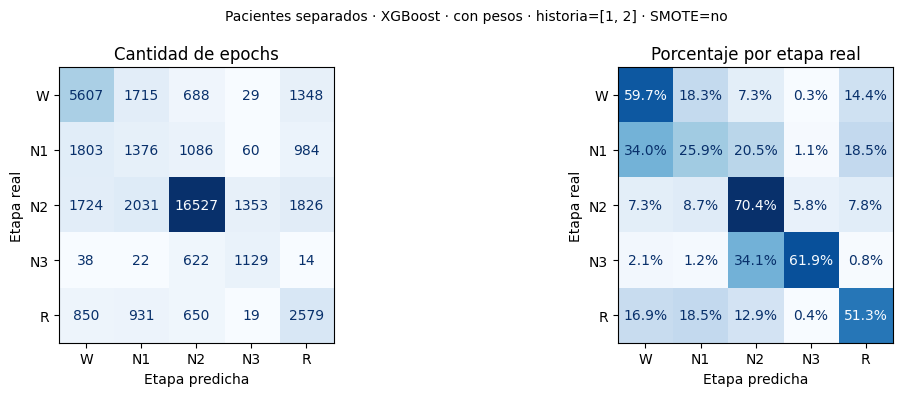

**Epochs mezclados · Random Forest · sin pesos · historia=no · SMOTE={'ratio': 1.0, 'k': 5} · métricas acumuladas**

,precision,recall,f1-score,support
W,0.8307,0.8521,0.8413,9387.0000
N1,0.5306,0.5994,0.5629,5309.0000
N2,0.9135,0.8632,0.8876,23461.0000
N3,0.8041,0.8860,0.8431,1825.0000
R,0.8532,0.8831,0.8679,5029.0000
macro avg,0.7864,0.8168,0.8006,45011.0000
weighted avg,0.8399,0.8329,0.8356,45011.0000


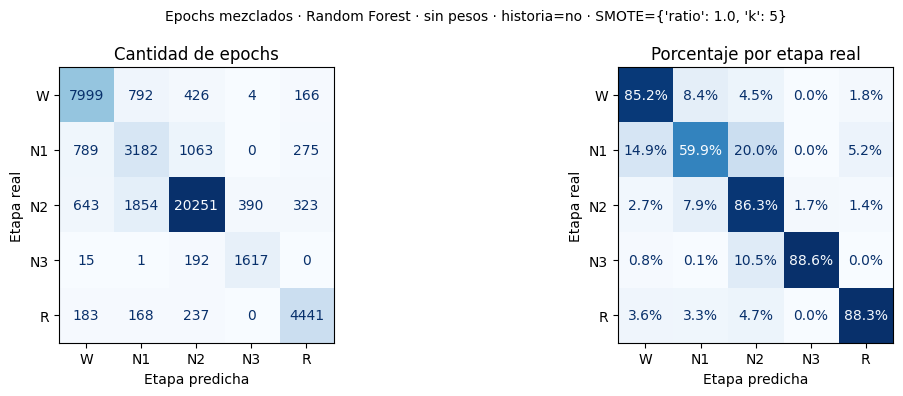

In [2]:
def diagnosticar_errores(datos,nombre,carpeta):
    carpeta.mkdir(exist_ok=True)
    reporte = pd.DataFrame(classification_report(datos.real,datos.predicha,labels=range(5),
        target_names=ETAPAS,output_dict=True,zero_division=0)).T
    reporte.to_csv(carpeta / 'reporte.csv')
    mostrar_tabla(reporte.loc[ETAPAS+['macro avg','weighted avg']],nombre+' · métricas acumuladas')
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for ax,norma in zip(axes,[None,'true']):
        ConfusionMatrixDisplay.from_predictions(datos.real,datos.predicha,labels=range(5),
            display_labels=ETAPAS,normalize=norma,values_format='.1%' if norma else 'd',
            cmap='Blues',colorbar=False,ax=ax)
    for ax in axes:
        ax.set_xlabel('Etapa predicha'); ax.set_ylabel('Etapa real')
    axes[0].set_title('Cantidad de epochs')
    axes[1].set_title('Porcentaje por etapa real')
    fig.suptitle(nombre, wrap=True, fontsize=10); fig.tight_layout(); fig.savefig(carpeta/'matriz.png'); plt.show()

def diagnosticar_curvas(datos,nombre,carpeta):
    tipo = 'roc'
    carpeta.mkdir(exist_ok=True)
    fig,axes=plt.subplots(1,5,figsize=(20,4))
    filas=[]
    for c,etapa in enumerate(ETAPAS):
        binaria=datos.real.to_numpy()==c
        if not binaria.any() or binaria.all():
            axes[c].set_title(etapa+': no evaluable')
            filas.append(dict(etapa=etapa,valor=np.nan)); continue
        prob=datos[f'prob_{etapa}'].to_numpy()
        fp,tp,_=roc_curve(binaria,prob)
        valor=roc_auc_score(binaria,prob)
        axes[c].plot(fp,tp,label=f'AUC={valor:.3f}')
        axes[c].plot([0,1],[0,1],'--',color='gray')
        axes[c].set(xlabel='Tasa de falsos positivos',ylabel='Recuperación')
        axes[c].set(title=etapa,xlim=(0,1),ylim=(0,1.02)); axes[c].legend()
        filas.append(dict(etapa=etapa,valor=valor))
    fig.suptitle(nombre, wrap=True, fontsize=10); fig.tight_layout(); fig.savefig(carpeta/f'{tipo}.png'); plt.show()
    tabla=pd.DataFrame(filas).set_index('etapa').rename(columns={'valor':'ROC-AUC'})
    tabla.to_csv(carpeta/f'{tipo}.csv'); mostrar_tabla(tabla)

def diagnosticar_pacientes(datos,nombre,carpeta):
    carpeta.mkdir(exist_ok=True)
    filas=[]
    for paciente,g in datos.groupby('patient_id'):
        filas.append(dict(Paciente=paciente,Epochs=len(g),Etapas=g.real.nunique(),
            F1_macro=f1_score(g.real,g.predicha,labels=range(5),average='macro',zero_division=0),
            Exactitud=accuracy_score(g.real,g.predicha)))
    tabla=pd.DataFrame(filas).sort_values('F1_macro')
    tabla.to_csv(carpeta/'pacientes.csv',index=False)
    mostrar_tabla(tabla.head(5),nombre+' · cinco pacientes con menor F1')
    mostrar_tabla(tabla[['F1_macro','Exactitud']].agg(['mean','std','min','max']), 'Dispersión entre pacientes')

def diagnosticar(datos,nombre,carpeta):
    diagnosticar_errores(datos,nombre,carpeta)
    diagnosticar_curvas(datos,nombre,carpeta)
    diagnosticar_pacientes(datos,nombre,carpeta)

for protocolo,r in diagnosticos.items():
    diagnosticar_errores(r['oof'],etiqueta_diagnostico(protocolo),SALIDA/f'diagnostico_final_{protocolo}')


### 4.6.3. ROC-AUC

Cada etapa se contrasta frente al resto. La curva relaciona recuperación y tasa de falsos positivos; ROC-AUC resume la ordenación de puntuaciones. Se acompaña de las métricas por etapa y la matriz, porque una tasa baja puede ocultar muchas falsas detecciones en clases minoritarias.


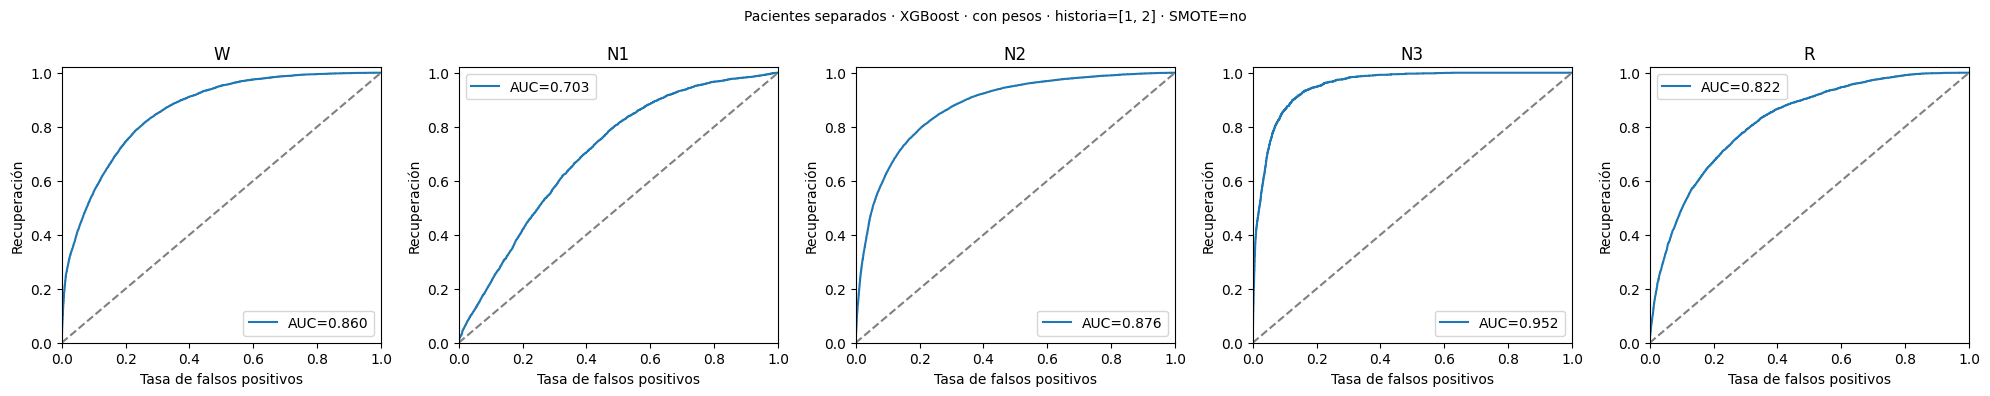

,ROC-AUC
etapa,
W,0.8602
N1,0.7030
N2,0.8758
N3,0.9522
R,0.8222


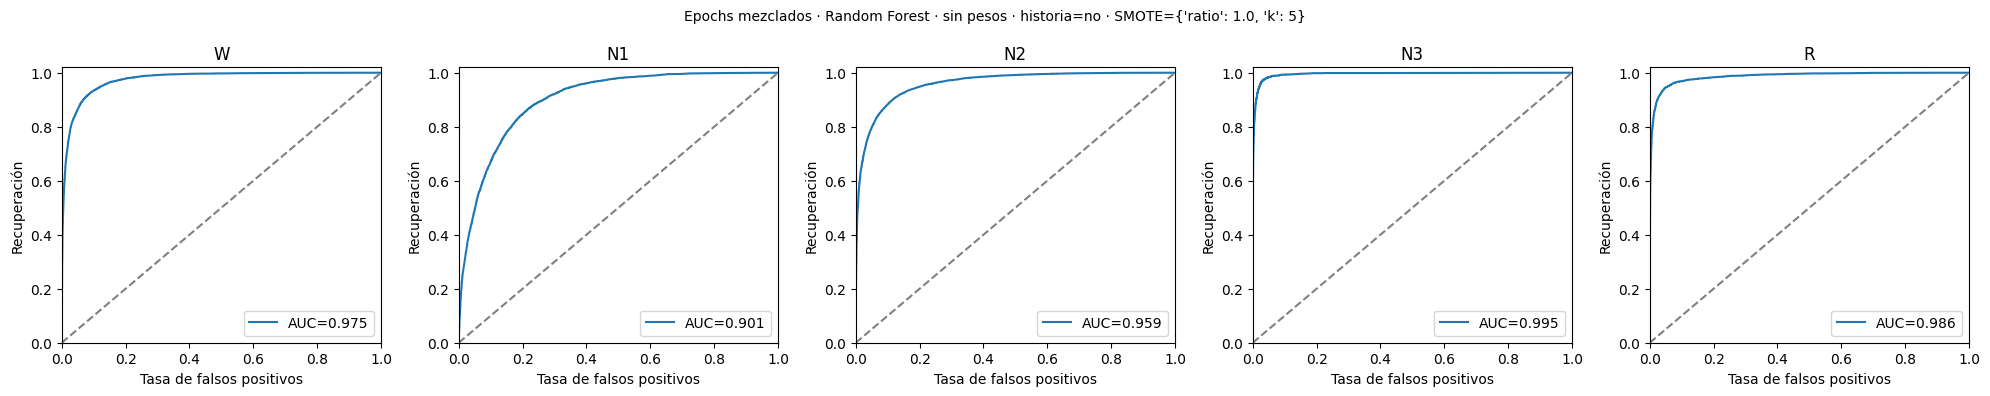

,ROC-AUC
etapa,
W,0.9750
N1,0.9013
N2,0.9594
N3,0.9947
R,0.9859


In [14]:
for protocolo,r in diagnosticos.items():
    diagnosticar_curvas(r['oof'],etiqueta_diagnostico(protocolo),SALIDA/f'diagnostico_final_{protocolo}')


### 4.6.4. Resultados por paciente

Se calcula F1 sobre las cinco etapas fijas y se informa cuántas etapas aparecen en cada persona. Se muestran los cinco pacientes con menor desempeño y la dispersión, y se exporta la tabla completa.

En pacientes separados, esa persona no participó en el entrenamiento de su fold. En epochs mezclados, el modelo aprendió de otros epochs suyos. Estos resultados permiten detectar dificultades ocultas por el promedio global; las etapas ausentes limitan la comparación individual.


In [15]:
for protocolo,r in diagnosticos.items():
    diagnosticar_pacientes(r['oof'],etiqueta_diagnostico(protocolo),SALIDA/f'diagnostico_final_{protocolo}')


**Pacientes separados · XGBoost · con pesos · historia=[1, 2] · SMOTE=no · cinco pacientes con menor F1**

,Paciente,Epochs,Etapas,F1_macro,Exactitud
29,39,839,4,0.0743,0.1335
20,27,532,4,0.1873,0.3534
51,82,660,3,0.2084,0.3242
52,84,687,4,0.2215,0.3785
44,59,753,5,0.2494,0.3785


**Dispersión entre pacientes**

,F1_macro,Exactitud
mean,0.4010,0.6029
std,0.1254,0.1405
min,0.0743,0.1335
max,0.6604,0.7959


**Epochs mezclados · Random Forest · sin pesos · historia=no · SMOTE={'ratio': 1.0, 'k': 5} · cinco pacientes con menor F1**

,Paciente,Epochs,Etapas,F1_macro,Exactitud
20,27,532,4,0.3319,0.6955
57,95,580,4,0.3793,0.8172
51,82,660,3,0.3997,0.9303
1,4,804,4,0.4170,0.7313
22,29,713,3,0.4187,0.8149


**Dispersión entre pacientes**

,F1_macro,Exactitud
mean,0.6134,0.8329
std,0.1102,0.0637
min,0.3319,0.5857
max,0.8234,0.9776


## 4.7. Comparación en los 16 pacientes de test histórico reservado
### 4.7.1. Configuraciones congeladas, entrenamiento y evaluación común

Se reciben los candidatos seleccionados en 4.5.5 mediante pacientes separados y epochs mezclados.
Ambos se reentrenan con los mismos 60 pacientes / 45.011 epochs de desarrollo y se evalúan sobre los mismos
**16 pacientes / 11.839 epochs reservados**, excluidos de selección. No se requieren pacientes adicionales.

Se fijan parámetros, representación, retardos, balanceo, columnas y preprocesamiento antes de calcular resultados del test.
Los pipelines se serializan y verifican con desarrollo; después se generan probabilidades una vez por candidato,
se persisten y se calculan métricas desde los archivos. Una comparación completa se relee sin entrenar ni inferir;
una incompleta bloquea reintentos. No borrar su marcador ni reemplazar sus artefactos.

`AUTORIZAR_COMPARACION_TEST=False` es el valor seguro para futuras consultas.
El test **ya fue consultado** y tuvo exposición histórica: es una comparación posterior sobre las mismas personas,
no una nueva prueba independiente. No se realizan reajustes después de consultarlo.
Las nuevas salidas van a `output/modelado_revision/comparacion_test/`, sin sobrescribir `output/modelado/`.


In [3]:
# 4.7 · Comparación sobre los 16 pacientes del test histórico reservado.
AUTORIZAR_COMPARACION_TEST = False


def json_comparacion(ruta, objeto, exclusivo=False):
    texto = json.dumps(objeto, ensure_ascii=False, sort_keys=True, indent=2, default=str)
    if exclusivo:
        with ruta.open('x', encoding='utf-8', newline='\n') as f:
            f.write(texto + '\n')
    else:
        temporal = ruta.with_suffix('.tmp')
        temporal.write_text(texto + '\n', encoding='utf-8')
        temporal.replace(ruta)


def firma_comparacion(objeto):
    return hashlib.sha256(json.dumps(objeto, sort_keys=True, default=str).encode()).hexdigest()


def preparar_test_reservado(configuraciones):
    if not set(dev.patient_id).isdisjoint(set(test.patient_id)):
        raise ValueError('Desarrollo y test comparten pacientes')
    if set(test.patient_id) != set(pacientes_test):
        raise ValueError('Pacientes de test distintos de la reserva')
    if test.duplicated(CLAVES).any() or not test.Sleep_Stage.isin(ETAPAS).all():
        raise ValueError('Claves o etiquetas inválidas en test')
    base_test = base.loc[base.patient_id.isin(pacientes_test)].reset_index(drop=True)
    comunes = CLAVES + ['Sleep_Stage', 'tiempo_relativo_segundos']
    if not base_test[comunes].equals(test[comunes]):
        raise ValueError('Test desalineado entre CSV')
    if not np.isfinite(test.tiempo_relativo_segundos).all():
        raise ValueError('Tiempos de test no finitos')
    variantes = construir_representaciones(base_test, test)
    entradas = {}
    for protocolo, cfg in configuraciones.items():
        t = variantes[cfg['representacion']]
        if not np.isfinite(t.to_numpy(float)).all():
            raise ValueError('Señales de test no finitas')
        if cfg['retardos']:
            t, cobertura = agregar_historia(t, test, cfg['retardos'])
        if list(t.columns) != cfg['columnas']:
            raise ValueError('Columnas de test incompatibles con el candidato congelado')
        entradas[protocolo] = t
    return test.copy(), entradas


def validar_predicciones_test(datos, claves_esperadas=None):
    if datos.duplicated(CLAVES).any() or not len(datos):
        raise ValueError('Predicciones de test vacías o duplicadas')
    if claves_esperadas is not None and not datos[CLAVES].equals(claves_esperadas.reset_index(drop=True)):
        raise ValueError('Faltan epochs de test o cambió su orden')
    prob = datos[[f'prob_{e}' for e in ETAPAS]].to_numpy()
    if (not np.isfinite(prob).all() or (prob < 0).any() or (prob > 1).any()
            or not np.allclose(prob.sum(axis=1), 1, atol=1e-6)):
        raise ValueError('Probabilidades de test inválidas')
    if not np.array_equal(datos.predicha.to_numpy(), prob.argmax(axis=1)):
        raise ValueError('Clases distintas de argmax')
    if not datos.real.isin(range(5)).all():
        raise ValueError('Etiquetas de test inválidas')


def comparar_test_reservado(autorizar=False):
    import joblib
    from datetime import datetime, timezone
    carpeta = SALIDA / 'comparacion_test'
    sello = carpeta / 'estado.json'
    firma = dict(candidatos=firma_comparacion(planes_candidatos), fuentes=huella,
                 pacientes_test=list(pacientes_test), versiones=versiones)
    if sello.exists():
        estado = json.loads(sello.read_text(encoding='utf-8'))
        if estado['firma'] != firma:
            raise ValueError('Cambió la configuración después de fijar la comparación de test')
        if estado['estado'] != 'evaluado':
            raise RuntimeError('Comparación incompleta: conservar evidencia; no reintentar automáticamente')
        for p, h in estado['archivos'].items():
            if not (carpeta / p).is_file() or sha256_archivo(carpeta / p) != h:
                raise ValueError('Artefactos de la comparación modificados')
        resultados = {}
        for protocolo in planes_candidatos:
            datos = pd.read_csv(carpeta / protocolo / 'predicciones.csv')
            validar_predicciones_test(datos)
            resultados[protocolo] = dict(datos=datos,
                tiempos=json.loads((carpeta / protocolo / 'tiempos.json').read_text(encoding='utf-8')))
        a, b = [r['datos'] for r in resultados.values()]
        pd.testing.assert_frame_equal(a[CLAVES + ['real']], b[CLAVES + ['real']])
        print('Comparación guardada: sin reentrenar ni repetir inferencia.')
        return resultados
    if not autorizar:
        raise RuntimeError('Primera comparación de test desactivada: requiere autorización explícita')
    if carpeta.exists() and any(carpeta.iterdir()):
        raise RuntimeError('Hay artefactos sin estado: conservarlos; no sobrescribir')
    if set(planes_candidatos) != {'pacientes', 'epochs'}:
        raise ValueError('Se requieren exactamente los dos candidatos congelados')
    if not set(dev.patient_id).isdisjoint(set(pacientes_test)):
        raise ValueError('Desarrollo incluye pacientes del test')
    carpeta.mkdir(exist_ok=True)
    estado = dict(estado='reservado', firma=firma,
                  inicio_utc=datetime.now(timezone.utc).isoformat(),
                  limite='Test históricamente consultado; comparación posterior sin reajustes')
    json_comparacion(sello, estado, exclusivo=True)
    json_comparacion(carpeta / 'configuracion_congelada.json', planes_candidatos, exclusivo=True)
    pipes, tiempos = {}, {}
    for protocolo, cfg in planes_candidatos.items():
        nombre = candidatos_escenario[protocolo]
        modelo, pesos, escalar, entradas = especificaciones[nombre]
        if (firma_comparacion(modelo.get_params()) != firma_comparacion(cfg['parametros'])
            or pesos != cfg['pesos'] or escalar != cfg['escalar'] or list(entradas.columns) != cfg['columnas']
            or hashlib.sha256(pd.util.hash_pandas_object(entradas, index=True).values.tobytes()).hexdigest() != cfg['huella_entradas']):
            raise ValueError('El candidato cambió después de fijar su configuración')
        opciones_smote = None
        if cfg['smote']:
            cantidades = np.bincount(y, minlength=5)
            objetivo = int(np.ceil(cantidades.max() * cfg['smote']['ratio']))
            opciones_smote = dict(k=cfg['smote']['k'],
                cantidades={c: max(int(n), objetivo) for c, n in enumerate(cantidades)})
        pipe = crear_pipeline(modelo, escalar, cfg['imputar'], opciones_smote)
        w = compute_sample_weight('balanced', y) if pesos else np.ones(len(y))
        inicio = perf_counter()
        if cfg['smote']:
            pipe.fit(entradas, y)
        else:
            pipe.fit(entradas, y, modelo__sample_weight=w)
        tiempos[protocolo] = {'entrenamiento_segundos': perf_counter() - inicio}
        destino = carpeta / protocolo
        destino.mkdir()
        json_comparacion(destino / 'tiempos_entrenamiento.json', tiempos[protocolo], exclusivo=True)
        joblib.dump(pipe, destino / 'pipeline.joblib')
        cargado = joblib.load(destino / 'pipeline.joblib')
        muestra = entradas.iloc[np.linspace(0, len(entradas) - 1, min(257, len(entradas)), dtype=int)]
        antes, despues = pipe.predict_proba(muestra), cargado.predict_proba(muestra)
        if not np.allclose(antes, despues, rtol=1e-12, atol=1e-12) or not np.array_equal(antes.argmax(axis=1), despues.argmax(axis=1)):
            raise ValueError('La serialización cambió predicciones de desarrollo')
        json_comparacion(destino / 'serializacion.json', dict(filas_desarrollo=len(muestra), igualdad_clases=True, probabilidades_equivalentes=True, tolerancia=1e-12, max_diferencia=float(np.max(np.abs(antes-despues)))))
        pd.DataFrame({'etapa': ETAPAS, 'epochs': np.bincount(y, minlength=5),
                      'peso': [float(w[y == c][0]) for c in range(5)]}).to_csv(destino / 'pesos_desarrollo.csv', index=False)
        pipes[protocolo] = cargado
    # No se calculó ninguna métrica de test: ambos modelos ya están congelados y serializados.
    nuevos, entradas_nuevas = preparar_test_reservado(planes_candidatos)
    estado.update(estado='abierto', apertura_utc=datetime.now(timezone.utc).isoformat())
    json_comparacion(sello, estado)
    for protocolo, pipe in pipes.items():
        if not np.array_equal(pipe.classes_, np.arange(5)):
            raise ValueError('Orden de clases incompatible')
        inicio = perf_counter()
        prob = pipe.predict_proba(entradas_nuevas[protocolo])
        tiempos[protocolo]['prediccion_segundos'] = perf_counter() - inicio
        datos = nuevos[CLAVES + ['tiempo_relativo_segundos']].copy()
        datos['real'] = nuevos.Sleep_Stage.map({e: i for i, e in enumerate(ETAPAS)})
        datos['predicha'] = prob.argmax(axis=1)
        for i, e in enumerate(ETAPAS):
            datos[f'prob_{e}'] = prob[:, i]
        validar_predicciones_test(datos, nuevos[CLAVES])
        datos.to_csv(carpeta / protocolo / 'predicciones.csv', index=False, mode='x')
        json_comparacion(carpeta / protocolo / 'tiempos.json', tiempos[protocolo], exclusivo=True)
    estado.update(estado='predicciones_guardadas')
    json_comparacion(sello, estado)
    # Las métricas y los gráficos se obtienen a partir de estos archivos, nunca de otra inferencia.
    resultados = {}
    for protocolo in pipes:
        datos = pd.read_csv(carpeta / protocolo / 'predicciones.csv')
        validar_predicciones_test(datos, nuevos[CLAVES])
        metricas = dict(f1_macro=f1_score(datos.real, datos.predicha, labels=range(5), average='macro', zero_division=0),
                        exactitud=accuracy_score(datos.real, datos.predicha), epochs=len(datos),
                        pacientes=int(datos.patient_id.nunique()))
        json_comparacion(carpeta / protocolo / 'metricas.json', metricas, exclusivo=True)
        resultados[protocolo] = dict(datos=datos, tiempos=tiempos[protocolo])
    archivos = {str(p.relative_to(carpeta)): sha256_archivo(p) for p in carpeta.rglob('*') if p.is_file() and p != sello}
    estado.update(estado='evaluado', fin_utc=datetime.now(timezone.utc).isoformat(), archivos=archivos)
    json_comparacion(sello, estado)
    return resultados


resultados_test_revision = comparar_test_reservado(autorizar=AUTORIZAR_COMPARACION_TEST)


Comparación guardada: sin reentrenar ni repetir inferencia.


### 4.7.2. Resultados y comparación sobre los mismos epochs
F1 macro es la métrica principal. Validación (media entre folds) y test (acumulado) se muestran separados.
Se presentan exactitud, etapas, matrices, ROC-AUC, tiempos y resultados de los 16 pacientes, además de las diferencias
emparejadas entre candidatos. Si cambia el algoritmo o sus entradas, la diferencia no se atribuye solo al protocolo.

La comprobación preapertura de RF se corrigió para admitir redondeo numérico menor a 10⁻¹², manteniendo clases idénticas. Se continuó desde pipelines guardados y auditados, sin reentrenarlos ni repetir inferencias de test. Los tiempos finales de entrenamiento no se recuperaron; se muestran como — y se conservan los costos medidos de validación.


**Pacientes separados · XGBoost · con pesos · historia=[1, 2] · SMOTE=no · test reservado · métricas acumuladas**

,precision,recall,f1-score,support
W,0.6597,0.5633,0.6077,2842.0000
N1,0.1733,0.2958,0.2185,1224.0000
N2,0.8708,0.6801,0.7637,6076.0000
N3,0.6023,0.5653,0.5832,375.0000
R,0.4245,0.7148,0.5327,1322.0000
macro avg,0.5461,0.5639,0.5412,11839.0000
weighted avg,0.6897,0.6126,0.6384,11839.0000


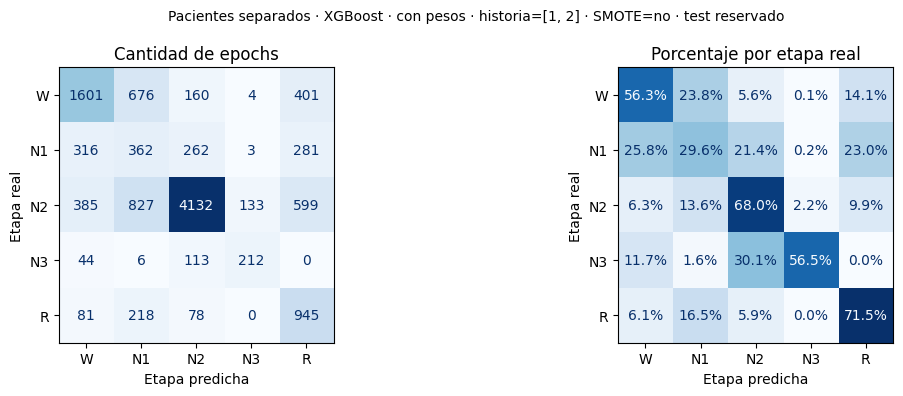

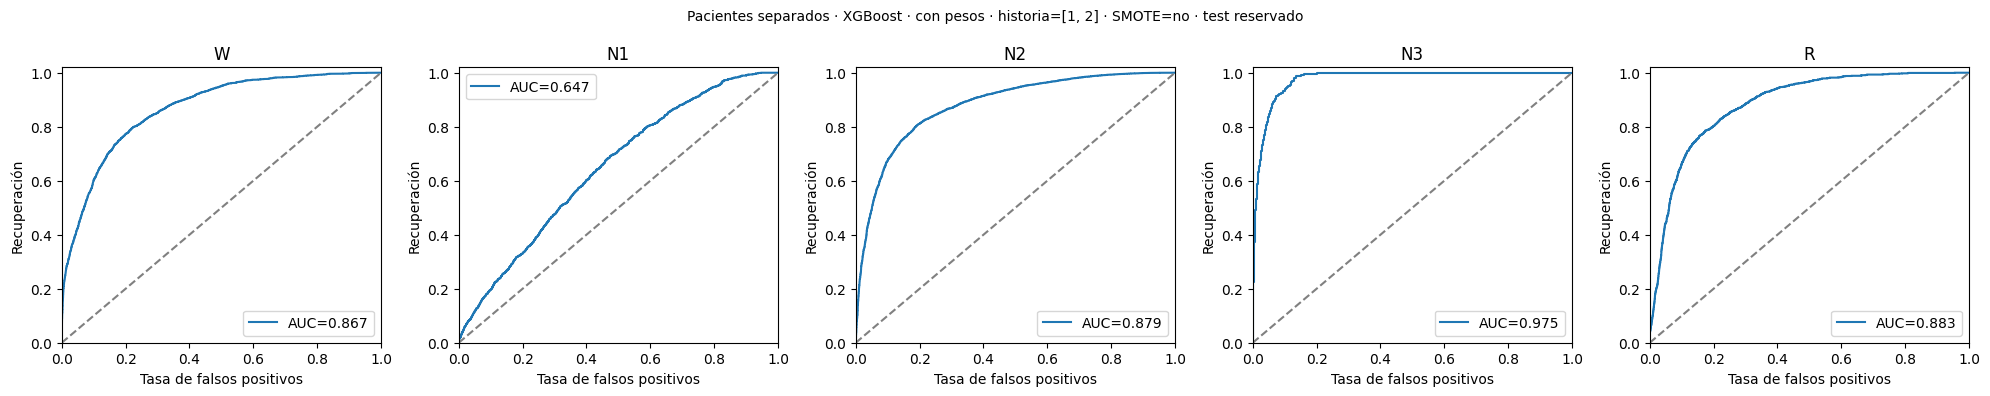

,ROC-AUC
etapa,
W,0.8669
N1,0.6471
N2,0.8787
N3,0.9746
R,0.8833


**Pacientes separados · XGBoost · con pesos · historia=[1, 2] · SMOTE=no · test reservado · cinco pacientes con menor F1**

,Paciente,Epochs,Etapas,F1_macro,Exactitud
13,83,731,4,0.1913,0.3748
14,85,616,4,0.2351,0.3425
12,67,821,4,0.3433,0.3800
1,6,801,4,0.3926,0.5431
0,2,652,4,0.4011,0.5874


**Dispersión entre pacientes**

,F1_macro,Exactitud
mean,0.4288,0.6121
std,0.1117,0.1475
min,0.1913,0.3425
max,0.6369,0.8750


**Pacientes separados · XGBoost · con pesos · historia=[1, 2] · SMOTE=no · test reservado · todos los pacientes de test**

,Epochs,Etapas,F1_macro,Exactitud
Paciente,,,,
83,731,4,0.1913,0.3748
85,616,4,0.2351,0.3425
67,821,4,0.3433,0.3800
6,801,4,0.3926,0.5431
2,652,4,0.4011,0.5874
50,696,5,0.4118,0.8750
53,756,4,0.4210,0.5939
88,713,4,0.4303,0.5891
56,809,4,0.4372,0.6823


**Epochs mezclados · Random Forest · sin pesos · historia=no · SMOTE={'ratio': 1.0, 'k': 5} · test reservado · métricas acumuladas**

,precision,recall,f1-score,support
W,0.6278,0.6101,0.6188,2842.0000
N1,0.1789,0.2394,0.2048,1224.0000
N2,0.8354,0.7349,0.7819,6076.0000
N3,0.8411,0.2400,0.3734,375.0000
R,0.4278,0.6430,0.5138,1322.0000
macro avg,0.5822,0.4935,0.4985,11839.0000
weighted avg,0.6723,0.6278,0.6402,11839.0000


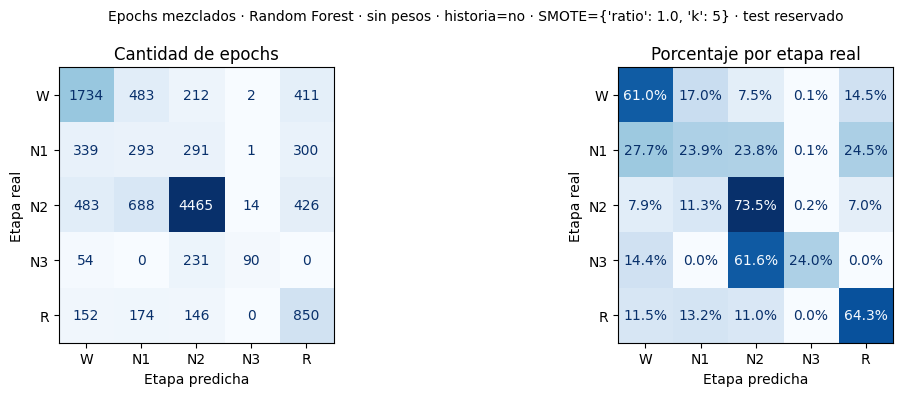

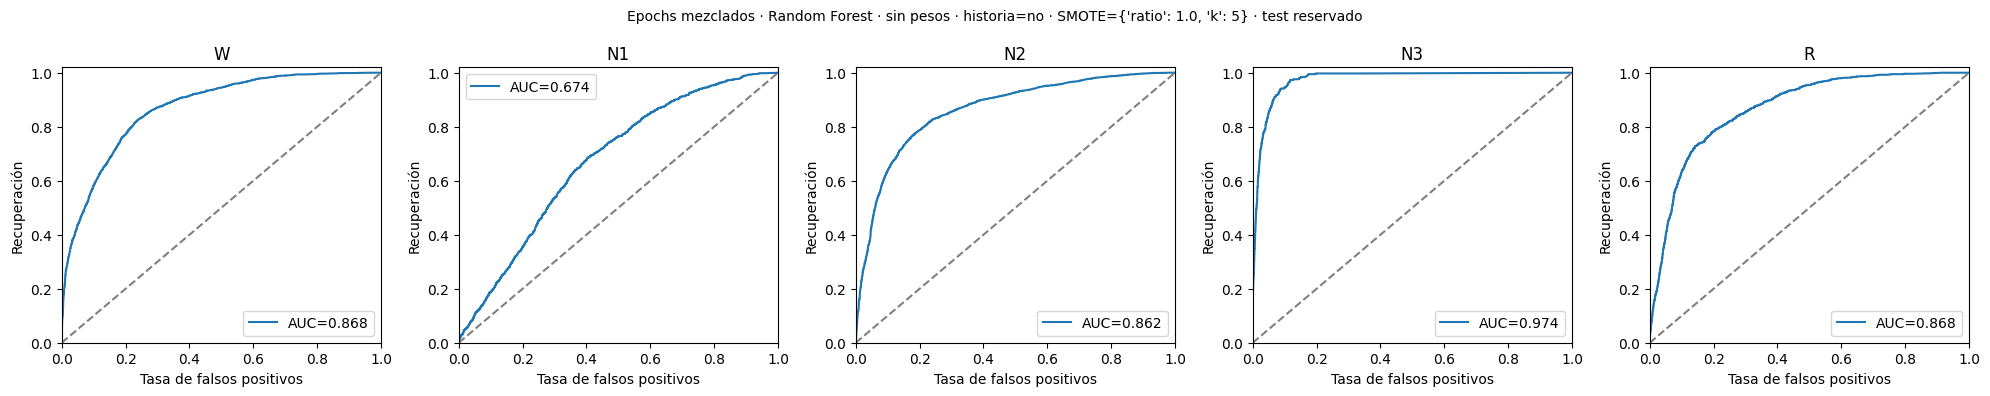

,ROC-AUC
etapa,
W,0.8682
N1,0.6742
N2,0.8620
N3,0.9744
R,0.8682


**Epochs mezclados · Random Forest · sin pesos · historia=no · SMOTE={'ratio': 1.0, 'k': 5} · test reservado · cinco pacientes con menor F1**

,Paciente,Epochs,Etapas,F1_macro,Exactitud
13,83,731,4,0.2137,0.3817
14,85,616,4,0.2725,0.3734
9,50,696,5,0.3303,0.8721
5,30,731,5,0.3659,0.5841
10,53,756,4,0.3695,0.5741


**Dispersión entre pacientes**

,F1_macro,Exactitud
mean,0.4066,0.6269
std,0.0846,0.1349
min,0.2137,0.3734
max,0.5493,0.8721


...

**Tiempos finales: — indica dato no recuperable; costos de validación en 4.5**

Protocolo,Entrenamiento final (s),Inferencia (s)
Pacientes separados,—,0.1098
Epochs mezclados,—,0.1508


**F1 macro sobre cinco etapas: comparación por paciente**

,Pacientes separados,Epochs mezclados,Diferencia epochs − pacientes
Paciente,,,
2,0.4011,0.4274,0.0263
6,0.3926,0.3880,-0.0046
12,0.4539,0.3912,-0.0626
14,0.6369,0.4397,-0.1972
20,0.5984,0.5493,-0.0491
30,0.4646,0.3659,-0.0987
35,0.4622,0.4547,-0.0075
37,0.5080,0.5072,-0.0008
48,0.4732,0.4572,-0.0160


Diferencia F1 macro en test, epochs menos pacientes: -0.0426.
No se reajustan modelos con este resultado. Test históricamente consultado; no es una nueva prueba independiente.
La diferencia corresponde a estos candidatos: pueden cambiar algoritmo, entradas y parámetros además del protocolo de selección.


In [4]:
resumen_comparacion = []
tablas_pacientes = {}
for protocolo, r in resultados_test_revision.items():
    datos = r['datos']
    cfg = planes_candidatos[protocolo]
    v = resumen_ajustes.loc[candidatos_escenario[protocolo]]
    resumen_comparacion.append(dict(Protocolo=nombre_protocolo(protocolo),
        Candidato=candidatos_escenario[protocolo], Epochs=len(datos), Pacientes=datos.patient_id.nunique(),
        F1_validacion=v.f1_macro, Desviacion_validacion=v.desviacion,
        F1_test=f1_score(datos.real,datos.predicha,labels=range(5),average='macro',zero_division=0),
        Exactitud_test=accuracy_score(datos.real,datos.predicha), **r['tiempos']))
    nombre = etiqueta_diagnostico(protocolo) + ' · test reservado'
    destino = SALIDA / 'comparacion_test' / 'diagnosticos' / protocolo
    destino.mkdir(parents=True, exist_ok=True)
    diagnosticar_errores(datos,nombre,destino)
    diagnosticar_curvas(datos,nombre,destino)
    diagnosticar_pacientes(datos,nombre,destino)
    tabla = pd.read_csv(destino / 'pacientes.csv').set_index('Paciente')
    tablas_pacientes[protocolo] = tabla
    mostrar_tabla(tabla,nombre+' · todos los pacientes de test')
tabla_comparacion = pd.DataFrame(resumen_comparacion)
tabla_comparacion.to_csv(SALIDA / 'comparacion_test' / 'comparacion.csv',index=False)
mostrar_tabla(tabla_comparacion[['Protocolo','Candidato','Epochs','Pacientes','F1_validacion','Desviacion_validacion','F1_test','Exactitud_test']].rename(columns={
    'F1_validacion':'F1 validación', 'Desviacion_validacion':'Desviación validación',
    'F1_test':'F1 test', 'Exactitud_test':'Exactitud test'}), 'Mismos 16 pacientes: validación y test separados')
costos_test = tabla_comparacion[['Protocolo','entrenamiento_segundos','prediccion_segundos']].copy()
costos_test['entrenamiento_segundos'] = pd.to_numeric(costos_test.entrenamiento_segundos, errors='coerce')
mostrar_tabla(costos_test.rename(columns={'entrenamiento_segundos':'Entrenamiento final (s)',
    'prediccion_segundos':'Inferencia (s)'}), 'Tiempos finales: — indica dato no recuperable; costos de validación en 4.5')
comparacion_pacientes = pd.DataFrame({nombre_protocolo(p): t.F1_macro for p,t in tablas_pacientes.items()})
comparacion_pacientes['Diferencia epochs − pacientes'] = comparacion_pacientes['Epochs mezclados'] - comparacion_pacientes['Pacientes separados']
comparacion_pacientes.to_csv(SALIDA / 'comparacion_test' / 'diferencias_pacientes.csv')
mostrar_tabla(comparacion_pacientes,'F1 macro sobre cinco etapas: comparación por paciente')
t = tabla_comparacion.set_index('Protocolo')
delta = t.loc['Epochs mezclados','F1_test'] - t.loc['Pacientes separados','F1_test']
print(f'Diferencia F1 macro en test, epochs menos pacientes: {delta:+.4f}.')
print('No se reajustan modelos con este resultado. Test históricamente consultado; no es una nueva prueba independiente.')
print('La diferencia corresponde a estos candidatos: pueden cambiar algoritmo, entradas y parámetros además del protocolo de selección.')


## 4.8. Evaluación histórica · candidato seleccionado por pacientes separados

**Bloque preservado de la antigua sección 4.8. No ejecutar sus celdas durante esta revisión.** Conserva código, salidas y contadores originales, incluidos sus diagnósticos anteriores. Sus etiquetas internas mantienen la numeración original para no alterar el código guardado.

Esta evaluación histórica sirve como referencia para contextualizar los resultados de los dos candidatos evaluados en 4.7 sobre los mismos 16 pacientes reservados. El candidato histórico fue elegido con otra búsqueda y entorno: no se transfiere su resultado a los candidatos actuales.

El resultado corresponde al XGBoost histórico con pesos e historia 1+2 minutos. No corresponde automáticamente a los dos candidatos seleccionados en esta revisión. Los 16 pacientes ya evaluados no se utilizan para reajustar.

Las exportaciones originales disponibles de `output/modelado/` y las salidas visibles se conservan mediante huellas. La revisión nunca reconstruye ni sobrescribe esos artefactos.


In [1]:
# 4.8 · Ejecución independiente: ejecutar desde esta celda con kernel limpio.
from pathlib import Path
import sys
import json
import hashlib
import platform
import importlib.metadata
from datetime import datetime, timezone
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
from IPython import get_ipython
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (f1_score, accuracy_score, precision_recall_fscore_support,
    confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve,
    average_precision_score, roc_curve, roc_auc_score)
import joblib

RAIZ_FINAL = Path.cwd()
for lugar in [RAIZ_FINAL, RAIZ_FINAL.parent]:
    dependencia = lugar / 'output/modelado-deps'
    if dependencia.is_dir():
        sys.path.insert(0, str(dependencia.resolve()))
    if (lugar / 'etl_v1/dataset_modelado_candidato.csv').exists():
        RAIZ_FINAL = lugar
        break
from xgboost import XGBClassifier
if getattr(get_ipython(), 'kernel', None) is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

PLANTILLA_FINAL = json.loads('{\n  "configuracion": "contexto_pacientes_XGB_lag_1+2",\n  "protocolo": "pacientes",\n  "semilla": 42,\n  "etapas": [\n    "W",\n    "N1",\n    "N2",\n    "N3",\n    "R"\n  ],\n  "parametros": {\n    "objective": "multi:softprob",\n    "base_score": null,\n    "booster": null,\n    "callbacks": null,\n    "colsample_bylevel": null,\n    "colsample_bynode": null,\n    "colsample_bytree": 0.8,\n    "device": null,\n    "early_stopping_rounds": null,\n    "enable_categorical": true,\n    "eval_metric": "mlogloss",\n    "feature_types": null,\n    "feature_weights": null,\n    "gamma": null,\n    "grow_policy": null,\n    "importance_type": null,\n    "interaction_constraints": null,\n    "learning_rate": 0.1,\n    "max_bin": null,\n    "max_cat_threshold": null,\n    "max_cat_to_onehot": null,\n    "max_delta_step": null,\n    "max_depth": 4,\n    "max_leaves": null,\n    "min_child_weight": null,\n    "missing": NaN,\n    "monotone_constraints": null,\n    "multi_strategy": null,\n    "n_estimators": 200,\n    "n_jobs": -1,\n    "num_parallel_tree": null,\n    "random_state": 42,\n    "reg_alpha": null,\n    "reg_lambda": 5,\n    "sampling_method": null,\n    "scale_pos_weight": null,\n    "subsample": 0.8,\n    "tree_method": "hist",\n    "validate_parameters": null,\n    "verbosity": null,\n    "num_class": 5\n  },\n  "columnas": [\n    "HR_median",\n    "HR_std",\n    "TEMP_median",\n    "EDA_std",\n    "C4-M1_std",\n    "F4-M1_std",\n    "O2-M1_std",\n    "Fp1-O2_std",\n    "T3 - CZ_std",\n    "CZ - T4_std",\n    "CHIN_std",\n    "ECG_std",\n    "SNORE_std",\n    "PTAF_std",\n    "FLOW_std",\n    "THORAX_std",\n    "ABDOMEN_std",\n    "EOG_max_std",\n    "LEG_max_std",\n    "BVP_std_log1p",\n    "EDA_median_log1p",\n    "ACC_axes_std_norm_log1p",\n    "HR_median__lag1m",\n    "HR_std__lag1m",\n    "TEMP_median__lag1m",\n    "EDA_std__lag1m",\n    "C4-M1_std__lag1m",\n    "F4-M1_std__lag1m",\n    "O2-M1_std__lag1m",\n    "Fp1-O2_std__lag1m",\n    "T3 - CZ_std__lag1m",\n    "CZ - T4_std__lag1m",\n    "CHIN_std__lag1m",\n    "ECG_std__lag1m",\n    "SNORE_std__lag1m",\n    "PTAF_std__lag1m",\n    "FLOW_std__lag1m",\n    "THORAX_std__lag1m",\n    "ABDOMEN_std__lag1m",\n    "EOG_max_std__lag1m",\n    "LEG_max_std__lag1m",\n    "BVP_std_log1p__lag1m",\n    "EDA_median_log1p__lag1m",\n    "ACC_axes_std_norm_log1p__lag1m",\n    "historia_disponible__lag1m",\n    "HR_median__lag2m",\n    "HR_std__lag2m",\n    "TEMP_median__lag2m",\n    "EDA_std__lag2m",\n    "C4-M1_std__lag2m",\n    "F4-M1_std__lag2m",\n    "O2-M1_std__lag2m",\n    "Fp1-O2_std__lag2m",\n    "T3 - CZ_std__lag2m",\n    "CZ - T4_std__lag2m",\n    "CHIN_std__lag2m",\n    "ECG_std__lag2m",\n    "SNORE_std__lag2m",\n    "PTAF_std__lag2m",\n    "FLOW_std__lag2m",\n    "THORAX_std__lag2m",\n    "ABDOMEN_std__lag2m",\n    "EOG_max_std__lag2m",\n    "LEG_max_std__lag2m",\n    "BVP_std_log1p__lag2m",\n    "EDA_median_log1p__lag2m",\n    "ACC_axes_std_norm_log1p__lag2m",\n    "historia_disponible__lag2m"\n  ],\n  "columnas_actuales": [\n    "HR_median",\n    "HR_std",\n    "TEMP_median",\n    "EDA_std",\n    "C4-M1_std",\n    "F4-M1_std",\n    "O2-M1_std",\n    "Fp1-O2_std",\n    "T3 - CZ_std",\n    "CZ - T4_std",\n    "CHIN_std",\n    "ECG_std",\n    "SNORE_std",\n    "PTAF_std",\n    "FLOW_std",\n    "THORAX_std",\n    "ABDOMEN_std",\n    "EOG_max_std",\n    "LEG_max_std",\n    "BVP_std_log1p",\n    "EDA_median_log1p",\n    "ACC_axes_std_norm_log1p"\n  ],\n  "retardos_minutos": [\n    1,\n    2\n  ],\n  "pesos": "balanced: N_desarrollo / (5 * N_clase_desarrollo)",\n  "imputacion": {\n    "estrategia": "median",\n    "keep_empty_features": true,\n    "valor_columna_vacia": 0\n  },\n  "escalado": false,\n  "smote": false,\n  "huella": {\n    "dataset_epochs_v1.csv": "97862601b852c7643c932bda11f461b901fcc5f593b32cf995203e2a4e175e17",\n    "dataset_modelado_candidato.csv": "5c653a3457a5bdde108f13d537c30a852330a60aaa3ba54f0d83e04319d8bfc1"\n  },\n  "pacientes_test": [\n    2,\n    6,\n    12,\n    14,\n    20,\n    30,\n    35,\n    37,\n    48,\n    50,\n    53,\n    56,\n    67,\n    83,\n    85,\n    88\n  ],\n  "cantidades": {\n    "desarrollo": {\n      "epochs": 45011,\n      "pacientes": 60\n    },\n    "test": {\n      "epochs": 11839,\n      "pacientes": 16\n    }\n  },\n  "versiones_referencia": {\n    "python": "3.13.3",\n    "numpy": "2.2.4",\n    "pandas": "2.2.3",\n    "scikit-learn": "1.9.0",\n    "xgboost": "3.4.1"\n  },\n  "referencia_validacion": {\n    "f1_macro": 0.5053319358663332,\n    "desviacion": 0.026539724383682222,\n    "exactitud": 0.6042592028248022,\n    "por_etapa": {\n      "N1": {\n        "precision": 0.23748404694614678,\n        "recuperacion": 0.26218767445546654,\n        "f1": 0.2410991656262345\n      },\n      "N2": {\n        "precision": 0.8431207767346981,\n        "recuperacion": 0.7026223307600775,\n        "f1": 0.7657034141513559\n      },\n      "N3": {\n        "precision": 0.45880123272747164,\n        "recuperacion": 0.5977439797810739,\n        "f1": 0.49994382038979585\n      },\n      "R": {\n        "precision": 0.420803723132806,\n        "recuperacion": 0.5089161503611028,\n        "f1": 0.44421862474922297\n      },\n      "W": {\n        "precision": 0.5818402627996347,\n        "recuperacion": 0.5977503743167304,\n        "f1": 0.575694654415057\n      }\n    }\n  },\n  "evolucion": [\n    {\n      "etapa": "Referencia ponderada",\n      "conjunto": "Validación por pacientes · 60 personas",\n      "f1_macro": 0.48591761705606074,\n      "desviacion": 0.029931936662632917,\n      "exactitud": 0.5867350415275501\n    },\n    {\n      "etapa": "Ajuste: reg_lambda=5",\n      "conjunto": "Validación por pacientes · 60 personas",\n      "f1_macro": 0.49066261226225444,\n      "desviacion": 0.03274727203761182,\n      "exactitud": 0.5899156806489223\n    },\n    {\n      "etapa": "Historia de 1+2 minutos",\n      "conjunto": "Validación por pacientes · 60 personas",\n      "f1_macro": 0.5053319358663332,\n      "desviacion": 0.026539724383682222,\n      "exactitud": 0.6042592028248022\n    }\n  ],\n  "exposicion_previa": "EDA y comparaciones anteriores sobre la cohorte completa",\n  "reglas_historia": "Por paciente y segmento de pasos de 30 s; NaN e indicador sin pasado; nunca etiquetas ni futuro."\n}')
EN_KAGGLE_FINAL = platform.system() != 'Windows' and Path('/kaggle/input').is_dir()
DIRECTORIO_FINAL = Path('/kaggle/working/modelado') if EN_KAGGLE_FINAL else RAIZ_FINAL / 'output/modelado'
AUTORIZAR_APERTURA_TEST_FINAL = False  # Activar solo para la primera apertura autorizada.


def hash_archivo_final(ruta):
    h = hashlib.sha256()
    with Path(ruta).open('rb') as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b''):
            h.update(bloque)
    return h.hexdigest()


def firma_final(objeto):
    return hashlib.sha256(json.dumps(objeto, sort_keys=True, ensure_ascii=False,
        separators=(',', ':'), allow_nan=True).encode('utf-8')).hexdigest()


def json_final(ruta, objeto, exclusivo=False):
    texto = json.dumps(objeto, ensure_ascii=False, indent=2, default=str)
    if exclusivo:
        with Path(ruta).open('x', encoding='utf-8', newline='\n') as archivo:
            archivo.write(texto + '\n')
    else:
        temporal = Path(ruta).with_suffix('.tmp')
        temporal.write_bytes((texto + '\n').encode('utf-8'))
        temporal.replace(ruta)


def tabla_final(tabla, titulo=None):
    if titulo:
        display(Markdown('**' + titulo + '**'))
    display(HTML('<div style="overflow-x:auto; margin-bottom:1em">' + tabla.to_html(
        index=not isinstance(tabla.index, pd.RangeIndex), border=0, max_rows=None,
        max_cols=None, float_format=lambda x: f'{x:.4f}', na_rep='—') + '</div>'))


def historia_final(entradas, tabla, minutos):
    if not entradas.index.equals(tabla.index):
        raise ValueError('Historia desalineada')
    resultado = entradas.copy()
    for _, grupo in tabla.groupby('patient_id', sort=False):
        tiempo = grupo.tiempo_relativo_segundos
        if tiempo.duplicated().any() or not np.isfinite(tiempo).all():
            raise ValueError('Tiempo inválido o repetido dentro de paciente')
    ordenada = tabla.sort_values(['patient_id', 'tiempo_relativo_segundos'])
    diferencias = ordenada.groupby('patient_id').tiempo_relativo_segundos.diff()
    segmentos = (~np.isclose(diferencias.to_numpy(), 30., atol=1e-6, rtol=0)).cumsum()
    grupos = ordenada.assign(segmento=segmentos).groupby(['patient_id', 'segmento'], sort=False)
    for minuto in minutos:
        pasos = int(round(minuto * 2))
        if pasos <= 0 or not np.isclose(pasos * 30, minuto * 60):
            raise ValueError('Retardo incompatible con epochs de 30 segundos')
        anterior = pd.DataFrame(np.nan, index=entradas.index, columns=entradas.columns)
        for _, grupo in grupos:
            anterior.loc[grupo.index] = entradas.loc[grupo.index].shift(pasos).to_numpy()
        anterior.columns = [f'{c}__lag{minuto}m' for c in entradas]
        resultado = pd.concat([resultado, anterior], axis=1)
        resultado[f'historia_disponible__lag{minuto}m'] = anterior.notna().all(axis=1).astype(int)
    return resultado


def leer_datos_final(raiz, configuracion):
    tablas = {}
    claves = ['patient_id', 'epoch']
    comunes = claves + ['Sleep_Stage', 'tiempo_relativo_segundos']
    for nombre, esperado in configuracion['huella'].items():
        ruta = Path(raiz) / 'etl_v1' / nombre
        if not ruta.exists() and EN_KAGGLE_FINAL:
            coincidencias = list(Path('/kaggle/input').rglob(nombre))
            if len(coincidencias) != 1:
                raise ValueError(f'Fuente ambigua o ausente: {nombre}')
            ruta = coincidencias[0]
        if hash_archivo_final(ruta) != esperado:
            raise ValueError(f'Cambió la fuente congelada: {nombre}')
        opciones = {'usecols': comunes} if nombre == 'dataset_epochs_v1.csv' else {}
        tabla = pd.read_csv(ruta, **opciones).sort_values(claves).reset_index(drop=True)
        if tabla[comunes].isna().any().any() or tabla.duplicated(claves).any():
            raise ValueError('Claves/tiempos/etiquetas inválidos')
        if not tabla.Sleep_Stage.isin(configuracion['etapas']).all():
            raise ValueError('Etiqueta desconocida')
        tablas[nombre] = tabla
    candidato = tablas['dataset_modelado_candidato.csv']
    if not tablas['dataset_epochs_v1.csv'][comunes].equals(candidato[comunes]):
        raise ValueError('CSV desalineados en claves, tiempos o etiquetas')
    columnas = configuracion['columnas_actuales']
    if set(columnas) & set(comunes):
        raise ValueError('Identificador, tiempo u objetivo entre predictores')
    if not np.isfinite(candidato[columnas].to_numpy(float)).all():
        raise ValueError('Predictores actuales no finitos')
    mascara = candidato.patient_id.isin(configuracion['pacientes_test'])
    desarrollo = candidato.loc[~mascara].reset_index(drop=True)
    prueba = candidato.loc[mascara].reset_index(drop=True)
    if set(desarrollo.patient_id) & set(prueba.patient_id):
        raise ValueError('Pacientes compartidos')
    if set(prueba.patient_id) != set(configuracion['pacientes_test']):
        raise ValueError('Cambió la asignación de pacientes de test')
    for nombre, tabla in [('desarrollo', desarrollo), ('test', prueba)]:
        if len(tabla) != configuracion['cantidades'][nombre]['epochs'] or tabla.patient_id.nunique() != configuracion['cantidades'][nombre]['pacientes']:
            raise ValueError(f'Cambió la cohorte de {nombre}')
        if set(tabla.Sleep_Stage) != set(configuracion['etapas']):
            raise ValueError(f'Falta cobertura de clases en {nombre}')
    asignacion = Path(raiz) / 'output/modelado/asignacion_pacientes.json'
    if asignacion.exists():
        existente = json.loads(asignacion.read_text(encoding='utf-8'))
        if existente['huella'] != configuracion['huella'] or existente['pacientes_test'] != configuracion['pacientes_test'] or existente['semilla'] != configuracion['semilla']:
            raise ValueError('La asignación guardada difiere de la congelada')
    matrices = [historia_final(t[columnas], t, configuracion['retardos_minutos']) for t in [desarrollo, prueba]]
    for matriz in matrices:
        if list(matriz.columns) != configuracion['columnas'] or np.isinf(matriz.to_numpy(float)).any():
            raise ValueError('Orden de columnas o valores de historia inválidos')
    return desarrollo, prueba, matrices[0], matrices[1]


def metricas_desde_predicciones_final(datos, etapas):
    real, pred = datos.real.to_numpy(), datos.predicha.to_numpy()
    prob = datos[[f'prob_{e}' for e in etapas]].to_numpy()
    if datos.duplicated(['patient_id', 'epoch']).any():
        raise ValueError('Predicciones duplicadas')
    if not np.isfinite(prob).all() or (prob < 0).any() or (prob > 1).any() or not np.allclose(prob.sum(axis=1), 1):
        raise ValueError('Probabilidades inválidas')
    if not np.array_equal(pred, prob.argmax(axis=1)):
        raise ValueError('Clases distintas de argmax')
    if not np.isin(real, range(5)).all():
        raise ValueError('Objetivos inválidos en predicciones')
    p, r, f, s = precision_recall_fscore_support(real, pred, labels=range(5), zero_division=0)
    por_etapa = pd.DataFrame({'etapa': etapas, 'precision': p, 'recuperacion': r, 'f1': f, 'soporte': s})
    curvas = []
    for c, etapa in enumerate(etapas):
        binaria = real == c
        evaluable = binaria.any() and not binaria.all()
        curvas.append(dict(etapa=etapa,
            ap=average_precision_score(binaria, prob[:, c]) if evaluable else np.nan,
            roc_auc=roc_auc_score(binaria, prob[:, c]) if evaluable else np.nan))
    pacientes = []
    for paciente, grupo in datos.groupby('patient_id'):
        pacientes.append(dict(patient_id=paciente, epochs=len(grupo), etapas_presentes=grupo.real.nunique(),
            f1_macro_5_etapas=f1_score(grupo.real, grupo.predicha, labels=range(5), average='macro', zero_division=0),
            exactitud=accuracy_score(grupo.real, grupo.predicha)))
    general = dict(f1_macro=f1_score(real, pred, labels=range(5), average='macro', zero_division=0),
        exactitud=accuracy_score(real, pred), epochs=len(datos), pacientes=datos.patient_id.nunique())
    return general, por_etapa, pd.DataFrame(curvas), pd.DataFrame(pacientes)


def ejecutar_final(raiz, salida, plantilla, autorizar=False):
    """Primera ejecución autorizada o lectura verificada; nunca reabre automáticamente."""
    salida = Path(salida)
    marcador = salida / 'test_abierto.json'
    firma = firma_final(plantilla)
    if marcador.exists():
        estado = json.loads(marcador.read_text(encoding='utf-8'))
        if estado.get('estado') != 'evaluado':
            raise RuntimeError('Apertura incompleta: conservar evidencia; no se reintenta automáticamente')
        if estado['firma_plantilla'] != firma:
            raise ValueError('La configuración solicitada no coincide con la evaluada')
        for nombre, esperado in estado['archivos'].items():
            if hash_archivo_final(salida / nombre) != esperado:
                raise ValueError(f'Cambió un resultado protegido: {nombre}')
        congelada = json.loads((salida / 'configuracion_congelada.json').read_text(encoding='utf-8'))
        datos = pd.read_csv(salida / 'predicciones_test.csv')
        metricas = json.loads((salida / 'metricas_test.json').read_text(encoding='utf-8'))
        return dict(datos=datos, metricas=metricas, congelada=congelada, salida=salida, reutilizado=True)
    if not autorizar:
        raise RuntimeError('Test sin abrir: requiere autorización explícita para la primera evaluación')
    salida.mkdir(parents=True, exist_ok=True)
    carpeta = salida / 'test_final'
    carpeta.mkdir(exist_ok=True)
    protegidos = [salida / 'predicciones_test.csv', salida / 'metricas_test.json',
        carpeta / 'pipeline.joblib', carpeta / 'modelo.ubj']
    if any(p.exists() for p in protegidos):
        raise RuntimeError('Hay artefactos sin marcador completo: no sobrescribir ni reintentar automáticamente')
    versiones = {'python': platform.python_version(), **{p:importlib.metadata.version(p)
        for p in ['numpy','pandas','scikit-learn','xgboost','joblib','matplotlib']}}
    for paquete, version in plantilla['versiones_referencia'].items():
        if paquete in versiones and versiones[paquete] != version:
            raise ValueError(f'Versión diferente a la validación: {paquete}')
    congelada = dict(plantilla, versiones=versiones, firma_plantilla=firma,
        motivo='Selección por F1 macro en desarrollo y autorización explícita del usuario; sin consultar test.',
        congelacion_utc=datetime.now(timezone.utc).isoformat())
    ruta_config = salida / 'configuracion_congelada.json'
    if ruta_config.exists():
        anterior = json.loads(ruta_config.read_text(encoding='utf-8'))
        if anterior['firma_plantilla'] != firma:
            raise ValueError('Ya existe otra congelación; no se sobrescribe')
        congelada = anterior
    else:
        json_final(ruta_config, congelada, exclusivo=True)
    estado = dict(estado='reservado', firma_plantilla=firma)
    json_final(marcador, estado, exclusivo=True)
    desarrollo, prueba, Xdes, Xtest = leer_datos_final(raiz, plantilla)
    etapas = plantilla['etapas']
    ydes = desarrollo.Sleep_Stage.map({e:i for i,e in enumerate(etapas)}).to_numpy()
    pesos = compute_sample_weight('balanced', ydes)
    pd.DataFrame([dict(etapa=e, epochs=int((ydes==c).sum()), peso=float(pesos[ydes==c][0]))
        for c,e in enumerate(etapas)]).to_csv(carpeta / 'pesos_desarrollo.csv', index=False)
    pipe = Pipeline([('imputacion', SimpleImputer(strategy='median', keep_empty_features=True)),
                     ('escala', 'passthrough'), ('modelo', XGBClassifier(**plantilla['parametros']))])
    inicio = perf_counter()
    pipe.fit(Xdes, ydes, modelo__sample_weight=pesos)
    tiempo_fit = perf_counter() - inicio
    assert np.array_equal(pipe.classes_, np.arange(5))
    prob_desarrollo = pipe.predict_proba(Xdes)
    pred_desarrollo = prob_desarrollo.argmax(axis=1)
    json_final(carpeta / 'metricas_entrenamiento.json', dict(
        f1_macro=f1_score(ydes,pred_desarrollo,labels=range(5),average='macro',zero_division=0),
        exactitud=accuracy_score(ydes,pred_desarrollo),epochs=len(desarrollo)))
    joblib.dump(pipe, carpeta / 'pipeline.joblib', compress=3)
    pipe.named_steps['modelo'].save_model(carpeta / 'modelo.ubj')
    (carpeta / 'parametros_efectivos.json').write_bytes(
        pipe.named_steps['modelo'].get_booster().save_config().encode('utf-8'))
    cargado = joblib.load(carpeta / 'pipeline.joblib')
    muestra = np.unique(np.linspace(0,len(desarrollo)-1,min(257,len(desarrollo)),dtype=int))
    if not np.array_equal(prob_desarrollo[muestra], cargado.predict_proba(Xdes.iloc[muestra])):
        raise AssertionError('La serialización alteró las probabilidades de desarrollo')
    if not np.array_equal(pipe.named_steps['imputacion'].statistics_, cargado.named_steps['imputacion'].statistics_):
        raise AssertionError('La serialización alteró las medianas')
    json_final(carpeta / 'verificacion_serializacion.json', dict(
        iguales=True, conjunto='desarrollo',epochs_verificados=len(muestra)))
    cobertura = pd.DataFrame([dict(minutos=m,
        desarrollo_disponibles=int(Xdes[f'historia_disponible__lag{m}m'].sum()),
        test_disponibles=int(Xtest[f'historia_disponible__lag{m}m'].sum())) for m in plantilla['retardos_minutos']])
    cobertura.to_csv(carpeta / 'disponibilidad_historia.csv', index=False)
    estado.update(estado='abierto', apertura_utc=datetime.now(timezone.utc).isoformat())
    json_final(marcador, estado)
    inicio = perf_counter()
    probabilidades = cargado.predict_proba(Xtest)  # Única inferencia sobre test.
    tiempo_pred = perf_counter() - inicio
    if probabilidades.shape != (len(prueba),5) or not np.isfinite(probabilidades).all() or (probabilidades<0).any() or (probabilidades>1).any() or not np.allclose(probabilidades.sum(axis=1),1):
        raise ValueError('Salida de probabilidades inválida: no repetir inferencia')
    datos = prueba[['patient_id','epoch','tiempo_relativo_segundos']].copy()
    datos['real'] = prueba.Sleep_Stage.map({e:i for i,e in enumerate(etapas)})
    datos['predicha'] = probabilidades.argmax(axis=1)
    for c,e in enumerate(etapas):
        datos[f'prob_{e}'] = probabilidades[:,c]
    if datos.duplicated(['patient_id','epoch']).any():
        raise ValueError('Predicciones repetidas: no repetir inferencia')
    with (salida / 'predicciones_test.csv').open('x', encoding='utf-8', newline='') as archivo:
        datos.to_csv(archivo,index=False)
    estado.update(estado='predicciones_guardadas')
    json_final(marcador,estado)
    datos = pd.read_csv(salida / 'predicciones_test.csv')
    general, por_etapa, curvas, pacientes = metricas_desde_predicciones_final(datos,etapas)
    general.update(segundos_entrenamiento=tiempo_fit, segundos_prediccion=tiempo_pred)
    json_final(salida / 'metricas_test.json',general,exclusivo=True)
    por_etapa.to_csv(carpeta / 'etapas_test.csv',index=False)
    curvas.to_csv(carpeta / 'curvas_test.csv',index=False)
    pacientes.to_csv(carpeta / 'pacientes_test.csv',index=False)
    for norma,nombre in [(None,'matriz_absoluta.csv'),('true','matriz_normalizada.csv')]:
        pd.DataFrame(confusion_matrix(datos.real,datos.predicha,labels=range(5),normalize=norma),
            index=etapas,columns=etapas).to_csv(carpeta/nombre)
    rutas = [ruta_config, salida/'predicciones_test.csv',salida/'metricas_test.json'] + sorted(p for p in carpeta.iterdir() if p.is_file())
    estado.update(estado='evaluado', archivos={p.relative_to(salida).as_posix():hash_archivo_final(p) for p in rutas})
    json_final(marcador,estado)
    return dict(datos=datos, metricas=general, congelada=congelada, salida=salida, reutilizado=False)


def mostrar_errores_final(resultado):
    d = resultado['datos']
    fig, axes = plt.subplots(1,2,figsize=(12,4))
    for ax,norma in zip(axes,[None,'true']):
        ConfusionMatrixDisplay.from_predictions(d.real,d.predicha,labels=range(5),
            display_labels=resultado['congelada']['etapas'],normalize=norma,
            values_format='.1%' if norma else 'd',cmap='Blues',colorbar=False,ax=ax)
    fig.suptitle('Test interno · personas nuevas'); fig.tight_layout()
    ruta = resultado['salida']/'test_final/matrices.png'
    if not ruta.exists(): fig.savefig(ruta)
    plt.show()


def mostrar_curvas_final(resultado,tipo):
    datos = resultado['datos']; etapas = resultado['congelada']['etapas']
    fig,axes = plt.subplots(1,5,figsize=(20,4))
    valores = []
    for c,e in enumerate(etapas):
        real = datos.real.to_numpy()==c; prob=datos[f'prob_{e}'].to_numpy()
        if not real.any() or real.all():
            axes[c].set_title(e+': no evaluable'); continue
        if tipo=='pr':
            p,r,_=precision_recall_curve(real,prob); valor=average_precision_score(real,prob)
            axes[c].plot(r,p,label=f'AP={valor:.3f}')
            axes[c].axhline(real.mean(),ls='--',color='gray',label='Prevalencia')
            tp=((datos.predicha.to_numpy()==c)&real).sum()
            axes[c].scatter([tp/real.sum()],[tp/max((datos.predicha==c).sum(),1)],label='Argmax')
            axes[c].set(xlabel='Recuperación',ylabel='Precisión')
        else:
            fp,tp,_=roc_curve(real,prob); valor=roc_auc_score(real,prob)
            axes[c].plot(fp,tp,label=f'AUC={valor:.3f}'); axes[c].plot([0,1],[0,1],'--',color='gray')
            axes[c].set(xlabel='Tasa de falsos positivos',ylabel='Recuperación')
        axes[c].set(title=e,xlim=(0,1),ylim=(0,1.02)); axes[c].legend()
        valores.append({'Etapa':e,'AP' if tipo=='pr' else 'ROC-AUC':valor})
    fig.suptitle('Test interno · personas nuevas'); fig.tight_layout()
    ruta = resultado['salida']/f'test_final/{tipo}.png'
    if not ruta.exists(): fig.savefig(ruta)
    plt.show(); tabla_final(pd.DataFrame(valores))

In [2]:
RESULTADO_FINAL = ejecutar_final(RAIZ_FINAL,DIRECTORIO_FINAL,PLANTILLA_FINAL,
    autorizar=AUTORIZAR_APERTURA_TEST_FINAL)
print('Resultados guardados: sin reentrenar ni repetir inferencia.' if RESULTADO_FINAL['reutilizado']
      else 'Evaluación única finalizada; predicciones y modelo guardados.')
tabla_final(pd.DataFrame([{'Modelo':'XGBoost ponderado','Profundidad':4,'Rondas':200,
    'Learning rate':0.1,'Lambda L2':5,'Subsample':0.8,'Colsample':0.8,
    'Historia':'1+2 minutos','Predictores':68,'Semilla':42}]),'Configuración congelada')
tabla_final(pd.DataFrame([{'Conjunto':k,'Epochs':v['epochs'],'Pacientes':v['pacientes']}
    for k,v in PLANTILLA_FINAL['cantidades'].items()]),'Partición conservada')

Evaluación única finalizada; predicciones y modelo guardados.


**Configuración congelada**

Modelo,Profundidad,Rondas,Learning rate,Lambda L2,Subsample,Colsample,Historia,Predictores,Semilla
XGBoost ponderado,4,200,0.1000,5,0.8000,0.8000,1+2 minutos,68,42


**Partición conservada**

Conjunto,Epochs,Pacientes
desarrollo,45011,60
test,11839,16


### 4.8.2. Métricas finales y por etapa
Test: 16 personas diferentes de desarrollo. F1 macro usa las cinco etapas con igual peso; exactitud cuenta todos los aciertos. Estas métricas se calculan desde las predicciones persistidas y no son promedios de folds. El test tuvo exposición histórica en EDA y comparaciones anteriores; no sustituye pacientes externos nuevos.

In [3]:
tabla_final(pd.DataFrame([RESULTADO_FINAL['metricas']]).rename(columns={
    'f1_macro':'F1 macro','exactitud':'Exactitud','epochs':'Epochs','pacientes':'Pacientes',
    'segundos_entrenamiento':'Entrenamiento (s)','segundos_prediccion':'Inferencia (s)'}))
tabla_final(pd.read_csv(DIRECTORIO_FINAL/'test_final/etapas_test.csv').set_index('etapa')
    .rename(columns={'precision':'Precisión','recuperacion':'Recuperación','f1':'F1','soporte':'Soporte'}))

F1 macro,Exactitud,Epochs,Pacientes,Entrenamiento (s),Inferencia (s)
0.5412,0.6126,11839,16,2.9264,0.0213


,Precisión,Recuperación,F1,Soporte
etapa,,,,
W,0.6597,0.5633,0.6077,2842
N1,0.1733,0.2958,0.2185,1224
N2,0.8708,0.6801,0.7637,6076
N3,0.6023,0.5653,0.5832,375
R,0.4245,0.7148,0.5327,1322


### 4.8.3. Errores y matrices de confusión
Filas: etapas reales; columnas: predichas. Se muestran cantidades y recuperación por etapa real. No ajustar el modelo a partir de estas confusiones.

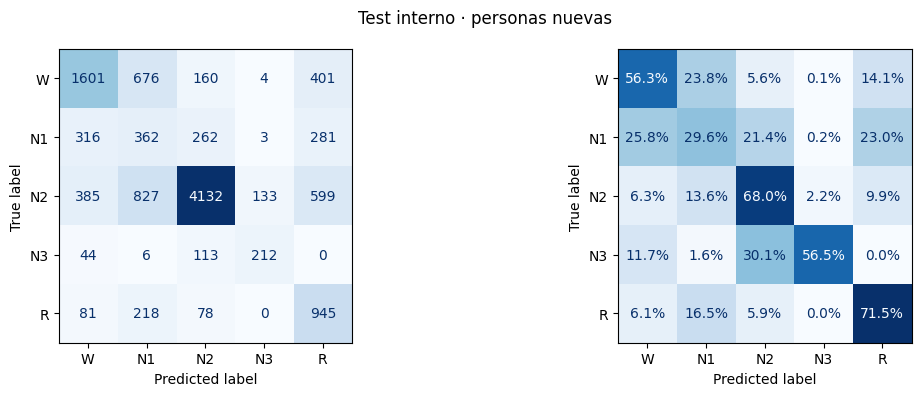

In [4]:
mostrar_errores_final(RESULTADO_FINAL)

### 4.8.4. Precision-Recall y Average Precision
Cada etapa contra el resto. Precisión frente a recuperación al variar el umbral, referencia horizontal de prevalencia y AP. Argmax marca la decisión multiclase congelada; no se optimizan umbrales con test.

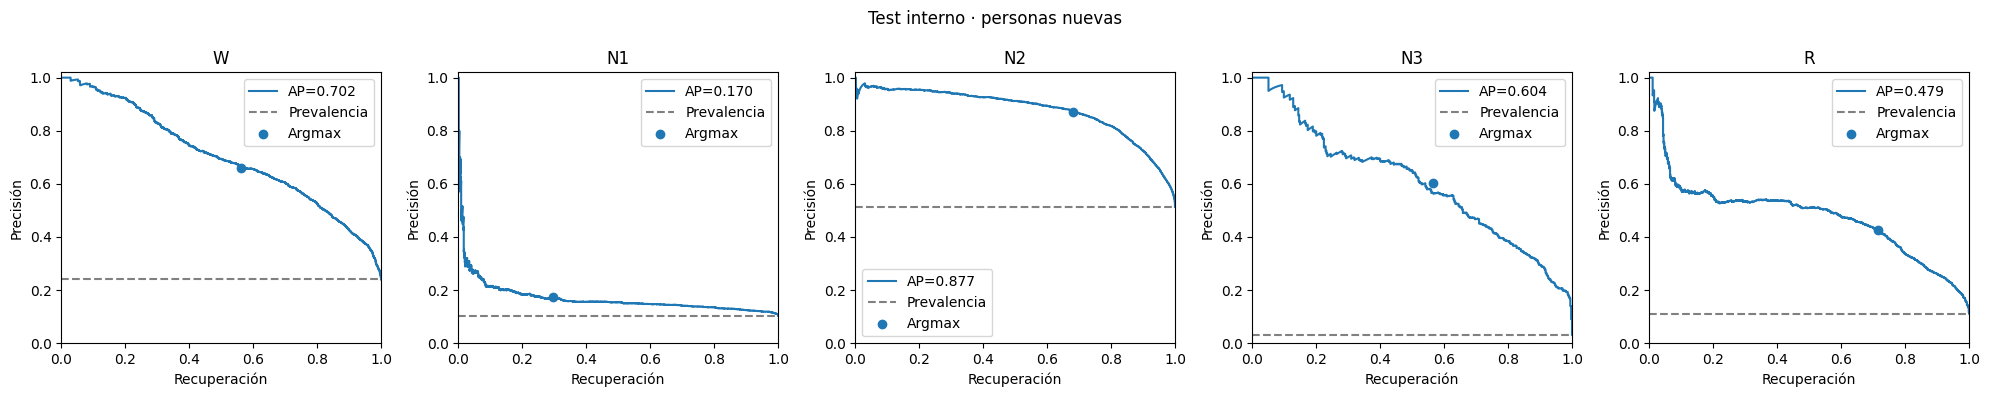

Etapa,AP
W,0.7021
N1,0.1699
N2,0.8774
N3,0.6036
R,0.4794


In [5]:
mostrar_curvas_final(RESULTADO_FINAL,'pr')

### 4.8.5. ROC y ROC-AUC
Diagnóstico complementario a PR. Una ROC-AUC alta no reemplaza precisión y recuperación de una etapa minoritaria.

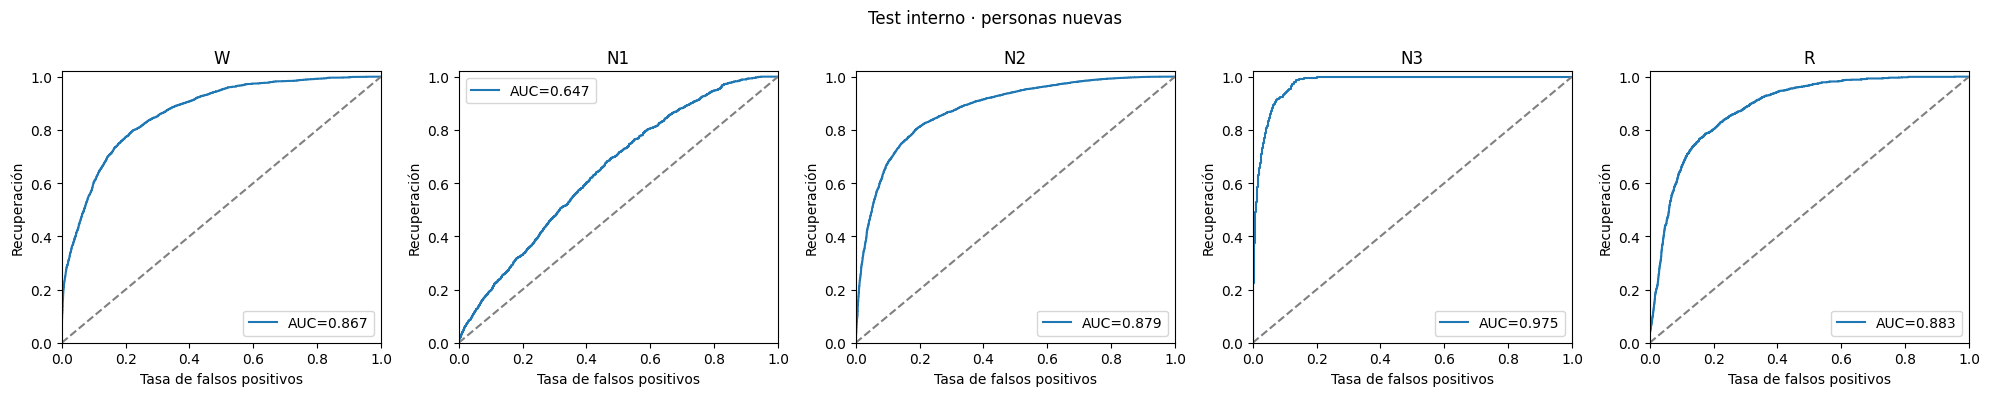

Etapa,ROC-AUC
W,0.8669
N1,0.6471
N2,0.8787
N3,0.9746
R,0.8833


In [6]:
mostrar_curvas_final(RESULTADO_FINAL,'roc')

### 4.8.6. Resultados por paciente
F1 con cinco etapas fijas y cobertura informada. Las personas tienen diferente duración y presencia de etapas; ausencia de clases limita su comparación. Se muestra todo el test: 16 pacientes.

In [7]:
PACIENTES_TEST_FINAL = pd.read_csv(DIRECTORIO_FINAL/'test_final/pacientes_test.csv')
tabla_final(PACIENTES_TEST_FINAL.sort_values('f1_macro_5_etapas').rename(columns={
    'patient_id':'Paciente','epochs':'Epochs','etapas_presentes':'Etapas presentes',
    'f1_macro_5_etapas':'F1 macro (5 etapas)','exactitud':'Exactitud'}))
tabla_final(PACIENTES_TEST_FINAL[['f1_macro_5_etapas','exactitud']].agg(['mean','std','min','max']),
    'Dispersión entre pacientes — no equivale al agregado por epoch')

,Paciente,Epochs,Etapas presentes,F1 macro (5 etapas),Exactitud
13,83,731,4,0.1913,0.3748
14,85,616,4,0.2351,0.3425
12,67,821,4,0.3433,0.3800
1,6,801,4,0.3926,0.5431
0,2,652,4,0.4011,0.5874
9,50,696,5,0.4118,0.8750
10,53,756,4,0.4210,0.5939
15,88,713,4,0.4303,0.5891
11,56,809,4,0.4372,0.6823
2,12,843,4,0.4539,0.6394


**Dispersión entre pacientes — no equivale al agregado por epoch**

,f1_macro_5_etapas,exactitud
mean,0.4288,0.6121
std,0.1117,0.1475
min,0.1913,0.3425
max,0.6369,0.8750


### 4.8.7. Evolución y comparación validación–test
Se conservan las decisiones de desarrollo. Los resultados históricos sobre 76 pacientes no son una réplica de la validación actual sobre 60; se identifican por separado. Validación y test no se promedian. Las diferencias se describen, sin nuevos ajustes.

In [8]:
EVOLUCION_FINAL = pd.DataFrame(PLANTILLA_FINAL['evolucion'] + [dict(etapa='Modelo congelado',
    conjunto='Test · 16 personas nuevas',f1_macro=RESULTADO_FINAL['metricas']['f1_macro'],
    desviacion=np.nan,exactitud=RESULTADO_FINAL['metricas']['exactitud'])])
tabla_final(EVOLUCION_FINAL.rename(columns={'etapa':'Paso','conjunto':'Evaluación','f1_macro':'F1 macro',
    'desviacion':'Desviación entre folds','exactitud':'Exactitud'}))
tabla_final(pd.DataFrame([{'Referencia':'XGBoost ponderado anterior','Cohorte':'76 pacientes · sin test reservado',
    'F1 macro':0.4923,'Desviación entre folds':0.0217,'Exactitud':0.5921}]),
    'Antecedente histórico — otra partición; no atribuir diferencias solo al modelo')
etapas_cv = pd.DataFrame(PLANTILLA_FINAL['referencia_validacion']['por_etapa']).T
etapas_test = pd.read_csv(DIRECTORIO_FINAL/'test_final/etapas_test.csv').set_index('etapa')
comparacion = pd.DataFrame({'F1 validación (media folds)':etapas_cv.f1,
    'F1 test (agregado)':etapas_test.f1,'Precisión test':etapas_test.precision,
    'Recuperación test':etapas_test.recuperacion,'Soporte test':etapas_test.soporte}).reindex(PLANTILLA_FINAL['etapas'])
tabla_final(comparacion,'Comparación por etapa')
diferencia = RESULTADO_FINAL['metricas']['f1_macro'] - PLANTILLA_FINAL['referencia_validacion']['f1_macro']
print(f'F1 test menos validación: {diferencia:+.4f}. Son evaluaciones distintas; no es efecto causal ni prueba de superioridad.')
debil = etapas_test.f1.idxmin()
print(f'Etapa de menor F1 en test: {debil} ({etapas_test.loc[debil,"f1"]:.4f}). No se reajusta el modelo con este resultado.')

Paso,Evaluación,F1 macro,Desviación entre folds,Exactitud
Referencia ponderada,Validación por pacientes · 60 personas,0.4859,0.0299,0.5867
Ajuste: reg_lambda=5,Validación por pacientes · 60 personas,0.4907,0.0327,0.5899
Historia de 1+2 minutos,Validación por pacientes · 60 personas,0.5053,0.0265,0.6043
Modelo congelado,Test · 16 personas nuevas,0.5412,—,0.6126


**Antecedente histórico — otra partición; no atribuir diferencias solo al modelo**

Referencia,Cohorte,F1 macro,Desviación entre folds,Exactitud
XGBoost ponderado anterior,76 pacientes · sin test reservado,0.4923,0.0217,0.5921


**Comparación por etapa**

,F1 validación (media folds),F1 test (agregado),Precisión test,Recuperación test,Soporte test
W,0.5757,0.6077,0.6597,0.5633,2842
N1,0.2411,0.2185,0.1733,0.2958,1224
N2,0.7657,0.7637,0.8708,0.6801,6076
N3,0.4999,0.5832,0.6023,0.5653,375
R,0.4442,0.5327,0.4245,0.7148,1322


F1 test menos validación: +0.0358. Son evaluaciones distintas; no es efecto causal ni prueba de superioridad.
Etapa de menor F1 en test: N1 (0.2185). No se reajusta el modelo con este resultado.


## 4.9. Conclusiones y limitaciones

| Selección | Algoritmo | Pesos | Historia (min) | Entradas | F1 validación ± DE | F1 test | Exactitud test |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Pacientes separados | XGB | Sí | [1, 2] | 68 | 0,5053 ± 0,0265 | 0,5412 | 0,6126 |
| Epochs mezclados | RF | No | Sin historia | 22 | 0,8006 ± 0,0038 | 0,4985 | 0,6278 |

En los mismos 16 pacientes, el candidato seleccionado mediante **pacientes separados** obtuvo el mayor F1 macro. Diferencia epochs menos pacientes: **-0,0426**. Las validaciones no se comparan como si midieran generalización equivalente. La diferencia en test corresponde a estos candidatos concretos; pueden cambiar algoritmo, entradas y parámetros además del protocolo. No se realizaron reajustes posteriores.

| Protocolo | Prueba | Mejor variante observada | F1 referencia | F1 variante | Diferencia | Brecha | Entrenamiento 5 folds (s) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Pacientes separados | Contexto temporal | Historia 1+2 minutos (dos mejores individuales) | 0,4907 | 0,5053 | 0,0147 | 0,3010 | 12,1839 |
| Pacientes separados | SMOTE | SMOTE objetivo 100% de mayoritaria; k=3 | 0,4451 | 0,4860 | 0,0409 | 0,2911 | 12,7084 |
| Epochs mezclados | Contexto temporal | Historia 15 minutos | 0,7860 | 0,7888 | 0,0029 | 0,1777 | 13,6455 |
| Epochs mezclados | SMOTE | SMOTE objetivo 100% de mayoritaria; k=5 | 0,7645 | 0,8006 | 0,0360 | 0,1947 | 38,1493 |

- **Pacientes separados:** menor F1 en N1: 0,2185, precisión 0,1733, recuperación 0,2958. F1 individual entre 0,1913 y 0,6369; 11/16 personas sin las cinco etapas observadas. No afirmar buen reconocimiento uniforme.
- **Epochs mezclados:** menor F1 en N1: 0,2048, precisión 0,1789, recuperación 0,2394. F1 individual entre 0,2137 y 0,5493; 11/16 personas sin las cinco etapas observadas. No afirmar buen reconocimiento uniforme.

El test ya había sido consultado y tuvo exposición histórica en EDA/comparaciones de la cohorte completa. Esta es una comparación posterior sobre personas excluidas de los nuevos entrenamientos, **no una nueva prueba independiente**. No se usó para seleccionar ni reajustar los candidatos de esta ronda. La selección entre muchas pruebas puede optimizar en exceso la validación.

Al mezclar epochs se comparten personas y observaciones próximas. Con historia, un antecedente puede contener señales de otro fold; no contiene su etiqueta, pero la dependencia puede favorecer las métricas. Las etapas ausentes y las distintas duraciones limitan comparaciones individuales. Los modelos utilizan wearable + PSG; no demuestran rendimiento solo wearable.

La guía documenta 65 comparaciones ejecutadas y el informe integra las decisiones para exponer.
La búsqueda se mantuvo acotada; no se agregaron hiperparámetros ni SMOTE con historia.
4.8 conserva exactamente código, salidas y contadores históricos y no fue ejecutada.
La comparación actual está terminada; una evaluación externa sería una ampliación futura.

### Interpretación final para exposición

XGBoost obtuvo F1 macro de test 0,5412 frente a 0,4985 de RF, aunque RF tuvo mayor exactitud (0,6278 frente a 0,6126). La validación por pacientes ya exigía predecir personas excluidas del entrenamiento; mezclar epochs permitía compartir personas y observaciones próximas. Esa diferencia ayuda a entender por qué la validación mezclada fue más favorable, pero no demuestra que el protocolo sea la única causa del resultado: también cambiaron algoritmo, regularización, ponderación, historia y SMOTE. La importancia describe al XGBoost, no prueba por qué superó a RF.

La mayor caída media correspondió al grupo **actuales** (0,2306). Los antecedentes de un minuto y dos minutos tuvieron caídas medias 0,0476 y 0,0218; describen dependencia del modelo, no una mejora garantizada al agregarlos. Los indicadores de disponibilidad tuvieron caída media 0,0006. Las desviaciones reflejan variación entre folds; no constituyen una prueba estadística de superioridad entre grupos.

Entre las entradas individuales destacadas aparecen `EOG_max_std`, `C4-M1_std`, `CHIN_std`, `F4-M1_std`, `CZ - T4_std`. La historia y los indicadores se interpretan con las limitaciones de correlación y dispersión entre folds; no como contribuciones causales ni porcentajes explicados.

N1 sigue siendo débil: F1 0,2185, precisión 0,1733 y recuperación 0,2958. El F1 por persona varía entre 0,1913 y 0,6369; la cobertura de etapas limita comparaciones individuales. El test tuvo exposición histórica y no constituye una nueva evaluación independiente.

Las pruebas históricas de parámetros se recuperaron como explicación, sin ampliar la búsqueda ni cambiar la selección. La importancia reentrenó solo el candidato fijo en desarrollo; 4.7/4.8 y sus resultados se conservaron.
